In [1]:
#if fresh enviornment, in terminal
'''
chmod +x dependencies.sh
./dependencies.sh
'''
import sys
print(sys.executable)

/home/ec2-user/anaconda3/envs/python3/bin/python


In [2]:
# Install dependencies
packages = [
    "transformers",
    "datasets",
    "iterative-stratification",
    "seaborn",
    "matplotlib",
    "nltk",
    "torch",
    "ftfy",
    "Levenshtein",
    "sentencepiece",
    "sacremoses",
    "peft",
]

!pip install -q {" ".join(packages)} > /dev/null 2>&1

In [3]:
# Standard library
import copy
import gc
import glob
import itertools
import json
import math
import os
import random
import re
import warnings
from collections import Counter
import time

# Data processing
import ftfy
import Levenshtein
import numpy as np
import pandas as pd


# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display


# NLP
import nltk
from nltk.corpus import wordnet
from nltk.tokenize.punkt import PunktSentenceTokenizer


# Scikit-learn
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, f1_score
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MultiLabelBinarizer
import copy
import zlib
from torch.utils.data import ConcatDataset



# Multilabel stratified splitting
from iterstrat.ml_stratifiers import (
    MultilabelStratifiedKFold,
    MultilabelStratifiedShuffleSplit as MSSS,
)


# PyTorch
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset, Subset
import itertools
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from sklearn.manifold import TSNE

# Transformers
from transformers import (
    AutoConfig,
    AutoModel,
    AutoModelForSeq2SeqLM,
    AutoModelForSequenceClassification,
    AutoTokenizer,
    RobertaModel,
    RobertaPreTrainedModel,
    RobertaTokenizerFast,
)
from transformers import get_linear_schedule_with_warmup

from transformers.models.roberta.modeling_roberta import (
    RobertaClassificationHead,
)

from transformers.utils import logging as transformers_logging
from torch.utils.data import ConcatDataset

# PEFT / LoRA
from peft import LoraConfig, TaskType, get_peft_model


# Suppress Transformers output
transformers_logging.set_verbosity_error()
transformers_logging.disable_progress_bar()


# Suppress Hugging Face Hub progress bars
try:
    from huggingface_hub import disable_progress_bars
    disable_progress_bars()
except ImportError:
    pass


# Suppress warnings
warnings.filterwarnings("ignore")


# Download required NLTK data
nltk.download("averaged_perceptron_tagger_eng", quiet=True)
nltk.download("averaged_perceptron_tagger", quiet=True)
nltk.download("punkt_tab", quiet=True)
nltk.download("punkt", quiet=True)
nltk.download("wordnet", quiet=True)

/home/ec2-user/anaconda3/envs/python3/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


True

In [4]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')

Using device: cuda


### [1] load data: training_set_task1.txt into df_part_a

In [5]:

#load the json training_set_task1.txt
with open("training_set_task1.txt", "r", encoding="utf-8") as f:
    data = json.load(f)

#load into pandas DataFrame
df_part_a = pd.DataFrame(data)

# Count using pandas (if 'labels' is a column containing lists)
empty_label_count = df_part_a["labels"].apply(lambda x: len(x) == 0).sum()

#save entries with empty labels into a seperate DF for checking
empty_labels_df = df_part_a[df_part_a["labels"].map(len) == 0].copy()

#Kepp at entries, empty_labels_df is kept only for inspection
df_part_a = df_part_a.reset_index(drop=True)

print(f"Total entries in df_part_a: {len(df_part_a)}")
print(f"  with at least one label: {(df_part_a['labels'].map(len) > 0).sum()}")
print(f"  with no labels:          {len(empty_labels_df)}")


Total entries in df_part_a: 688
  with at least one label: 545
  with no labels:          143


### [2] load data: training_set_task2.txt into df_part_b

In [6]:
# Load Task 2 JSON: training set + dev set joined into one training pool
with open("training_set_task2.txt", "r", encoding="utf-8") as f:
    data_train = json.load(f)
with open("dev_set_task2.txt", "r", encoding="utf-8") as f:
    data_dev = json.load(f)

#one dev meme repeats a training meme word for word: keep only the training copy
train_texts = {m["text"].strip() for m in data_train}
dev_new = [m for m in data_dev if m["text"].strip() not in train_texts]
data = data_train + dev_new
print(f"training {len(data_train)} + dev {len(dev_new)} "
      f"({len(data_dev) - len(dev_new)} duplicate dropped) = {len(data)} memes")

training 688 + dev 62 (1 duplicate dropped) = 750 memes


* There was a duplicate entry in the dev_set which was dropped so that all samples are unique.
* Task_2 samples are used as it comprises all the information found in Task_1 data only it also includes the spans.

In [7]:


# Extract unique techniques and construct class mappings
unique_techniques = set(label["technique"] for item in data for label in item.get("labels", []))
techniques_list = sorted(list(unique_techniques))
label2id = {label: idx for idx, label in enumerate(techniques_list)}
CLASSES = techniques_list

# Build a list of dictionary records
records = []
for item in data:
    spans = []
    doc_label_vector = [0.0] * len(techniques_list)

    for label in item.get("labels", []):
        tech_idx = label2id[label["technique"]]
        spans.append({
            "start": label["start"],
            "end": label["end"],
            "technique": label["technique"],
            "class_id": tech_idx
        })
        doc_label_vector[tech_idx] = 1.0

    records.append({
        "id": item.get("id"),  # Retains 'id' if present in the source JSON
        "text": item["text"],
        "labels": spans,
        "doc_level_labels": doc_label_vector
    })

# Load into DataFrame
df_part_b = pd.DataFrame(records)

# Check entries with empty labels
empty_label_count = df_part_b["labels"].apply(lambda x: len(x) == 0).sum()
empty_labels_df = df_part_b[df_part_b["labels"].map(len) == 0].copy()

df_part_b = df_part_b.reset_index(drop=True)

# Print summary
print(f"Total entries in df_part_b: {len(df_part_b)}")
print(f"  with at least one label: {(df_part_b['labels'].map(len) > 0).sum()}")
print(f"  with no labels:          {len(empty_labels_df)}")

Total entries in df_part_b: 750
  with at least one label: 593
  with no labels:          157


* The number of samples for the training set is quite small at only 750

In [8]:
#compare training_set_task1 to training_set_task2 to see if there is any differnce in the data between the two
t1 = {str(m["id"]): m for m in json.load(open("training_set_task1.txt", encoding="utf-8"))}
t2 = {str(m["id"]): m for m in json.load(open("training_set_task2.txt", encoding="utf-8"))}

only1, only2 = set(t1) - set(t2), set(t2) - set(t1)
both = set(t1) & set(t2)
text_diff = [i for i in both if t1[i]["text"] != t2[i]["text"]]
label_diff = [i for i in both
              if sorted(set(t1[i]["labels"])) != sorted({l["technique"] for l in t2[i]["labels"]})]

print(f"Task 1: {len(t1)} memes | Task 2: {len(t2)} memes | in both: {len(both)}")
print(f"Only in Task 1: {len(only1)} {sorted(only1)[:5]}")
print(f"Only in Task 2: {len(only2)} {sorted(only2)[:5]}")
print(f"Same id, different text:   {len(text_diff)} {text_diff[:5]}")
print(f"Same id, different labels: {len(label_diff)} {label_diff[:5]}")
for i in label_diff[:3]:
    print(i, "| T1:", sorted(set(t1[i]["labels"])), "| T2:", sorted({l['technique'] for l in t2[i]['labels']}))

Task 1: 688 memes | Task 2: 688 memes | in both: 688
Only in Task 1: 0 []
Only in Task 2: 0 []
Same id, different text:   0 []
Same id, different labels: 0 []


### Notes
 *  Both training_set_task1.txt and training_set_task2.txt sets of data have the same ids, so they are of the same data.
 *  That means that there are only 688 uniques ids of data for the model to train from. Of the 688 entries, 143 have no labels.
 *  It may make sense to to have one encoder with two heads - one for each model part
   *    Only 688 entries is a very small data set to train the model on. Given that the data set is small transfer learning is appropiete to improve the model in this case
   *    Having only one model saves on the computer processing as a single T4 with 16GB GPU is all that can be used
   *    The doc head can look at the entire meme to decide if the meme has probablity of a certain label (for Part A)
   *    The token head can identify which words make up the label (for Part B)
   *    Where the two heads disagree they can be measured to identify how often
* **Architecture**: one shared RoBERTa-base encoder with two heads on top, trained together.
   * **Self-built segment (designed and tuned here)**: a learned *attention pooling* layer (`AttentionPooling` in [7]) that scores every token and averages the token vectors with those weights, and the *two-head joint objective* below, including the masking of labels that are unknown for a training example. The pooling search [11] compares attention pooling with `cls` and `mean` on the same folds; λ is tuned in [10d].
   * **Doc head (Part A)**: pooled meme vector → RoBERTa's standard classification head (Linear → tanh → Linear) → 20 sigmoid outputs, one per technique.
   * **Token head (Part B)**: Dropout + Linear on every token vector → 20 sigmoid outputs per token. Because each technique has its own sigmoid, the same words can carry several techniques at once (multi-label sequence tagging).
   * Loss: `L = BCE_doc + λ · BCE_token`, both with class weights (`pos_weight`). λ = 0 switches the span task off, which tests whether learning the spans helps Part A.


C1:
The training dataset sourced from Dimitrov et al. (2021) has a political skew, with 23 of the 26 Facebook groups being US and Canadian political groups (“left, right, centered, antigovernment, and gun control”). The other three groups covered health, COVID-19, vaccines, and gender equality (Appendix A.1). Therefore, the dataset is US and Canadian-centric and English-only. As the data was collected at a particular point in time, it may also be skewed towards the issues and topics that were relevant at the time.

As the model is trained on this data, the same biases and representations may be reflected in its classification of propaganda techniques. Furthermore, the model may not transfer well to memes created by high school students in 2026, who may focus on different issues and use different forms of expression. As a result, the model's performance may differ when applied to this new context.


In [9]:
labels = df_part_b["labels"].apply(
    lambda x: x[0]['technique'] if len(x) and isinstance(x[0], dict)
    else (x[0] if len(x) else "(no technique)")
)

print(df_part_b[["text", "labels"]].head())
print(labels.value_counts().sort_index())
print(labels.unique())

                                                text  \
0    THERE ARE ONLY TWO GENDERS\n\nFEMALE \n\nMALE\n   
1                           This is not an accident!   
2  SO BERNIE BROS HAVEN'T COMMITTED VIOLENCE EH?\...   
3  PATHETIC\n\nThe Cowardly Asshole\nWeak Failure...   
4  WHO TRUMP REPRESENTS\n\nWHO DEMOCRATS REPRESENT\n   

                                              labels  
0  [{'start': 0, 'end': 41, 'technique': 'Black-a...  
1                                                 []  
2  [{'start': 47, 'end': 83, 'technique': 'Slogan...  
3  [{'start': 0, 'end': 8, 'technique': 'Loaded L...  
4                                                 []  
labels
(no technique)                                         157
Appeal to authority                                     12
Appeal to fear/prejudice                                14
Bandwagon                                                2
Black-and-white Fallacy/Dictatorship                    10
Causal Oversimplification      

In [10]:
# Class weights for imbalanced data

#get all the labels
all_labels = [
    item['technique'] if isinstance(item, dict) else item
    for sublist in df_part_b["labels"]
    for item in sublist
]

#extract a list of unique labels, sorted
label_names = sorted(list(set(all_labels)))
#get number of classes
NUM_CLASSES = len(label_names)

#give class count
class_counts = Counter(all_labels)

#compute inverse frequency weights
total_occurrences = len(all_labels)
#iterate through 'label_names'
class_weights = torch.tensor(
    [total_occurrences / max(1, class_counts.get(name, 0)) for name in label_names],
    dtype=torch.float32
).to(device)

#normalize weights so they average to 1.0
class_weights = class_weights / class_weights.sum() * NUM_CLASSES

#formatted results
print('Class weights (inverse frequency):')
for i, name in enumerate(label_names):
    print(f'  {name}: {class_weights[i].item():.2f}')


Class weights (inverse frequency):
  Appeal to authority: 0.66
  Appeal to fear/prejudice: 0.20
  Bandwagon: 2.47
  Black-and-white Fallacy/Dictatorship: 0.55
  Causal Oversimplification: 0.33
  Doubt: 0.17
  Exaggeration/Minimisation: 0.15
  Flag-waving: 0.26
  Glittering generalities (Virtue): 0.29
  Loaded Language: 0.02
  Misrepresentation of Someone's Position (Straw Man): 0.43
  Name calling/Labeling: 0.03
  Obfuscation, Intentional vagueness, Confusion: 2.47
  Presenting Irrelevant Data (Red Herring): 9.86
  Reductio ad hitlerum: 0.99
  Repetition: 0.24
  Slogans: 0.19
  Smears: 0.04
  Thought-terminating cliché: 0.45
  Whataboutism: 0.22


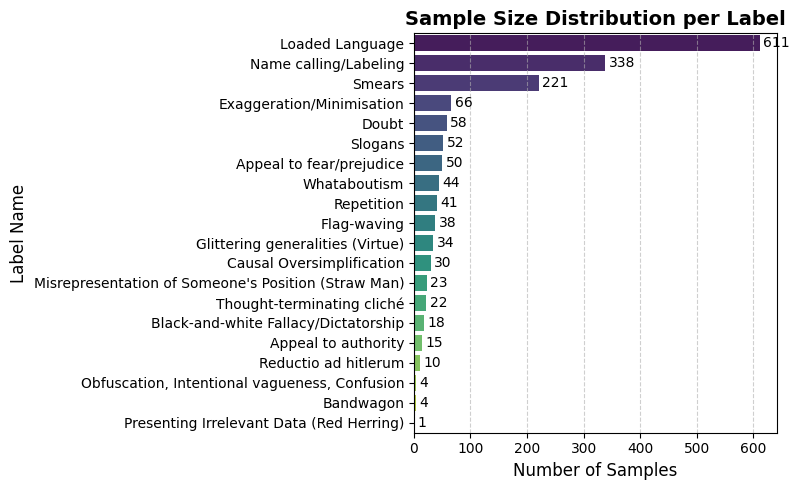

In [11]:
# Extract labels and counts sorted by frequency
sorted_counts = sorted(class_counts.items(), key=lambda x: x[1], reverse=True)
labels, counts = zip(*sorted_counts)

# Create plot
#plt.figure(figsize=(10, len(labels) * 0.4 + 2))
plt.figure(figsize=(8, 5))
sns.barplot(x=list(counts), y=list(labels), hue=list(labels), palette="viridis", legend=False)

plt.xlabel("Number of Samples", fontsize=12)
plt.ylabel("Label Name", fontsize=12)
plt.title("Sample Size Distribution per Label", fontsize=14, fontweight="bold")
plt.grid(axis="x", linestyle="--", alpha=0.6)

# Annotate bars with exact counts
for index, count in enumerate(counts):
    plt.text(count + (max(counts) * 0.01), index, f"{count:,}", va="center", fontsize=10)

plt.tight_layout()
plt.show()

* The majority of labels are of technique "Loaded Language" , we can see that the datasets are very imbalanced

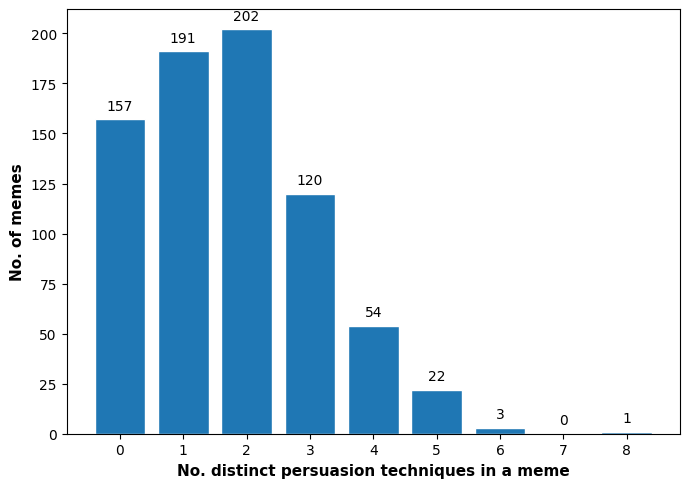

In [12]:
### for Task 1 ###
#get distinct techniques

distinct_counts = df_part_b['labels'].apply(
    lambda x: len({item['technique'] if isinstance(item, dict) else item for item in x})
    if isinstance(x, (list, set, tuple)) else (1 if pd.notna(x) else 0)
)

# Frequency distribution
distribution = distinct_counts.value_counts()

#freq distr
distribution = distinct_counts.value_counts()

max_techniques = distribution.index.max() if len(distribution) > 0 else 0
distribution = distribution.reindex(range(0, max_techniques + 1), fill_value=0)

#chart
x_values = distribution.index
y_values = distribution.values
plt.figure(figsize=(7, 5))
bars = plt.bar(x_values, y_values, color='#1f77b4', edgecolor='white')
#format labels
plt.xlabel("No. distinct persuasion techniques in a meme", fontsize=11, fontweight="bold")
plt.ylabel("No. of memes", fontsize=11, fontweight="bold")
plt.xticks(x_values)
# show counts for each bar
max_y = max(y_values) if len(y_values) > 0 else 1
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + (max_y * 0.015),
        f"{int(height)}",
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.tight_layout()
plt.show()



* Looking at the samples from each category, the task requires contextual understanding, where the order of the words matters, rather than simple keyword matching. Therefore, a Bag-of-Words approach may not be suitable, as it does not capture the relationships between words. A self-attention approach can better capture these contextual relationships and dependencies within the text. A transformer approach would be ideal.

* Given that there are only 545 training samples, using a model pre-trained on a large text corpus would be beneficial. A pre-trained model should be able to  capture aspects of grammar and sentiment, reducing the amount of data that is required to learn these patterns compared with training a model from scratch.

* Furthermore, to maximise performance given the small dataset, 5-fold cross-validation can be used. MultilabelStratifiedKFold divides the dataset into five folds while maintaining a similar distribution of the rare classes across each fold. Five separate model instances are then trained, with each model using four folds for training and the remaining fold for validation. The predictions from the five models can then be averaged to produce the final prediction.


* There is large label disparity.. The dataset is imbalanced, with labels such as "Loaded Language", "Name Calling/Labeling" and "Smears" accounting for a large proportion of the training samples with > than 25% of the samples, labels like Bandwagon, Irrelevant Data, and Confusion are present in less than 2% of the data. As a result, standard Binary Cross-Entropy (BCE) may not adequately account for underrepresented positive labels, potentially leading to poorer performance with the minority classes. Therefore, Weighted Binary Cross-Entropy (Weighted BCE) can be used to address this imbalance by assigning higher weights to positive instances of less frequent classes, with weights inversely proportional to their frequency. This helps the model put greater weight on learning under-represented labels.

* Because the class distribution is imbalanced, Macro F1 will be used as the primary evaluation metric, as it assigns equal importance to each class and therefore provides greater sensitivity to performance on minority classes. In contrast, Micro F1 aggregates true positives, false positives, and false negatives across all classes, meaning that its score is influenced more heavily by the majority classes. Therefore, Micro F1 will be used as a supplementary metric to Macro F1 to provide additional insight into overall performance across the observed class distribution.

* From the current bechmark from, Dimitrov et al. (2021):
   * For Task 1. Team MinD archieved a F1-Micro score of .593 and .290 so this model should at least archieve the same benchmark score.
   * For Task 2. Team Volta archieved for F1: .482, Precision: .501, Recall: .464.
   * MinD did not compete on Task 2, only on Task 1 and Task 3. Volta archieved the best combination of both Task 1 and Task 2 with F1-Micro: .570 and F1-Macro .266
   * For these experiments the benchmark for both Tasks will be:
      * Task 1: F1-Micro: .570 and F1-Macro .266
      * Task 2: F1: .482, Precision: .501, Recall: .464.

* Dimitrov et al. (2021) mentions that there are biases in the training data:
That there are sizable disparities in the frequency of different techniques accross the data set.
The data set was sourced to 26 specific facebook groups, that were heavily focused on the politcics, pandamic, vaccines and gender equality. The uses of this solution may not use the same techniques or types of memes, if we solely train the model only on the SemEval-2021 Task 6 training samples.

* As the dataset may not accurately represent the data that users are likely to generate in real-world scenarios, using a pre-trained model may improve generalisation by leveraging representations learned from a broader and more diverse dataset than the available training set.

* Augmentation was used by some teams in (Dimitrov et al., 2021):
  * Such as by Team LIIR which used paraphrased augmentations of the orginal meme with back tranlsation where the text is translated to another language and then back again.
  * Team LeCun (Da San Martino et al., 2020) merged the data set with the additional external news/text propaganda dataset, aswell as multi step back translation between English, Dutch, Russian and English - thr process from (Daval-Frerot & Weis, 2020). A Clear back translation process is mentioned by Team LIIR (Ghadery et al., 2021) where they paraphrased each original sentence by translating it into a target language and then translating it back to the original language, English to German and back again.

* Becuase the data set is small to increase the size, the PTC corpus ( which has more than 20,000 sentences) from SemEval-2020 task 11 (Da San Martino et al., 2020) can be included. It was used in MinD ensamble approach (Tian et al., 2021). A subset of the data was retrived from (https://zenodo.org/records/3952415). MinD uses a process (sentence-level annotations) where they extract the label sample from the article with the start and end positions.

* For Task 1 (Gupta et al., 2021) Volta uses transfer learning with small and large variants of models - BERT and RoBERTa.

* For Task 1 (Tian et al., 2021) MinD uses transfer learninig with pretrained model RoBERTa, that has the advantage of dynamic masking and Byte-Pair Encoding (BPE) (Sennrich et al., 2016), it archieves a F1-Micro score of 0.6478 on the dev data set. They however use an ensemble by averaging the predictions across RoBERTa, XLNet, DeBERTa, and ALBERT for Task 1.




In [13]:
print(df_part_b.head())

    id                                               text  \
0  128    THERE ARE ONLY TWO GENDERS\n\nFEMALE \n\nMALE\n   
1  189                           This is not an accident!   
2   96  SO BERNIE BROS HAVEN'T COMMITTED VIOLENCE EH?\...   
3  154  PATHETIC\n\nThe Cowardly Asshole\nWeak Failure...   
4   15  WHO TRUMP REPRESENTS\n\nWHO DEMOCRATS REPRESENT\n   

                                              labels  \
0  [{'start': 0, 'end': 41, 'technique': 'Black-a...   
1                                                 []   
2  [{'start': 47, 'end': 83, 'technique': 'Slogan...   
3  [{'start': 0, 'end': 8, 'technique': 'Loaded L...   
4                                                 []   

                                    doc_level_labels  
0  [0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...  
1  [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...  
2  [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...  
3  [0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, ...  
4  [0.0, 0.0, 0.0, 0.

In [14]:
# Valid class headings
df_labels = [
    "Appeal to authority",
    "Appeal to fear/prejudice",
    "Black-and-white Fallacy/Dictatorship",
    "Causal Oversimplification",
    "Doubt",
    "Exaggeration/Minimisation",
    "Flag-waving",
    "Glittering generalities (Virtue)",
    "Loaded Language",
    "Misrepresentation of Someone's Position (Straw Man)",
    "Name calling/Labeling",
    "Obfuscation, Intentional vagueness, Confusion",
    "Presenting Irrelevant Data (Red Herring)",
    "Reductio ad hitlerum",
    "Repetition",
    "Slogans",
    "Smears",
    "Thought-terminating cliché",
    "Whataboutism",
    "Bandwagon",
    "Transfer",
    "Appeal to (Strong) Emotions"
]
label_lookup = {label: label for label in df_labels}

In [15]:
#show the class counts of DF (training_set_task1.txt)
label_counts = (
    df_part_b["labels"]
    .dropna()
    .explode()
    # Step 1: Extract string from dict (change 'technique' if your key is different)
    .map(lambda x: x.get('technique') if isinstance(x, dict) else x)
    # Step 2: Look up mapped label name
    .map(lambda x: label_lookup.get(x, x))
    .dropna()
    .value_counts()
    .reindex(df_labels, fill_value=0)
)

print(label_counts)

labels
Appeal to authority                                     15
Appeal to fear/prejudice                                50
Black-and-white Fallacy/Dictatorship                    18
Causal Oversimplification                               30
Doubt                                                   58
Exaggeration/Minimisation                               66
Flag-waving                                             38
Glittering generalities (Virtue)                        34
Loaded Language                                        611
Misrepresentation of Someone's Position (Straw Man)     23
Name calling/Labeling                                  338
Obfuscation, Intentional vagueness, Confusion            4
Presenting Irrelevant Data (Red Herring)                 1
Reductio ad hitlerum                                    10
Repetition                                              41
Slogans                                                 52
Smears                                           

* Stratified splitting requires that there is at least 2 samples per class, the following classes only have a single sample:           1
   * Presenting Irrelevant Data (Red Herring)                 1    
* Data Augmentation can solve this and adding more samples, Adding the samples from the PTC data set for the to try and obtain a better balance        

In [16]:
#general seed used so that fixed random seed used through experiments won't change
SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


* Note: 
  * The following hyper_paramters were not fine tuned:
      * BATCH_SIZE is standard for RoBERTa fine-tuning and fits the T4 constraint
      * Number of folds is 5 which is standard for the size of the dataset
      * PATIENCE is set to 2 which is small enough Patience so that early stopping can be inacted
      * MAX_LENGTH is 160 which covers the longest meme

In [17]:
#[2]BASE LINE SETTINGS

MODEL_NAME = "roberta-base"
MAX_LENGTH = 160                          # As the longest meme is 142 tokens
K_FOLDS = 5                               # standard k folds of 5 given the data
BATCH_SIZE = 16                           #standard for bert style models, either 16 or 32, 16 will ensure enough steps, considering the size
THRESHOLDS = np.arange(0.05, 0.96, 0.05)  #candidate cut-offs for the sigmoid probabilities - the best is picked on validation (compensates for pos_weight)
TRACK_TRAIN_F1 = True                     #also score each fold's training memes every epoch (for train vs validation F1 plots)

P1_EPOCHS = 5                             # phase 1: heads only (encoder frozen) - as a baseline start 5 is appropiete
P2_EPOCHS = 5                             # phase 2: LoRA + heads  - as a baseline start 5 is appropiete
PATIENCE = 2     #small enough Patience so that early stopping can be inacted

all_results = {}                          # histories for plot_experiments
if "results_scores" not in globals():
    results_scores = {}

* The training set (training_set_task2.txt, 688 memes) and the dev set (dev_set_task2.txt, 63 memes) are joined into one training pool of 750 memes; one dev meme that repeats a training meme word for word is dropped. This gives the model about 9% more training examples. The dev set is too small to work well as a validation set on its own: with 63 memes, 3 of the 20 techniques do not appear at all and 9 appear in two memes or fewer, so validation scores, early stopping and threshold selection would rest on very few examples. Instead, validation uses 5-fold cross-validation over the joined pool, so every meme is used for validation once, and the official test set (test_set_task2.txt) is kept separate for the final evaluation in [13].

In [18]:
#[3] load training set and build the document labels from the spans

#the training_set_task2.txt and dev_set_task2.txt are joined because the dev_set_task2.txt only has 
data_task2 = data          #training + dev, joined in the "Load Task 2 JSON" cell

df2 = pd.DataFrame(data_task2)
df2["id"] = df2["id"].astype(str)

#the 20 techniques that can appear in the text (Transfer and Appeal to (Strong) Emotions are image-only)
TECHNIQUES = sorted({l["technique"] for item in data_task2 for l in item["labels"]})
label2id = {label: idx for idx, label in enumerate(TECHNIQUES)}
NUM_CLASSES = len(TECHNIQUES)
print(f"Number of techniques found in the spans: {NUM_CLASSES}")

#list of (start, end, technique) per meme
df2["spans"] = df2["labels"].apply(lambda ls: [(int(l["start"]), int(l["end"]), l["technique"]) for l in ls])

#document level label = every technique that has at least one span in the meme
df2["doc_labels"] = df2["spans"].apply(lambda sp: sorted({t for _, _, t in sp}))

Y = np.array([[1.0 if t in d else 0.0 for t in TECHNIQUES] for d in df2["doc_labels"]], dtype=np.float32)

#sanity check: the span offsets must point at the annotated text fragment
bad_offsets = 0
for item in data_task2:
    for l in item["labels"]:
        if "text_fragment" in l and item["text"][l["start"]:l["end"]] != l["text_fragment"]:
            bad_offsets += 1

print(f"Total memes:               {len(df2)}")
print(f"  with at least one span:  {(Y.sum(axis=1) > 0).sum()}")
print(f"  with no technique:       {(Y.sum(axis=1) == 0).sum()}")
print(f"Total span instances:      {df2['spans'].map(len).sum()}")
print(f"Spans whose offsets do not match text_fragment: {bad_offsets}")

Number of techniques found in the spans: 20
Total memes:               750
  with at least one span:  593
  with no technique:       157
Total span instances:      1680
Spans whose offsets do not match text_fragment: 0


In [19]:
#[4a] span statistics per technique: memes containing the technique vs number of span instances

span_counts = pd.Series([t for sp in df2["spans"] for _, _, t in sp]).value_counts().reindex(TECHNIQUES, fill_value=0)
meme_counts = pd.Series(Y.sum(axis=0).astype(int), index=TECHNIQUES)
span_len = pd.Series([e - s for sp in df2["spans"] for s, e, _ in sp])

span_table = pd.DataFrame({"memes. Part A": meme_counts, "span inst. Part B": span_counts})
span_table["spans per meme"] = (span_table["span inst. Part B"] / span_table["memes. Part A"].replace(0, np.nan)).round(2)
span_table = span_table.sort_values("memes. Part A", ascending=False)
display(span_table)

,memes. Part A,span inst. Part B,spans per meme
Loaded Language,389,611,1.57
Name calling/Labeling,247,338,1.37
Smears,218,221,1.01
Exaggeration/Minimisation,59,66,1.12
Doubt,56,58,1.04
Slogans,47,52,1.11
Appeal to fear/prejudice,47,50,1.06
Whataboutism,44,44,1.00
Glittering generalities (Virtue),33,34,1.03
Flag-waving,32,38,1.19


* the techniques are extremely unbalanced
* 3 techniques make the majority: Loaded Language (389 memes), Name calling (247) and Smears (218). Together they account about for around 70%.
* The model sees very few examples of rare techniques: Reductio ad hitlerum (10), Repetition (11), Obfuscation ... (4), Bandwagon (4) and Red Herring (1).

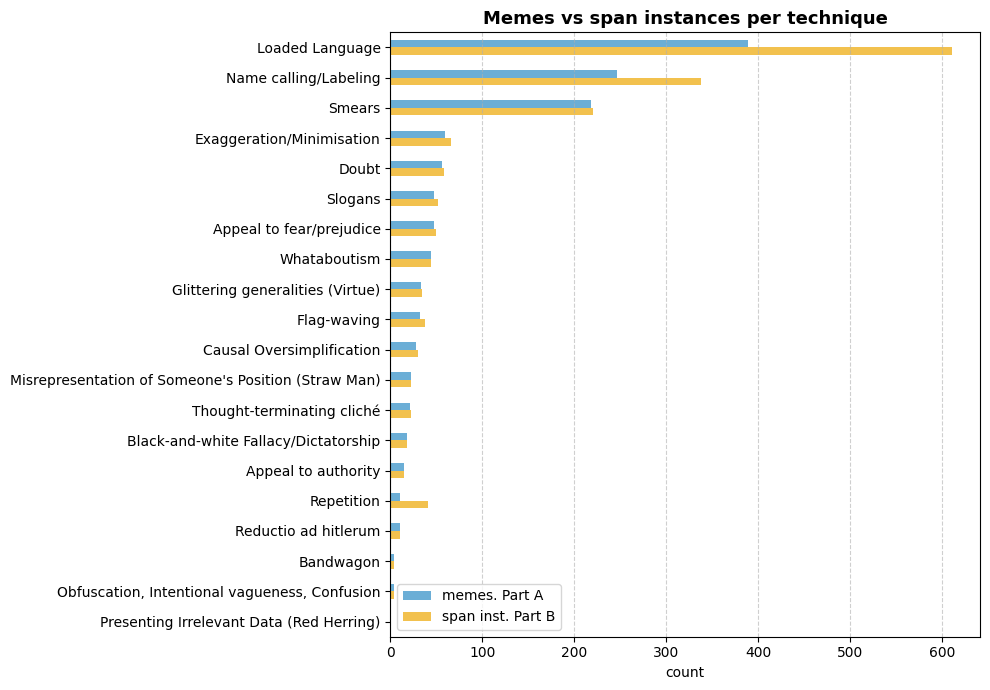

In [20]:
#[4b] span statistics per technique: memes containing the technique vs number of span instances
fig, ax = plt.subplots(figsize=(10, 7))
span_table[["memes. Part A", "span inst. Part B"]].plot.barh(ax=ax, color=["#6baed6", "#f2c14e"])
ax.invert_yaxis()                                  #most frequent technique at the top
ax.set_title("Memes vs span instances per technique", fontsize=13, fontweight="bold")
ax.set_xlabel("count")
ax.grid(axis="x", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()


In this chart the imbalance of data is prevalent. We can see that Loaded Language, Name calling... and Smears have the greatest proportion of memes and also the number of span instances. This is important to highlight as the training dataset shows a much greater skew that can be transfered to the model being trained.
* To counter this:
    * Weighted loss in training to make a missed rare technique cost more than a missed common one
    * Multilable stratified splits in training to keep technique proportions similar across folds
    * Early stopping on Macro-F1 + Span F1, so that the model rewards rare techniques

* Some techniques are used several times in the same meme for example: (id: 106: Loaded Language),
* Part B contains more instances than Part A contains memes, as some techniques such as: (Slogans and Doubt) span an entire sentence.
* Span lengths range from a single word to the entire meme, seems that the use of a token level prediction head that predicts each token rather than relying on a fixed length window.
```json
{
        "id": "106",
        "text": "TRUMP CURES CORONAVIRUS!\n\nCURING CORONA VIRUS IS RACIST\n\nWE HAVE THE RIGHT TO DIE FROM OUR CORONAVIRUS\n\nDEMOCRATS ARE OUTRAGED!\n",
        "labels": [
            {
                "end": 55,
                "start": 49,
                "technique": "Loaded Language",
                "text_fragment": "RACIST"
            },
            {
                "end": 55,
                "start": 49,
                "technique": "Name calling/Labeling",
                "text_fragment": "RACIST"
            },
            {
                "end": 81,
                "start": 78,
                "technique": "Loaded Language",
                "text_fragment": "DIE"
            },
            {
                "end": 126,
                "start": 118,
                "technique": "Loaded Language",
                "text_fragment": "OUTRAGED"
            },
            {
                "end": 24,
                "start": 0,
                "technique": "Exaggeration/Minimisation",
                "text_fragment": "TRUMP CURES CORONAVIRUS!"
            },
            {
                "end": 102,
                "start": 26,
                "technique": "Misrepresentation of Someone's Position (Straw Man)",
                "text_fragment": "CURING CORONA VIRUS IS RACIST\n\nWE HAVE THE RIGHT TO DIE FROM OUR CORONAVIRUS"
            },
            {
                "end": 81,
                "start": 69,
                "technique": "Loaded Language",
                "text_fragment": "RIGHT TO DIE"
            },
            {
                "end": 24,
                "start": 0,
                "technique": "Glittering generalities (Virtue)",
                "text_fragment": "TRUMP CURES CORONAVIRUS!"
            },
            {
                "end": 127,
                "start": 104,
                "technique": "Smears",
                "text_fragment": "DEMOCRATS ARE OUTRAGED!"
            }
        ]
    }
```


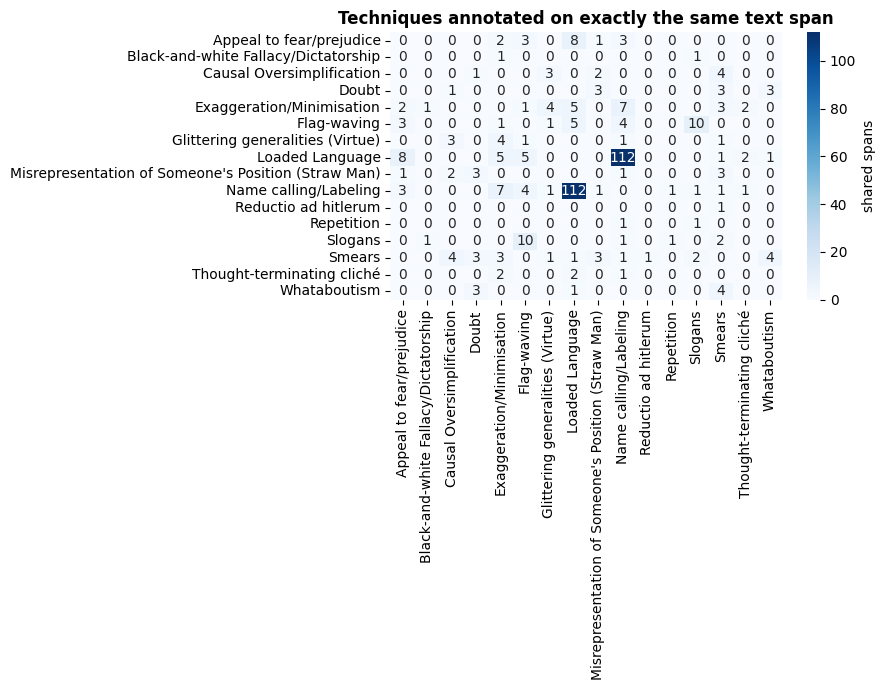

In [21]:
#which techniques do the annotators put on the SAME words? (exact same character span)
#a proxy for how hard techniques are to tell apart; per-annotator labels are not released


co = pd.DataFrame(0, index=TECHNIQUES, columns=TECHNIQUES)
for spans in df2["spans"]:
    for (s1, e1, t1), (s2, e2, t2) in itertools.combinations(spans, 2):
        if t1 != t2 and s1 == s2 and e1 == e2:
            co.loc[t1, t2] += 1
            co.loc[t2, t1] += 1

keep = co.sum(axis=1) > 0                     #only techniques that share a span at least once
plt.figure(figsize=(9, 7))
sns.heatmap(co.loc[keep, keep], annot=True, fmt="d", cmap="Blues", cbar_kws={"label": "shared spans"})
plt.title("Techniques annotated on exactly the same text span", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

* The heatmap shows how often two different techniques were assigned to exactly the same text span in the consolidated gold labels. Loaded Language and Name calling overlap 112 times, far more than any other pair, suggesting that annotators frequently labelled them together. This supports the multi-label approach, as the same words can express multiple techniques. Therefore, the token head uses independent sigmoids to score each technique separately. However, this overlap may make the two techniques difficult for the model to distinguish. When the same tokens are labelled with both techniques, the training data provides little evidence of where one ends and the other begins, meaning their predicted scores may move together. Since individual annotator labels are not available, the heatmap shows overlaps in the agreed labels rather than disagreements between annotators.

In [22]:
#[5a] one fixed 5-fold CV split on all training memes, used for Part A, Part B and Part C
#the SemEval test set (test_set_task2.txt) is not loaded here: it is loaded and used once, in [13] Final test

idx = np.arange(len(df2))

#extra "no technique" column, used for stratification only, important empty memes are represented in every split
Y_strat = np.hstack([Y, (Y.sum(axis=1) == 0)[:, None]])

#no internal hold-out: every training meme is used for cross-validation; the test set is a separate file (test_set_task2.txt)
idx_cv, idx_test = idx, np.array([], dtype=int)

# 5-fold CV on all training memes (model selection, early stopping)
mskf = MultilabelStratifiedKFold(n_splits=K_FOLDS, shuffle=True, random_state=SEED)
cv_splits = [(idx_cv[tr], idx_cv[va]) for tr, va in mskf.split(idx_cv, Y_strat[idx_cv])]

#save the split by meme id so every Part C experiment uses exactly the same folds
two_head_splits = {
    "cv_folds": {f"fold_{k+1}": {"train_ids": df2["id"].iloc[tr].tolist(),
                                 "val_ids": df2["id"].iloc[va].tolist()}
                 for k, (tr, va) in enumerate(cv_splits)}
}
with open("two_head_splits.json", "w") as f:
    json.dump(two_head_splits, f, indent=1)

split_counts = pd.DataFrame({"train+val memes": Y[idx_cv].sum(0).astype(int)}, index=TECHNIQUES)

split_counts.loc["(no technique)"] = [int((Y[idx_cv].sum(1) == 0).sum())]
print(f"train+val: {len(idx_cv)} memes in 5-fold CV (the test set is loaded only in [13])")
display(split_counts)

train+val: 750 memes in 5-fold CV (the test set is loaded only in [13])


,train+val memes
Appeal to authority,15
Appeal to fear/prejudice,47
Bandwagon,4
Black-and-white Fallacy/Dictatorship,18
Causal Oversimplification,28
Doubt,56
Exaggeration/Minimisation,59
Flag-waving,32
Glittering generalities (Virtue),33
Loaded Language,389


### Masking words that model could link to a technique egsample "Trump" -> "Smears"
* The 40 most used words in the training memes minus stop words
* Stop words ("the", "and", "don", "isn", ...) are removed
* The memes were collected in 2020 from Facebook groups that were mostly about U.S and Candaian politics during the COVID-19 pandemic. Also the data is labelled by a small team of annotators (Dimitrov et al., 2021).
* As The model will be used by Australian high school students in 2026, words related to politicians names, COVID and vaccines at the time of the training data may not reflect the current time (zeitgeist).
* These words could become shortcuts the model links to a technique, and those shortcuts may not carry over to today's memes.
* The plot shows which words dominate; [5b] selects which of them to mask, it counts the memes that contain each word not total occurrences. Only the train+val memes are used  the 15%
* hold-out test memes from [5] are left out, so nothing chosen from this plot has seen the test set.

In [23]:
#[5b] the 40 most used words in the training memes once stop words ("the", "and", "don", "isn", ...) are removed

#specify the top 40
TOP_N = 40
#defined stop words to remove
STOP_WORDS = sorted(set(ENGLISH_STOP_WORDS) | {"don", "doesn", "didn", "isn", "aren", "wasn", "won", "ll", "ve", "re",
                                              "im", "dont", "cant", "u", "amp", "rt"})   #fragments of contractions

#one row per word occurrence, with its position so it can be checked against the gold spans
memes = df_part_b                                                          #training memes only
rows = []
for meme_id, text, spans in memes[["id", "text", "labels"]].itertuples(index=False):
    for m in re.finditer(r"[A-Za-z]{2,}", text):                      #'Trump's' -> 'trump', '#Trump2020' -> 'trump'
        techs = [s["technique"] for s in spans if s["start"] <= m.start() and m.end() <= s["end"]]
        rows.append({"id": meme_id, "word": m.group(0).lower(), "start": m.start(), "text": text,
                     "in_span": bool(techs), "techniques": techs})
word_df = pd.DataFrame(rows)

#the query: drop the stop words, then rank what is left by the number of memes it appears in
# Remove stop words
content = word_df.query("word not in @STOP_WORDS")

# Rank words by the number of memes they appear in
word_counts = (
    content.groupby("word")
    .agg(
        memes=("id", "nunique"),
        instances=("id", "size"),
        in_span=("in_span", "mean")
    )
    .sort_values(["memes", "instances"], ascending=False)
)

# Find the most common technique associated with each word
top_tech = (
    content.explode("techniques")
    .dropna(subset=["techniques"])
    .groupby("word")["techniques"]
    .agg(lambda s: s.value_counts().index[0])
)

# Calculate the percentage of training memes containing each word
word_counts["%memes"] = 100 * word_counts["memes"] / len(memes)

# Add the most common associated technique
word_counts["technique around it"] = (
    top_tech.reindex(word_counts.index).fillna("—")
)

# Select the top 40 words
top_words = word_counts.head(TOP_N)

print(
    f"{len(memes)} train+val memes, {len(word_df)} words, "
    f"{len(content)} left after removing {len(STOP_WORDS)} stop words, "
    f"{content['word'].nunique()} distinct"
)

display(
    top_words[
        ["memes", "%memes", "instances", "in_span", "technique around it"]
    ].round({"%memes": 1, "in_span": 2})
)

750 train+val memes, 12737 words, 6777 left after removing 332 stop words, 3017 distinct


,memes,%memes,instances,in_span,technique around it
word,,,,,
trump,99,13.2,110,0.55,Smears
people,45,6.0,50,0.72,Smears
biden,45,6.0,48,0.50,Smears
president,45,6.0,47,0.62,Exaggeration/Minimisation
like,43,5.7,45,0.56,Smears
america,40,5.3,45,0.76,Flag-waving
just,39,5.2,41,0.59,Smears
joe,36,4.8,37,0.51,Smears
think,33,4.4,35,0.63,Smears


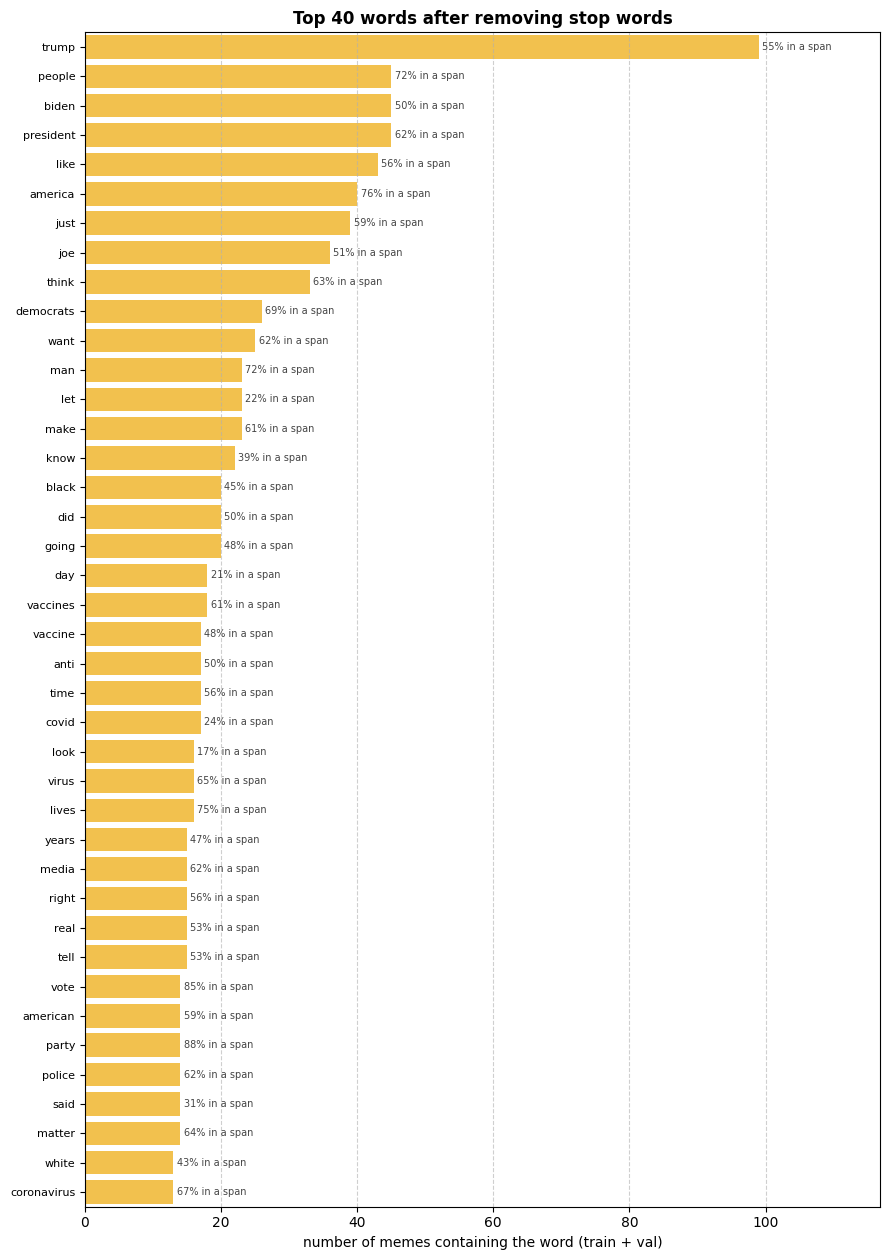

In [24]:
fig, ax = plt.subplots(figsize=(9, 0.28 * TOP_N + 1.5))
ax.barh(top_words.index[::-1], top_words["memes"][::-1], color="#f2c14e")
ax.set_ylim(-0.5, len(top_words) - 0.5)
for y, (w, r) in enumerate(top_words[::-1].iterrows()):
    ax.text(r["memes"] + 0.5, y, f"{r['in_span']:.0%} in a span", va="center", fontsize=7, color="#444444")
ax.set_xlim(0, top_words["memes"].max() * 1.18)                #room for the "in a span" labels
ax.set_xlabel("number of memes containing the word (train + val)")
ax.set_title(f"Top {TOP_N} words after removing stop words", fontsize=12, fontweight="bold")
ax.tick_params(axis="y", labelsize=8)
ax.grid(axis="x", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

pre-select the words to mask
* rule, fixed before training: a politician or party in NAME_GROUPS is masked if it appears in at least 2 Memes.
* train+val memes - [5b] , then all of its words are then masked together,to prevent "Bernie Sanders" accidentally being mapped as "<mask> Sanders".

* It is important that ideology words are listed for display but not masked by default - because they can form the technique itself
    * for example: "liberal" used as an insult = Name calling.
    * Words that are the evidence to a technique such as: "Hitler", "Nazi" -> Reductio ad hitlerum should not be masked.
* Memes are mostly in capitals, so names cannot be found reliably from
* Capitalisation or POS tags: a declared list is used instead.


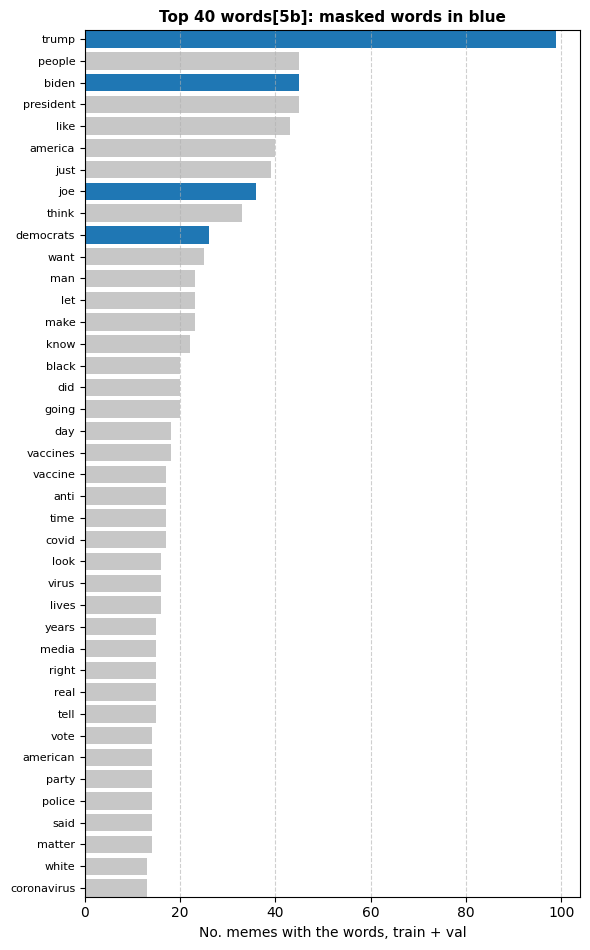

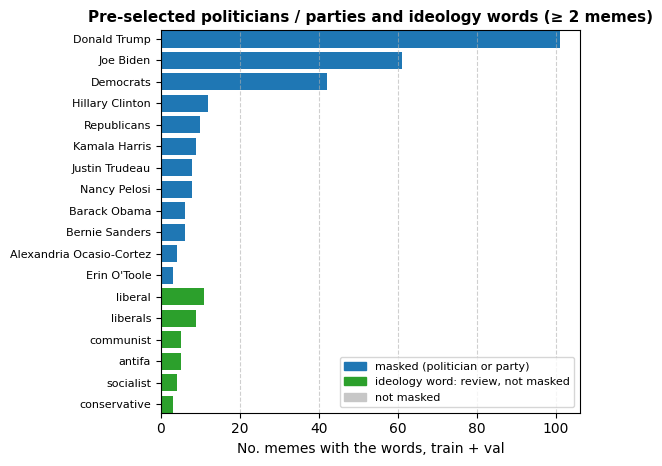

In [25]:
#[5d] Pre-select words to mask: political names and parties, not frequent words

MIN_MEMES = 2
INCLUDE_IDEOLOGY = False

#Defined political names, parties and ideology words
# Group names and related words because a meme may refer to a person
# by their first name, surname or abbreviation.
NAME_GROUPS = {
    "Donald Trump": ["donald", "trump"],
    "Joe Biden": ["joe", "biden"],
    "Barack Obama": ["barack", "obama"],
    "Hillary Clinton": ["hillary", "clinton"],
    "Kamala Harris": ["kamala", "harris"],
    "Nancy Pelosi": ["nancy", "pelosi"],
    "Bernie Sanders": ["bernie", "sanders"],
    "Mike Pence": ["pence"],
    "Mitch McConnell": ["mcconnell"],
    "Alexandria Ocasio-Cortez": [
        "aoc", "alexandria", "ocasio", "cortez"
    ],
    "Chuck Schumer": ["schumer"],
    "Andrew Cuomo": ["cuomo"],
    "Justin Trudeau": ["justin", "trudeau"],
    "Erin O'Toole": ["erin", "toole"],
    "Andrew Scheer": ["scheer"],
    "Democrats": ["democrat", "democrats", "dem", "dems"],
    "Republicans": ["republican", "republicans", "gop"]
}
#words associated with a candidate's political ideology
IDEOLOGY_CANDIDATES = {
    "liberal", "liberals",
    "leftist", "leftists",
    "conservative", "conservatives",
    "maga", "antifa",
    "socialist", "socialists",
    "communist", "communists",
    "libtard", "libtards"
}
#kept words unmasked because they may be useful for techniques
# such as "Reductio ad hitlerum".
NEVER_MASK = {
    "hitler", "nazi", "nazis"
}

#retrieve contexts and summarise words
# Retrieve example contexts containing the selected words.
# Each example includes surrounding text for manual inspection.
def contexts(words, k=2, width=35):
    hits = (
        content[content["word"].isin(words)]
        .drop_duplicates("id")
        .head(k)
    )
    out = [
        " ".join(
            (
                "…"
                + r.text[
                    max(0, r.start - width):
                    r.start + len(r.word) + width
                ]
                + "…"
            ).split()
        )
        for r in hits.itertuples()
    ]
    return (out + ["", ""])[:k]

#summarise the frequency and associated techniques for selected words.
def summarise(words):
    occ = content[content["word"].isin(words)]

    techs = (
        occ.explode("techniques")["techniques"]
        .dropna()
    )
    return {
        "memes": occ["id"].nunique(),
        "% of memes": (
            100 * occ["id"].nunique() / len(memes)
        ),
        "words found": ", ".join(
            sorted(set(occ["word"]))
        ),
        "in_span": (
            occ["in_span"].mean()
            if len(occ)
            else np.nan
        ),
        "most common technique around it": (
            techs.value_counts().index[0]
            if len(techs)
            else "—"
        )
    }

#Selected politicians and parties
# Count each politician or party as a group.
# Keep only groups appearing in at least MIN_MEMES memes.
groups = pd.DataFrame({
    group: summarise(words)
    for group, words in NAME_GROUPS.items()
}).T.infer_objects()

groups = (
    groups[groups["memes"] >= MIN_MEMES]
    .sort_values("memes", ascending=False)
)
groups["mask?"] = "yes"

#Identify ideology words for review
# Count ideology words individually.
# Exclude words listed in NEVER_MASK.
ideology = [
    word
    for word in IDEOLOGY_CANDIDATES - NEVER_MASK
    if (
        word in word_counts.index
        and word_counts.loc[word, "memes"] >= MIN_MEMES
    )
]
if ideology:
    idy = (
        pd.DataFrame({
            word: summarise([word])
            for word in ideology
        })
        .T.infer_objects()
        .sort_values("memes", ascending=False)
    )
else:
    idy = pd.DataFrame()

# Mark ideology words for review unless explicitly enabled for masking.
if len(idy):
    idy["mask?"] = (
        "yes"
        if INCLUDE_IDEOLOGY
        else "review (ideology)"
    )

# Combine political groups and ideology words.
selected = pd.concat([groups, idy])
# Add two example contexts for each selected group or word.
selected["example 1"], selected["example 2"] = zip(
    *[
        contexts(NAME_GROUPS.get(group, [group]))
        for group in selected.index
    ]
)

#built list with regular expression for masking
MASK_WORDS = sorted(
    {
        word
        for group in groups.index
        for word in NAME_GROUPS[group]
    }
    | (
        set(ideology)
        if INCLUDE_IDEOLOGY
        else set()
    )
)

# Match whole words regardless of case.
# The boundaries also allow punctuation before or after a word.
MASK_RE = re.compile(
    r"(?<![A-Za-z])("
    + "|".join(
        sorted(
            map(re.escape, MASK_WORDS),
            key=len,
            reverse=True
        )
    )
    + r")(?![A-Za-z])",
    re.IGNORECASE
)
#visuals
colour = lambda word: (
    "#1f77b4" if word in MASK_WORDS
    else "#2ca02c" if word in ideology
    else "#c7c7c7"
)

group_colour = lambda group: (
    "#1f77b4" if group in groups.index or INCLUDE_IDEOLOGY
    else "#2ca02c"
)
#Plotted frequent words and pre selected groups
fig1, ax1 = plt.subplots(figsize=(6, 0.22 * TOP_N + 0.8))
reversed_words = top_words.iloc[::-1]
ax1.barh(
    reversed_words.index,
    reversed_words["memes"],
    color=[colour(word) for word in reversed_words.index]
)
ax1.set_title(f"Top {TOP_N} words[5b]: masked words in blue", fontsize=11, fontweight="bold")
ax1.set_xlabel("No. memes with the words, train + val")
ax1.tick_params(axis="y", labelsize=8)
ax1.grid(axis="x", linestyle="--", alpha=0.6)
ax1.margins(y=0)
plt.tight_layout()
plt.show()

#Right Plot: Selected Groups & Ideology
fig2, ax2 = plt.subplots(figsize=(6, 0.22 * len(selected) + 0.8))
reversed_selected = selected.iloc[::-1]
ax2.barh(
    reversed_selected.index,
    reversed_selected["memes"],
    color=[group_colour(group) for group in reversed_selected.index]
)
ax2.set_title(
    f"Pre-selected politicians / parties and ideology words (≥ {MIN_MEMES} memes)",
    fontsize=11,
    fontweight="bold"
)
ax2.set_xlabel("No. memes with the words, train + val")
ax2.tick_params(axis="y", labelsize=8)
ax2.grid(axis="x", linestyle="--", alpha=0.6)
ax2.margins(y=0)

# Legend
ax2.legend(
    handles=[
        plt.Rectangle((0, 0), 1, 1, color=color)
        for color in ["#1f77b4", "#2ca02c", "#c7c7c7"]
    ],
    labels=[
        "masked (politician or party)",
        "ideology word: review, not masked",
        "not masked"
    ],
    fontsize=8,
    loc="lower right"
)
plt.tight_layout()
plt.show()


Chart: Top 40 words shows the cumber of times certain words show up in the meme and Chart: Pre-selected are where they occur greater than 2 memes

In [26]:
#[6] Pre-tokenised dataset with document labels as well as token labels
tokenizer = RobertaTokenizerFast.from_pretrained(MODEL_NAME)
# Tokenise every meme once, keeping character offsets and a 20-dimensional
# multi-hot label vector for each token.
# k = 1 if the token overlaps any span of technique k.
# Special tokens and padding tokens are ignored by the token loss (-100).

class TwoHeadDataset(Dataset):

    def __init__(
        self,
        texts,
        spans,
        doc_labels,
        tokenizer,
        max_len=MAX_LENGTH,
        num_classes=NUM_CLASSES
    ):
        enc = tokenizer(
            texts,
            truncation=True,
            padding="max_length",
            max_length=max_len,
            return_offsets_mapping=True,
            return_tensors="pt"
        )

        self.input_ids = enc["input_ids"]
        self.attention_mask = enc["attention_mask"]
        self.offsets = enc["offset_mapping"]
        self.doc_labels = torch.tensor(
            doc_labels,
            dtype=torch.float32
        )

        self.tok_labels = torch.zeros(
            (len(texts), max_len, num_classes),
            dtype=torch.float32
        )

        for i, (offs, sp) in enumerate(zip(self.offsets, spans)):
            starts = offs[:, 0]
            ends = offs[:, 1]

            # Special tokens and padding have offsets (0, 0)
            special = ends <= starts
            self.tok_labels[i, special, :] = -100

            for s, e, t in sp:
                hit = (
                    (~special)
                    & (starts < e)
                    & (ends > s)
                )

                self.tok_labels[i, hit, label2id[t]] = 1.0

    def __len__(self):
        return len(self.input_ids)

    def __getitem__(self, idx):
        return {
            "input_ids": self.input_ids[idx],
            "attention_mask": self.attention_mask[idx],
            "doc_labels": self.doc_labels[idx],
            "tok_labels": self.tok_labels[idx],
            "offsets": self.offsets[idx],
        }


# Create the full dataset
full_dataset = TwoHeadDataset(
    df2["text"].tolist(),
    df2["spans"].tolist(),
    Y,
    tokenizer
)

GOLD_SPANS = df2["spans"].tolist()


# Check one meme by printing each token that carries a technique
ex = int(np.argmax(df2["spans"].map(len).values))
toks = tokenizer.convert_ids_to_tokens(
    full_dataset.input_ids[ex]
)

# Print a sample for visual inspection
print(df2["text"].iloc[ex])

for tok, lab in zip(toks, full_dataset.tok_labels[ex]):
    if lab[0] != -100 and lab.sum() > 0:
        techniques = [
            TECHNIQUES[k]
            for k in torch.where(lab == 1)[0].tolist()
        ]

        print(f"{tok:>15} -> {techniques}")


He cheats at golf.
He cheated the draft.
He cheats on his taxes.
He cheated on his wives.
He cheated on his loans.

He cheated his charities.
He cheated his contractors.
He cheated Trump U students.
He cheated to get elected in 2016.
He will cheat again in 2020!
             He -> ['Smears']
           Ġche -> ['Loaded Language', 'Smears']
            ats -> ['Loaded Language', 'Smears']
            Ġat -> ['Smears']
          Ġgolf -> ['Smears']
              . -> ['Smears']
              Ċ -> ['Smears']
             He -> ['Repetition', 'Smears']
       Ġcheated -> ['Loaded Language', 'Repetition', 'Smears']
           Ġthe -> ['Smears']
         Ġdraft -> ['Smears']
              . -> ['Smears']
              Ċ -> ['Smears']
             He -> ['Repetition', 'Smears']
           Ġche -> ['Loaded Language', 'Repetition', 'Smears']
            ats -> ['Loaded Language', 'Repetition', 'Smears']
            Ġon -> ['Smears']
           Ġhis -> ['Smears']
         Ġtaxes -> ['Smears']
  

*  Above is a visual on the tokenization process

1680 annotated spans from 593 memes, 768-D


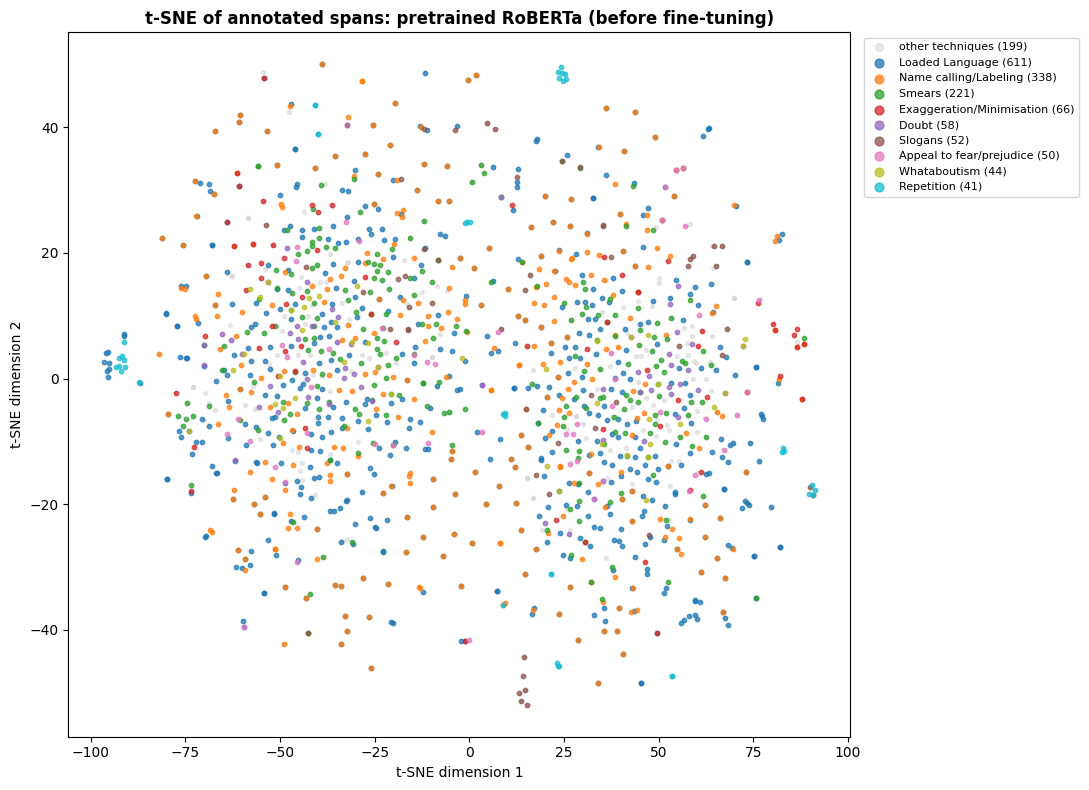

array([[ 16.76486  ,   1.3574708],
       [ 38.615967 ,  -3.717295 ],
       [ 32.170982 ,  16.39198  ],
       ...,
       [-23.963442 , -11.09074  ],
       [-25.33554  , -10.29133  ],
       [-55.899197 ,  33.77061  ]], shape=(1680, 2), dtype=float32)

In [27]:
#[6b] how do the techniques cluster? one point per annotated span, embedded by pretrained RoBERTa, t-SNE to 2-D
#a meme usually has several techniques, so a meme cannot get one colour; a SPAN has exactly one technique.
#each span is embedded IN CONTEXT: the mean of RoBERTa's token vectors that overlap the span inside its meme.
#t-SNE (sklearn) is used for visualisation only; it plays no part in the model.

#One vector per annotated span: mean of the encoder's token vectors overlapping the span.
#spans_per_meme must be in the same order as dataset. Returns (vectors, techniques, meme index)
def span_embeddings(encoder, dataset, spans_per_meme, batch_size=32):
    vecs, techs, meme_idx = [], [], []
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False)
    encoder.eval()
    k = 0
    with torch.inference_mode():
        for batch in loader:
            hidden = encoder(input_ids=batch["input_ids"].to(device),
                             attention_mask=batch["attention_mask"].to(device))[0].float().cpu()
            for i in range(len(hidden)):
                starts, ends = batch["offsets"][i][:, 0], batch["offsets"][i][:, 1]
                real = ends > starts                                  #skip <s>, </s> and padding
                for s, e, t in spans_per_meme[k]:
                    hit = real & (starts < e) & (ends > s)
                    if hit.any():
                        vecs.append(hidden[i][hit].mean(0).numpy())
                        techs.append(t)
                        meme_idx.append(k)
                k += 1
    return np.stack(vecs), np.array(techs), np.array(meme_idx)
    
#t-SNE to 2-D; the top_n most frequent techniques get a colour, the rest are grey.
def plot_tsne(vecs, techs, title, top_n=9, seed=SEED):
    xy = TSNE(n_components=2, perplexity=30, init="pca", random_state=seed).fit_transform(vecs)
    top = pd.Series(techs).value_counts().index[:top_n]
    colours = [c for j, c in enumerate(plt.get_cmap("tab10").colors) if j != 7]   #drop tab10's grey (used for "other")
    fig, ax = plt.subplots(figsize=(11, 8))
    other = ~np.isin(techs, top)
    ax.scatter(xy[other, 0], xy[other, 1], s=8, alpha=0.5, color="lightgrey",
               label=f"other techniques ({other.sum()})")
    for j, t in enumerate(top):
        m = techs == t
        ax.scatter(xy[m, 0], xy[m, 1], s=10, alpha=0.75, color=colours[j], label=f"{t} ({m.sum()})")
    ax.legend(fontsize=8, markerscale=2, bbox_to_anchor=(1.01, 1), loc="upper left")
    ax.set_xlabel("t-SNE dimension 1")
    ax.set_ylabel("t-SNE dimension 2")
    ax.set_title(title, fontsize=12, fontweight="bold")
    plt.tight_layout()
    plt.show()
    return xy

#pretrained RoBERTa, before any fine-tuning (no labels are used to make the embedding)
encoder_pre = AutoModel.from_pretrained(MODEL_NAME).to(device)
span_vecs, span_techs, span_meme = span_embeddings(encoder_pre, full_dataset, GOLD_SPANS)
del encoder_pre
torch.cuda.empty_cache()
print(f"{len(span_vecs)} annotated spans from {len(set(span_meme))} memes, {span_vecs.shape[1]}-D")

plot_tsne(span_vecs, span_techs, "t-SNE of annotated spans: pretrained RoBERTa (before fine-tuning)")

* The following t-SNE squashes 768 dimensions down to 2, where each span is a 768-number vector, the average of RoBERTa token vectors over the spans word.
* Perplexity of 30, of how many neighbours each point tries to keep close.
* Each technique is coloured.
*  No technique clusters. Loaded Language (in blue) and Name calling (in Orange) fall below chance because they share words and memes, only techniques with a recognisable form such as Repetition, Whataboutism, quotes, Smears partly through length, group together
*  Only tight groups are small islands of repeated text:
    *  Repetition (light blue) at the edges: around (−95, 3), (25, 48), (90, −18) and (83, −11)
    *  Slogans (brown), around (12, −48)
    *  Could be caused by the same phrase appearing a number of times being contextual to Repetition and Slogans

## Model Architecture

- RoBERTa converts a meme into one 768-dimensional vector per token.

- Part A: The document head combines the token vectors into a single representation of the whole meme and predicts the propaganda techniques present.

- Part B: The token head makes a prediction for each token to identify the propaganda technique associated with it.

- Both heads use the same RoBERTa encoder and are trained together.

The process will look like:

Meme → RoBERTa encoder → token vectors

    → Document head → Part A prediction

    → Token head → Part B prediction

The two prediction errors are combined during training. The token-level error can be given more or less influence on the shared encoder.

The experiments compare pooling types ([11]: cls / mean / the learned attention pooling designed here) and λ, the weight of the token-level loss ([10d]). The heads themselves are RoBERTa’s standard classification head and a linear token layer.

In [28]:
#[7] two-head model
# RoBERTa encodes the meme, attention pooling summarises it for the document head (Part A), 
#the token head labels every token (Part B), and the two losses are combined with weight λ so both tasks train the shared encoder


#Turns RoBERTa’s one vector per token output into a single vector for the whole meme, used for the document head
class AttentionPooling(nn.Module):
    def __init__(self, hidden_size):
        super().__init__()
        self.score = nn.Sequential(
            nn.Linear(hidden_size, hidden_size // 2),
            nn.Tanh(),
            nn.Linear(hidden_size // 2, 1)
        )

    def forward(self, hidden_states, attention_mask):
        scores = self.score(hidden_states).squeeze(-1)
        scores = scores.masked_fill(attention_mask == 0, -1e4)
        weights = torch.softmax(scores, dim=-1)
        pooled = (weights.unsqueeze(-1) * hidden_states).sum(dim=1)
        return pooled, weights


#RobertaForTechniqueAndSpan: one RoBERTa encoder shared by two heads, trained together
#  input : a tokenised meme (input_ids, attention_mask)
#  RoBERTa turns every token into a 768-D vector that depends on the whole meme (context)
#  pooling turns those token vectors into one meme vector: cls (first token), mean, or attention pooling
#  Document head (Part A): meme vector -> 20 scores, one per technique and answers the question "is this technique in the meme?"
#  Token head (Part B): every token vector -> 20 scores, answers the question "is this token part of a span of this technique?"
#  loss : binary cross-entropy per technique for each head - independent sigmoids, so several techniques can apply,
#         with pos_weight for rare techniques: unknown labels (-1, PTC) and special/padding tokens (-100) are ignored
#         total loss = doc loss + λ × token loss, so both tasks update the shared encoder
#  output: both sets of logits, the losses, the attention weights and the pooled meme vector
class RobertaForTechniqueAndSpan(RobertaPreTrainedModel):
    def __init__(self, config):
        super().__init__(config)
        self.num_labels = config.num_labels
        self.pooling = getattr(config, "pooling", "attn")
        H = config.hidden_size

        #drop out for RoBERTa
        dropout = config.classifier_dropout if config.classifier_dropout is not None else config.hidden_dropout_prob

        self.roberta = RobertaModel(config, add_pooling_layer=False)
        self.attn_pool = AttentionPooling(H)

        #using RoBERTa classifcation head
        self.doc_head = RobertaClassificationHead(config)

        #using RoBERTa token classification layer
        self.tok_head = nn.Sequential(nn.Dropout(dropout), nn.Linear(H, config.num_labels))

        #set per fold with set_loss_weights()
        self.doc_pos_weight = None
        self.tok_pos_weight = None
        self.lam = 1.0

        self.post_init()

    def set_loss_weights(self, doc_pos_weight, tok_pos_weight, lam):
        self.doc_pos_weight = doc_pos_weight
        self.tok_pos_weight = tok_pos_weight
        self.lam = lam


    def forward(self, input_ids=None, attention_mask=None, doc_labels=None, tok_labels=None, **kwargs):
        hidden = self.roberta(input_ids=input_ids, attention_mask=attention_mask)[0]

        attn_weights = None
        if self.pooling == "cls":
            pooled = hidden[:, 0]
        elif self.pooling == "mean":
            m = attention_mask.unsqueeze(-1).to(hidden.dtype)
            pooled = (hidden * m).sum(1) / m.sum(1).clamp(min=1)
        else:
            pooled, attn_weights = self.attn_pool(hidden, attention_mask)

        #RobertaClassificationHead reads token 0, pass pooled vector as a one token sequence
        doc_logits = self.doc_head(pooled.unsqueeze(1))         # (B, C)
        tok_logits = self.tok_head(hidden)            # (B, T, C)

        loss = doc_loss = tok_loss = None
        if doc_labels is not None and tok_labels is not None:
            #doc loss: a label of -1 means "unknown for this example" (PTC techniques it cannot label)
            #-> left out of the loss instead of being treated as a negative
            doc_valid = (doc_labels >= 0).float()
            doc_l = nn.functional.binary_cross_entropy_with_logits(
                doc_logits, doc_labels.clamp(min=0), pos_weight=self.doc_pos_weight, reduction="none")
            doc_loss = (doc_l * doc_valid).sum() / doc_valid.sum().clamp(min=1)

            #only real tokens: attention == 1 and label != -100
            active = (attention_mask.view(-1) == 1) & (tok_labels.view(-1, self.num_labels)[:, 0] != -100)
            active_logits = tok_logits.view(-1, self.num_labels)[active]
            active_labels = tok_labels.view(-1, self.num_labels)[active]
            if active_logits.shape[0] > 0:
                #token loss: same rule, -1 classes are left out
                tok_valid = (active_labels >= 0).float()
                tok_l = nn.functional.binary_cross_entropy_with_logits(
                    active_logits, active_labels.clamp(min=0), pos_weight=self.tok_pos_weight, reduction="none")
                tok_loss = (tok_l * tok_valid).sum() / tok_valid.sum().clamp(min=1)
            else:
                tok_loss = tok_logits.sum() * 0.0

            loss = doc_loss + self.lam * tok_loss

        return {"loss": loss, "doc_loss": doc_loss, "tok_loss": tok_loss,
                "doc_logits": doc_logits, "tok_logits": tok_logits, "attn_weights": attn_weights,
                "pooled": pooled}


#the is used in [12b] to apply a custom head
def build_two_head_model(pooling="attn", head_hidden=256):
    config = AutoConfig.from_pretrained(MODEL_NAME, num_labels=NUM_CLASSES)
    config.pooling = pooling
    config.head_hidden = head_hidden
    return RobertaForTechniqueAndSpan.from_pretrained(MODEL_NAME, config=config).to(device)


def inject_lora(model, r=8, lora_dropout=0.1):
    #LoRA adapters on the encoder only; the two heads stay fully trainable
    lora_config = LoraConfig(r=r, lora_alpha=2 * r, lora_dropout=lora_dropout, target_modules=["query", "value"])
    model.roberta = get_peft_model(model.roberta, lora_config)
    return model


def count_parameters(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    heads = sum(p.numel() for n, p in model.named_parameters() if not n.startswith("roberta."))
    return total, trainable, heads

### Metrics
* **Part A**: the same "f1_stats"/"best_threshold" (Macro-F1 and Micro-F1, exact match, label accuracy), so the scores are comparable. Micro-F1 was used in SemEval Task 1 measure.
  Because "f1_stats" averages Macro-F1 only over techniques present in the evaluated set, the final report also gives Macro-F1 over all 20 techniques, minus the techniques count as 0.
* **Part B**: In (Dimitrov et al., 2021, Section 5.1) for measuring how accurately the predicted spans match the correct spans, is where the prediction gets partial credit when it overlaps with the correct span (predicted tokens are joined together to form a span)
    * Precision: measures how much of the predicted span is correct,
    * recall: measures how much of the correct span was found.
    * These are averaged across all spans and combined into an F1 score.

* early stopping uses the mean of validation doc Macro-F1 and span F1

In [29]:
#[8] metric utilities, span decoding and training functions

#run_experiment calls train_one_epoch and evaluate_model
#evaluate_model calls score_predictions and score_predictions uses best_threshold and f1_stats for Part A, 
#and decode_spans and span_prf for Part B

def f1_stats(y_true, y_pred):
    #counts per technique
    tp = (y_true * y_pred).sum(axis=0)  #true positives
    fp = ((1 - y_true) * y_pred).sum(axis=0) #false positives
    fn = (y_true * (1 - y_pred)).sum(axis=0) #false negatives
    #F1 is 2·TP / (2·TP + FP + FN) for each technique. A technique with nothing to count gets 0 instead of a division by zero.
    den = 2 * tp + fp + fn
    per_class = np.divide(2 * tp, den, out=np.zeros_like(den, dtype=np.float64), where=den > 0)

    observed = y_true.sum(axis=0) > 0
    
    #Macro-F1 is the average F1 over the techniques that actually occur in y_true - the observed
    #note: a technique absent from a validation fold doesn’t count as a 0
    macro_f1 = float(per_class[observed].mean()) if observed.any() else 0.0
    #Micro-F1 pools all TP, FP and FN across techniques before computing F1
    micro_f1 = float(2 * tp.sum() / max(den.sum(), 1))
    #the share of memes where all 20 predictions are right
    exact_match = float((y_true == y_pred).all(axis=1).mean())
    #the share of correct (meme, technique)
    accuracy = float((y_true == y_pred).mean())
    
    return macro_f1, micro_f1, exact_match, accuracy, per_class

#choosing the doc threshold, It tries every cut-off in THRESHOLDS, turns the probabilities into 0 or 1, and keeps the one with the highest Macro-F1
def best_threshold(y_true, probs):
    scores = [f1_stats(y_true, (probs >= t).astype(np.float32))[0] for t in THRESHOLDS]
    best_idx = int(np.argmax(scores))
    return float(THRESHOLDS[best_idx]), float(scores[best_idx])

#tok_probs: (n_tokens, C) probabilities for the real tokens of one meme
#offsets:   (n_tokens, 2) character offsets of those tokens
#Consecutive tokens above the threshold are merged into one (start, end, technique) span.
def decode_spans(tok_probs, offsets, threshold, only_class=None):
    spans = []
    classes = range(NUM_CLASSES) if only_class is None else [only_class]
    for k in classes:
        on = tok_probs[:, k] >= threshold
        if not on.any():
            continue
        d = np.diff(np.concatenate([[0], on.astype(np.int8), [0]]))
        for a, b in zip(np.where(d == 1)[0], np.where(d == -1)[0] - 1):
            spans.append((int(offsets[a, 0]), int(offsets[b, 1]), TECHNIQUES[k]))
    return spans

#measure, which gives credit for partial overlap
def span_prf(pred_spans, gold_spans):
    #measure: partial overlap credit, technique must match
    #For every predicted span and gold span in the same meme with the same technique, it measures the overlap in characters
    p_sum, r_sum, n_pred, n_gold = 0.0, 0.0, 0, 0
    for S, T in zip(pred_spans, gold_spans):
        n_pred += len(S)
        n_gold += len(T)
        for s0, s1, ls in S:
            for t0, t1, lt in T:
                if ls == lt:
                    inter = max(0, min(s1, t1) - max(s0, t0))
                    if inter > 0:
                        p_sum += inter / (s1 - s0)
                        r_sum += inter / (t1 - t0)
    #Precision gives each predicted span credit equal to the fraction of it that overlaps the gold span, averaged over all predicted spans
    precision = p_sum / n_pred if n_pred else 0.0
    #Recall gives each gold span credit equal to the fraction of it that’s covered, averaged over all gold spans
    recall = r_sum / n_gold if n_gold else 0.0
    #the harmonic mean of the two
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return {"precision": precision, "recall": recall, "f1": f1}

#scoring both parts at once
def score_predictions(doc_true, doc_probs, tok_probs, offsets, gold_spans, threshold=None, tok_threshold=None):
    #Part A: picks one with best_threshold, applies it and calls f1_stats
    if threshold is None:
        threshold, _ = best_threshold(doc_true, doc_probs)
    doc_preds = (doc_probs >= threshold).astype(np.float32)
    macro_f1, micro_f1, exact_match, accuracy, per_class_f1 = f1_stats(doc_true, doc_preds)

    #Part B: tries every value in THRESHOLDS, decodes the spans at each, and keeps the one with the best span F1. It then decodes and scores at that threshold
    def spans_at(t):
        return [decode_spans(tp, off, t) for tp, off in zip(tok_probs, offsets)]
    if tok_threshold is None:
        tok_threshold = max(THRESHOLDS, key=lambda t: span_prf(spans_at(t), gold_spans)["f1"])
    span_preds = spans_at(tok_threshold)
    span = span_prf(span_preds, gold_spans)

    return {
        "macro_f1": macro_f1, "micro_f1": micro_f1, "exact_match": exact_match, "accuracy": accuracy,
        "per_class_f1": per_class_f1, "threshold": float(threshold),
        "span_f1": span["f1"], "span_precision": span["precision"], "span_recall": span["recall"],
        "tok_threshold": float(tok_threshold),
        "doc_probs": doc_probs, "doc_preds": doc_preds, "tok_probs": tok_probs,
        "offsets": offsets, "span_preds": span_preds,
    }

#saving the best epoch
def get_trainable_state(model):
    #only the trainable weights - heads and LoRA. The frozen RoBERTa weights are identical for every fold
    return {n: p.detach().cpu().clone() for n, p in model.named_parameters() if p.requires_grad}

#single pass over the training data
def train_one_epoch(model, loader, optimizer, scheduler=None):
    model.train()
    total_loss, total_doc, total_tok, total_samples = 0.0, 0.0, 0.0, 0

    for batch in loader:
        #Clear old gradients
        optimizer.zero_grad()
        #Run the model with labels, so it returns the combined loss
        outputs = model(
            input_ids=batch["input_ids"].to(device),
            attention_mask=batch["attention_mask"].to(device),
            doc_labels=batch["doc_labels"].to(device),
            tok_labels=batch["tok_labels"].to(device)
        )
        loss = outputs["loss"]
        #Backpropagate
        loss.backward()
        #Clip gradients to a total norm of 1.0 so no very large updates
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        #Update the weights
        optimizer.step()
        if scheduler is not None:
            scheduler.step()

        bs = len(batch["input_ids"])
        total_loss += loss.item() * bs
        total_doc += outputs["doc_loss"].item() * bs
        total_tok += outputs["tok_loss"].item() * bs
        total_samples += bs

    n = max(total_samples, 1)
    #returns the average total, doc and token losses for the epoch, weighted by batch size
    return total_loss / n, total_doc / n, total_tok / n

    
#gold_spans must be in the same order as the loader (shuffle=False).
#threshold / tok_threshold: None = tune on this set (validation only); pass the
#validation thresholds when evaluating the test set.
#collects the sigmoid doc probabilities and the true doc labels
def evaluate_model(model, loader, gold_spans, threshold=None, tok_threshold=None):
    #runs the model in evaluation mode
    model.eval()
    total_loss, total_samples = 0.0, 0
    doc_probs, doc_true, tok_probs, offsets = [], [], [], []
    #For each meme it keeps the token probabilities and offsets of real tokens only, dropping padding and special tokens (label −100)
    with torch.inference_mode():
        for batch in loader:
            tok_labels = batch["tok_labels"]
            outputs = model(
                input_ids=batch["input_ids"].to(device),
                attention_mask=batch["attention_mask"].to(device),
                doc_labels=batch["doc_labels"].to(device),
                tok_labels=tok_labels.to(device)
            )
            bs = len(batch["input_ids"])
            total_loss += outputs["loss"].item() * bs
            total_samples += bs

            doc_probs.append(torch.sigmoid(outputs["doc_logits"]).cpu().numpy())
            doc_true.append(batch["doc_labels"].numpy())
            tp = torch.sigmoid(outputs["tok_logits"]).cpu().numpy()
            for i in range(bs):
                real = (tok_labels[i, :, 0] != -100).numpy()
                tok_probs.append(tp[i][real])
                offsets.append(batch["offsets"][i].numpy()[real])
                
    #calls score_predictions, and adds the average loss and the true labels to the result
    res = score_predictions(np.concatenate(doc_true), np.concatenate(doc_probs), tok_probs, offsets,
                            gold_spans, threshold, tok_threshold)
    res["loss"] = total_loss / max(total_samples, 1)
    res["doc_true"] = np.concatenate(doc_true)
    return res



#Train with early stopping on the validation score = mean(doc Macro-F1, span F1).
#es_metric="macro_f1" stops on doc Macro-F1 only: used when λ = 0, because the token head is then
#untrained and its span F1 is noise that should not choose the epoch. best_info["score"] is always
#the combined score, so runs stay comparable.
#The loss is computed inside the model, so no criterion is passed.
def run_experiment(model, optimizer, train_loader, val_loader, val_gold_spans,
                   epochs=10, patience=5, name="Model", scheduler=None, verbose=True, es_metric="score",
                   train_eval_loader=None, train_gold_spans=None):

    history = {"train_loss": [], "train_doc_loss": [], "train_tok_loss": [], "val_loss": [],
               "val_macro": [], "val_micro": [], "val_span_f1": [], "val_score": [],
               "train_macro": [], "train_span_f1": []}
    best_info = {"epoch": 0, "score": -1.0, "es_value": -1.0, "thr": 0.5, "tok_thr": 0.5,
                 "state": get_trainable_state(model)}
    epochs_no_improve = 0
    
    #trains for one epoch
    for epoch in range(1, epochs + 1):
        #evaluates on the validation fold
        train_loss, train_doc, train_tok = train_one_epoch(model, train_loader, optimizer, scheduler)
        val_res = evaluate_model(model, val_loader, val_gold_spans)
        #computes the combined score: (doc Macro-F1 + span F1) / 2
        val_score = (val_res["macro_f1"] + val_res["span_f1"]) / 2

        #training F1: the fold's original training memes (no augmented copies), scored in eval mode with this
        #epoch's VALIDATION thresholds, so train and validation are measured with the same cut-off
        if train_eval_loader is not None:
            tr_res = evaluate_model(model, train_eval_loader, train_gold_spans,
                                    threshold=val_res["threshold"], tok_threshold=val_res["tok_threshold"])
            history["train_macro"].append(tr_res["macro_f1"])
            history["train_span_f1"].append(tr_res["span_f1"])

        history["train_loss"].append(train_loss)
        history["train_doc_loss"].append(train_doc)
        history["train_tok_loss"].append(train_tok)
        history["val_loss"].append(val_res["loss"])
        history["val_macro"].append(val_res["macro_f1"])
        history["val_micro"].append(val_res["micro_f1"])
        history["val_span_f1"].append(val_res["span_f1"])
        history["val_score"].append(val_score)
        
        es_value = val_res["macro_f1"] if es_metric == "macro_f1" else val_score
        #If that value improves by more than 0.0001, it saves this epoch’s weights, thresholds and scores in best_info and resets the counter
        if es_value > best_info["es_value"] + 1e-4:
            best_info = {"epoch": epoch, "score": val_score, "es_value": es_value, "macro_f1": val_res["macro_f1"],
                         "micro_f1": val_res["micro_f1"], "span_f1": val_res["span_f1"],
                         "thr": val_res["threshold"], "tok_thr": val_res["tok_threshold"],
                         "state": get_trainable_state(model)}
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1

        if verbose and (epoch % 5 == 0 or epoch == 1):
            print(
                f"[{name}] Epoch {epoch:3d}/{epochs} | "
                f"Train Loss: {train_loss:.4f} (doc {train_doc:.4f}, tok {train_tok:.4f}) | "
                f"Val Loss: {val_res['loss']:.4f} | "
                f"Val Macro-F1: {val_res['macro_f1']:.3f} | "
                f"Val Micro-F1: {val_res['micro_f1']:.3f} | "
                f"Val Span-F1: {val_res['span_f1']:.3f} | "
                f"Thr: {val_res['threshold']:.2f}/{val_res['tok_threshold']:.2f}"
            )
        #When the counter reaches patience, training stops
        if epochs_no_improve >= patience:
            if verbose:
                print(f"[{name}] Early stopping at epoch {epoch}. Best epoch {best_info['epoch']}, "
                      f"Val score {best_info['score']:.3f}")
            break

    model.load_state_dict(best_info["state"], strict=False)
    return history, best_info


#results: {name: {"history": ..., "best_info": ...}} (as returned in fold_histories)
#or {name: history}
#Loss: train (solid, o) and validation (dashed, x).
#F1:   validation only (training F1 is not computed during training).
def plot_experiments(results, show_train=True, show_val=True, title="", train_color=None, val_color=None):


    fig, axes = plt.subplots(1, 3, figsize=(20, 5))
    
    panels = [("train_loss", "val_loss", "Loss"),
              ("train_macro", "val_macro", "Macro-F1 (Part A)"),
              ("train_span_f1", "val_span_f1", "Span-F1 (Part B)")]
    
    for name, res in results.items():
        hist = res["history"] if "history" in res else res
        colour = None
        for ax, (tr_key, va_key, _) in zip(axes, panels):
            if show_train and len(hist.get(tr_key, [])):
                line, = ax.plot(range(1, len(hist[tr_key]) + 1), hist[tr_key], label=f"{name} (Train)",
                                marker="o", markersize=3, color=train_color or colour)
                colour = line.get_color()
            if show_val and len(hist.get(va_key, [])):
                line, = ax.plot(range(1, len(hist[va_key]) + 1), hist[va_key], label=f"{name} (Val)",
                                linestyle="--", marker="x", markersize=3, color=val_color or colour)
                colour = line.get_color()

    for ax, (_, _, ylabel) in zip(axes, panels):
        ax.set_xlabel("Epoch"); ax.set_ylabel(ylabel); ax.set_title(ylabel)
        ax.legend(fontsize=8); ax.grid(True, linestyle="--", alpha=0.7)
    if title:
        fig.suptitle(title, fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.show()

#average each training curve over the folds, epoch by epoch
#a fold that stopped early only counts for the epochs it actually ran
def average_history(fold_histories):
    hists = [h["history"] for h in fold_histories.values()]
    n_epochs = max(len(h["train_loss"]) for h in hists)
    avg = {}
    for key in hists[0]:
        if all(len(h.get(key, [])) == 0 for h in hists):
            continue                                            #curve not recorded in this run
        arr = np.full((len(hists), n_epochs), np.nan)
        for i, h in enumerate(hists):
            arr[i, :len(h.get(key, []))] = h.get(key, [])
        avg[key] = np.nanmean(arr, axis=0).tolist()
    return avg

### Class weights
* Inverse-frequency weights are reduced using a square root and limited to a maximum value (20 for the document task and 50 for the token task). To void always answering no on rare techniques (1–2 examples, like Red Herring or Bandwagon) there fore we dont want to allow it to have have to much impact on the loss. The weights are processed using only the training memes in each fold.

* Positive token labels will be a much less occurance than positive document labels as most tokens would not be a propaganda technique. Therefore, the token head uses separate weights based on the token- evel labels rather than using the document level weights.

In [30]:
#[9] class weights per fold

def fold_pos_weights(train_idx):
    #document level
    y = Y[train_idx]
    pos = y.sum(axis=0)
    doc_pw = np.sqrt((len(y) - pos) / np.maximum(pos, 1)).clip(1, 20)

    #token level (only real tokens)
    tl = full_dataset.tok_labels[torch.as_tensor(train_idx)].reshape(-1, NUM_CLASSES)
    tl = tl[tl[:, 0] != -100]
    tpos = (tl == 1).sum(dim=0).numpy()
    tneg = (tl == 0).sum(dim=0).numpy()
    tok_pw = np.sqrt(tneg / np.maximum(tpos, 1)).clip(1, 50)

    return (torch.tensor(doc_pw, dtype=torch.float32).to(device),
            torch.tensor(tok_pw, dtype=torch.float32).to(device))

### Augmentation
* Augmentation used: back-translation (EN→DE→EN, WMT19) + WordNet synonym substitution
process was used in Ng et al. (2019), although they included an addiotnal step where they translated to Russian before going back to English.
* Also in the process is to apply synonyms to words to substitute the different words of equal meaning so to allow a greater diversity in the translation back from the original. This helps avoid any duplicates, was also 
used in Ghadery et al. (2021, Team LIIR)
* It is generated ONCE for every meme in df2 (fixed seed, cached to disk); a copy is only ever used in a fold where its source meme is in the TRAINING part
* This experiment is to show if there is an improvement in the model by utilization a greater number of samples, essentially doubling the training data

In [31]:
#[9a-1] augmentation: back-translation (EN→DE→EN, WMT19) + WordNet synonym substitution
#process used in Ng et al. (2019), subsequently used in Ghadery et al. (2021, Team LIIR)
#generated ONCE for every meme in df2 (fixed seed, cached to disk); a copy is only ever used
#Note: in a fold where its source meme is in the Training part

#aug_dataset is made from aug_df, which holds one back-translated, synonym swapped copy per meme. 
#It’s cached in augmented_memes_task2.csv. 
#Each copy keeps its source meme’s technique labels (Y[aug_source_pos]), 
#and all its token labels are set to -100, so it trains only the technique head.

#after augmentation has been done it is saved so that in future runs saves time having to reload the whole sets again
AUG_CSV = "augmented_memes_task2.csv"

#Maps NLTK POS tags to WordNet POS tags
def get_wordnet_pos(tag):
    if tag.startswith('J'):
        return wordnet.ADJ
    elif tag.startswith('V'):
        return wordnet.VERB
    elif tag.startswith('N'):
        return wordnet.NOUN
    elif tag.startswith('R'):
        return wordnet.ADV
    return None

#Replaces eligible words with a random WordNet synonym with probability replacement_prob
def substitute_synonyms(text, replacement_prob=0.20):
    words = nltk.word_tokenize(text)
    pos_tags = nltk.pos_tag(words)
    new_words = []
    for word, tag in pos_tags:
        wn_pos = get_wordnet_pos(tag)
        if wn_pos and len(word) > 2 and random.random() < replacement_prob:
            lemmas = [l.name().replace('_', ' ')
                      for s in wordnet.synsets(word, pos=wn_pos)
                      for l in s.lemmas()
                      if l.name().lower() != word.lower()]
            if lemmas:
                new_words.append(random.choice(lemmas))
                continue
        new_words.append(word)
    return " ".join(new_words)


if os.path.exists(AUG_CSV):
    #reuse the saved augmentations so every run trains on exactly the same augmented memes
    aug_df = pd.read_csv(AUG_CSV)
    print(f"Loaded {len(aug_df)} augmented memes from {AUG_CSV}")
else:
    set_seed(SEED)                       #seeds random (synonyms) and torch (sampling in back-translation)

    en_de_tokenizer = AutoTokenizer.from_pretrained("facebook/wmt19-en-de")
    en_de_model = AutoModelForSeq2SeqLM.from_pretrained("facebook/wmt19-en-de").to(device).eval()
    de_en_tokenizer = AutoTokenizer.from_pretrained("facebook/wmt19-de-en")
    de_en_model = AutoModelForSeq2SeqLM.from_pretrained("facebook/wmt19-de-en").to(device).eval()

    def translate_batch(texts, tokenizer, model, sample=False):
        inputs = tokenizer(texts, return_tensors="pt", padding=True, truncation=True).to(device)
        with torch.inference_mode():
            if sample:
                outputs = model.generate(**inputs, do_sample=True, temperature=0.8, top_p=0.9,
                                         max_new_tokens=256)     #256 so long memes are not cut off
            else:
                outputs = model.generate(**inputs, max_new_tokens=256)
        return tokenizer.batch_decode(outputs, skip_special_tokens=True)

    aug_rows = []
    texts_all = df2["text"].tolist()
    for i in range(0, len(texts_all), 16):
        batch = texts_all[i:i + 16]
        german = translate_batch(batch, en_de_tokenizer, en_de_model, sample=False)       #EN -> DE
        back = translate_batch(german, de_en_tokenizer, de_en_model, sample=True)         #DE -> EN (varied)
        for j, t in enumerate(back):
            aug_rows.append({"source_pos": i + j,                  #row position of the original meme in df2
                             "source_id": df2["id"].iloc[i + j],
                             "text": substitute_synonyms(t, replacement_prob=0.20)})

    aug_df = pd.DataFrame(aug_rows)
    #drop copies that came back identical to the original
    same = aug_df["text"].str.strip().values == df2["text"].iloc[aug_df["source_pos"]].str.strip().values
    aug_df = aug_df[~same].reset_index(drop=True)
    aug_df.to_csv(AUG_CSV, index=False)
    print(f"Generated and saved {len(aug_df)} augmented memes ({int(same.sum())} identical copies dropped)")

    del en_de_model, de_en_model
    torch.cuda.empty_cache()
    gc.collect()

#side-by-side check of a few examples (look for technique words lost in translation)
display(pd.DataFrame({"original": df2["text"].iloc[aug_df["source_pos"][:5]].values,
                      "augmented": aug_df["text"][:5].values,
                      "labels": df2["doc_labels"].iloc[aug_df["source_pos"][:5]].values}))

#clean the augmented texts: CSV round-trips turn empty strings into NaN, which the tokenizer rejects
aug_df["text"] = aug_df["text"].fillna("").astype(str)
n_before = len(aug_df)
aug_df = aug_df[aug_df["text"].str.strip().str.len() > 0].reset_index(drop=True)
print(f"Dropped {n_before - len(aug_df)} empty augmented texts; {len(aug_df)} remain")


#augmented dataset: same document labels as the source meme; token labels masked (-100)
#because the character spans no longer line up with the changed text -> only the doc head learns from them
aug_source_pos = aug_df["source_pos"].to_numpy()
aug_dataset = TwoHeadDataset(aug_df["text"].tolist(), [[] for _ in range(len(aug_df))],
                             Y[aug_source_pos], tokenizer)
aug_dataset.tok_labels[:] = -100
print(f"Augmented dataset: {len(aug_dataset)} memes")

Loaded 743 augmented memes from augmented_memes_task2.csv


,original,augmented,labels
0,THERE ARE ONLY TWO GENDERS\n\nFEMALE \n\nMALE\n,THERE ARE ONLY TWO GENTER MEN,[Black-and-white Fallacy/Dictatorship]
1,This is not an accident!,This is no coincidence !,[]
2,SO BERNIE BROS HAVEN'T COMMITTED VIOLENCE EH?\...,SO BERNIE BROS HAS NO ferocity EXCEPT ? MAKE A...,"[Loaded Language, Name calling/Labeling, Sloga..."
3,PATHETIC\n\nThe Cowardly Asshole\nWeak Failure...,PATHETICsThe Cowardly AssholeWeak Failure ! ! ...,"[Causal Oversimplification, Loaded Language, N..."
4,WHO TRUMP REPRESENTS\n\nWHO DEMOCRATS REPRESENT\n,WHO TRUMP REPRESENTSWHO DEMOCRATIZES REPRESENT,[]


Dropped 2 empty augmented texts; 741 remain
Augmented dataset: 741 memes


### Baseline: linear probing with the two-head architecture
Before tuning anything, we measure how well the architecture performs with **RoBERTa frozen**: only the two RoBERTa heads (the doc head and the token head) are trained, with default settings (λ = 1, `cls` pooling, Adam lr 1e-3, up to 30 epochs with early stopping). It uses the same data, folds, class weights, heads, loss and metrics as the full model, only there is no LoRA fine-tuning phase.

This is the reference point for every later step. It shows how much RoBERTa's pretrained representation achieves on its own, so the λ search, pooling search and LoRA fine-tuning can be judged by how much they improve on it. Test-set scores are reported for the final comparison table only; no decision is based on them.

In [32]:
#[9a] Baseline: linear probing (frozen RoBERTa, only the two RoBERTa heads are trained), default settings

# ===========================================================
# ITERATION LOG — Attempt 1: Baseline (linear probing)
# ===========================================================
# Signal:       No model yet: a reference point is needed before anything is tuned
# Diagnosis:    Measure what pretrained RoBERTa gives with no fine-tuning, so every later change
#               (augmentation, fine-tuning, LoRA, λ, pooling, heads) can be compared against it
# Model:        RobertaForTechniqueAndSpan, stock heads (RobertaClassificationHead + linear token layer)
# Method:       Linear probing: RoBERTa encoder frozen, only the doc head and token head are trained
# Augmentation: None (tested next, in [9a-2])
# Train method: 5-fold multilabel stratified cross-validation; validation folds only (no test set)
# Action:       λ = 1.0 (doc and token losses count equally), pooling = cls (RoBERTa's standard, as TEAM Volta),
#               Adam lr = 1e-3, epochs = 5, patience = 8, class weights per fold (pos_weight, [9])
# ===========================================================

# Baseline settings (defaults, not tuned)
BASELINE_LAM = 1.0            #both losses count equally
BASELINE_POOLING = "cls"      #RoBERTa's standard [CLS] input to the classification head (as Volta)
PROBE_EPOCHS = 5             #heads only, so more epochs are cheap and needed at lr 1e-3
PROBE_PATIENCE = 8   #as its the first run 8 used 
PROBE_LR = 1e-3

### Saving finished runs (continue after a restart)

* Every finished 5-fold training run is saved to `run_cache/`. After a restart, **Run all** from the top: finished runs are reloaded in seconds and training continues at the first run that had not finished, including part-way through a search.
* After changing the model, data or training code, change `CACHE_VERSION` (or delete `run_cache/`) so old results are not reused.

In [33]:
#[9-cache] save every finished training run to disk, so a restarted session can continue where it stopped
#run_kfold_probe ([9a]), run_kfold_twohead ([9b]) and run_kfold_twohead_lora ([9d]) are wrapped with @cached_run:
#  - the first time a run finishes, its results are saved to CACHE_DIR
#  - when the same run is called again (same function, settings and data flags), the saved results are loaded
#    in seconds instead of training again
#after a restart: Run all from the top. Every finished run (including each value inside a search) is reloaded and
#every decision (best_pooling, NAME_MASK_P, best_lambda, best_r, ...) is recomputed from it, so training resumes at
#the first run that had not finished.
import hashlib
import inspect
import functools

USE_CACHE = True                  #False = always train (nothing is loaded or saved)
CACHE_DIR = "run_cache"           #next to the notebook; on Colab use a Drive folder, e.g. "/content/drive/MyDrive/a2_run_cache"
CACHE_VERSION = "v1"              #change this (or delete CACHE_DIR) after editing the model, data or training code
os.makedirs(CACHE_DIR, exist_ok=True)


def _plain(v):
    '''Settings as plain JSON values, so the same settings always give the same key (8 and 8.0 match).'''
    if v is None or isinstance(v, (bool, str)):
        return v
    if isinstance(v, (int, float, np.integer, np.floating)):
        return float(v)
    if isinstance(v, (list, tuple)):
        return [_plain(x) for x in v]
    if isinstance(v, dict):
        return {str(k): _plain(x) for k, x in v.items()}
    return str(v)


def _run_key(fn, args, kwargs):
    '''Everything that changes the result of a run: its arguments (with defaults) and the global data flags.'''
    bound = inspect.signature(fn).bind(*args, **kwargs)
    bound.apply_defaults()
    key = {k: v for k, v in bound.arguments.items() if k != "verbose"}
    g = globals()
    use_aug = g.get("USE_AUG", False) if key.get("use_aug") is None else key["use_aug"]
    use_ptc = g.get("USE_PTC", False) if key.get("use_ptc") is None else key["use_ptc"]
    key.update(use_aug=use_aug, use_ptc=use_ptc,
               name_mask_p=g.get("NAME_MASK_P", 0.0),                      #[11b]
               head_type=g.get("ACTIVE_HEAD_TYPE") or "roberta")           #[12b]
    if use_ptc:                                                            #[PTC-7] swaps in a doc-only PTC set
        key["ptc_doc_only"] = bool((g["ptc_dataset"].tok_labels == -100).all())
    key.update(fn=fn.__name__, seed=SEED, k_folds=K_FOLDS, version=CACHE_VERSION)
    return _plain(key)


def cached_run(keep_states=False):
    '''Decorator for the k-fold training functions. keep_states=True also saves the best weights of every fold
    (needed by [13] for the final model); a call can override it with cache_states=True/False.'''
    def wrap(fn):
        @functools.wraps(fn)
        def run(*args, cache_states=None, **kwargs):
            if not USE_CACHE:
                return fn(*args, **kwargs)
            key = _run_key(fn, args, kwargs)
            digest = hashlib.sha1(json.dumps(key, sort_keys=True).encode()).hexdigest()[:12]
            tag = re.sub(r"[^\w.=-]+", "_", str(key.get("tag", "")))[:60]
            path = os.path.join(CACHE_DIR, f"{fn.__name__}__{tag}__{digest}.pt")
            if os.path.exists(path):
                print(f"[cache] {key.get('tag')}: loaded the finished run ({path})")
                return torch.load(path, map_location="cpu", weights_only=False)

            res = fn(*args, **kwargs)

            #saved copy: curves and scores always; fold weights only when they are needed later
            saved = dict(res)
            saved["fold_histories"] = {k: {"history": v["history"],
                                           "best_info": {b: x for b, x in v["best_info"].items() if b != "state"}}
                                       for k, v in res["fold_histories"].items()}
            if not (keep_states if cache_states is None else cache_states):
                saved["fold_states"] = []
            torch.save(saved, path + ".tmp")
            os.replace(path + ".tmp", path)                 #write then rename: an interrupted save leaves no broken file
            return res
        return run
    return wrap


n_saved = len(glob.glob(os.path.join(CACHE_DIR, "*.pt")))
print(f"Run cache: {'on' if USE_CACHE else 'off'} | folder: {CACHE_DIR} | finished runs saved: {n_saved}")

Run cache: on | folder: run_cache | finished runs saved: 0


In [34]:
#assembles a folds training data
#One fold's training memes (+ augmented copies of those memes only) (also could be included + the PTC subset). Validation and test always use original memes only
def make_train_dataset(train_idx, use_aug, use_ptc=False):
    #the folds original training memes
    parts = [Subset(full_dataset, train_idx)]
    #if set adds the augmented copies (back-translation and synonyms) of those same memes only
    if use_aug:
        keep = np.where(np.isin(aug_source_pos, train_idx))[0]
        parts.append(Subset(aug_dataset, keep))
    #adds the PTC news sentences. They never overlap the memes, so every fold can use them
    if use_ptc:
        parts.append(ptc_dataset)        #news sentences never overlap the memes, so PTC can join every fold
    return parts[0] if len(parts) == 1 else ConcatDataset(parts)

#validation scores over the 5 folds (mean and std) - the only numbers used for decisions before [13].
def cv_scores(res):
    fd = pd.DataFrame(res["fold_results"]).T
    out = {m: float(fd[m].mean()) for m in ["macro_f1", "micro_f1", "span_f1"]}
    out.update({f"{m} std": float(fd[m].std()) for m in ["macro_f1", "micro_f1", "span_f1"]})
    return out

#the linear-probing baseline
#Same data, folds, class weights, heads, loss and metrics as run_kfold_twohead, but only Phase 1: RoBERTa stays frozen (no LoRA), only the heads are trained. 
#Validation folds only: the test set is not used before [13].
@cached_run()                     #[9-cache]: reloads the run if it already finished
def run_kfold_probe(lam=BASELINE_LAM, pooling=BASELINE_POOLING, epochs=PROBE_EPOCHS,
                    patience=PROBE_PATIENCE, lr=PROBE_LR, max_folds=K_FOLDS, tag="Probe", verbose=True,
                    use_aug=False, use_ptc=False):

    fold_results, fold_histories = {}, {}

    for fold, (train_idx, val_idx) in enumerate(cv_splits[:max_folds]):
        if verbose:
            print(f"\n========== {tag} | FOLD {fold + 1}/{max_folds} ==========")
        set_seed(SEED + fold)

        train_loader = DataLoader(make_train_dataset(train_idx, use_aug, use_ptc), batch_size=BATCH_SIZE, shuffle=True,
                                  generator=torch.Generator().manual_seed(SEED + fold))

        val_loader = DataLoader(Subset(full_dataset, val_idx), batch_size=BATCH_SIZE, shuffle=False)
        val_gold = [GOLD_SPANS[i] for i in val_idx]

        #the fold's own training memes (originals only), scored each epoch for the train-F1 curves
        train_eval_loader = DataLoader(Subset(full_dataset, train_idx), batch_size=BATCH_SIZE, shuffle=False) \
                            if TRACK_TRAIN_F1 else None
        train_gold = [GOLD_SPANS[i] for i in train_idx]
        
        #fresh build_two_head_model(pooling) with this fold’s class weights (fold_pos_weights(train_idx)) and λ.
        model = build_two_head_model(pooling=pooling)
        doc_pw, tok_pw = fold_pos_weights(train_idx)
        model.set_loss_weights(doc_pw, tok_pw, lam)

        #freeze the whole encoder: only doc_head, tok_head (and attn_pool, unused with cls) are trainable
        for p in model.roberta.parameters():
            p.requires_grad = False
        optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=lr)

        history, best_info = run_experiment(model, optimizer, train_loader, val_loader, val_gold,
                                            epochs=epochs, patience=patience,
                                            name=f"{tag}_F{fold+1}", verbose=verbose, 
                                            train_eval_loader=train_eval_loader, train_gold_spans=train_gold)

        fold_name = f"{tag} - Fold {fold+1}"
        fold_histories[fold_name] = {"history": history, "best_info": best_info}
        fold_results[fold_name] = {k: best_info[k] for k in ["epoch", "score", "macro_f1", "micro_f1",
                                                            "span_f1", "thr", "tok_thr"]}


        del model, optimizer, train_loader, val_loader
        torch.cuda.empty_cache()
        gc.collect()

    summary = {k: float(np.mean([v[k] for v in fold_results.values()])) for k in ["score", "macro_f1", "micro_f1", "span_f1"]}

    
    return {"summary": summary, "fold_results": fold_results, "fold_histories": fold_histories,
            "config": dict(lam=lam, pooling=pooling, epochs=epochs, patience=patience, lr=lr)}

In [ ]:
#[9a.ii] Baseline: linear probing (frozen RoBERTa, only the two heads are trained)

# Run the baseline
print(
    f"Baseline: frozen RoBERTa + RoBERTa heads | "
    f"λ={BASELINE_LAM}, pooling={BASELINE_POOLING}, "
    f"lr={PROBE_LR}, epochs≤{PROBE_EPOCHS}"
)

baseline_res = run_kfold_probe(tag="Baseline")

# Average the 5 folds into one curve per metric and store it (one entry per experiment, as in Assignment 1)
baseline_avg = average_history(baseline_res["fold_histories"])
all_results["Baseline (linear probe)"] = baseline_avg

# Plot: the 5-fold average (and, for reference, each fold)
plot_experiments({"Baseline (linear probe), CV average": baseline_avg},
                 title="Baseline (linear probing, frozen RoBERTa): average over 5 folds",
                 train_color="tab:blue", val_color="tab:orange")


# Print cross-validation summary
print(f"\n--- Baseline Cross Validation Summary ({K_FOLDS} Folds) ---")
print(f"Average Val Macro-F1: {baseline_res['summary']['macro_f1']:.3f}")
print(f"Average Val Micro-F1: {baseline_res['summary']['micro_f1']:.3f}")
print(f"Average Val Span-F1:  {baseline_res['summary']['span_f1']:.3f}")

# Save the baseline cross-validation scores
results_scores["Baseline: frozen RoBERTa + RoBERTa heads (linear probe)"] = cv_scores(baseline_res)

Baseline: frozen RoBERTa + RoBERTa heads | λ=1.0, pooling=cls, lr=0.001, epochs≤5

========== Baseline | FOLD 1/5 ==========
[Baseline_F1] Epoch   1/5 | Train Loss: 1.1233 (doc 0.5603, tok 0.5630) | Val Loss: 1.0046 | Val Macro-F1: 0.148 | Val Micro-F1: 0.222 | Val Span-F1: 0.186 | Thr: 0.15/0.35
[Baseline_F1] Epoch   5/5 | Train Loss: 0.8848 (doc 0.4937, tok 0.3911) | Val Loss: 0.9654 | Val Macro-F1: 0.190 | Val Micro-F1: 0.392 | Val Span-F1: 0.315 | Thr: 0.20/0.35

========== Baseline | FOLD 2/5 ==========


In [ ]:
#[9a-2] Baseline + augmentation: frozen RoBERTa with augmented training memes

# ===========================================================
# ITERATION LOG — Attempt 2: Baseline + augmentation
# ===========================================================
# Signal:       Only a few hundred training memes per fold, and most techniques are rare ([4]);
#               the baseline ([9a]) has little data to learn the heads from
# Diagnosis:    Add augmented copies of each fold's training memes to give the heads more varied examples,
#               and test whether that improves validation F1 with everything else unchanged
# Model:        RobertaForTechniqueAndSpan, stock heads (RobertaClassificationHead + linear token layer)
# Method:       Linear probing: RoBERTa encoder frozen, only the doc head and token head are trained
# Augmentation: Back-translation (EN→DE→EN, WMT19) + WordNet synonym substitution ([9a-1]);
#               one copy per training meme, only for memes in that fold's training split (no leakage);
#               copies train the doc head only (token labels masked, as the spans no longer line up)
# Train method: 5-fold multilabel stratified cross-validation, same folds as [9a]; validation on original memes only
# Action:       Same settings as [9a]: λ = 1.0, pooling = cls, Adam lr = 1e-3, epochs = 5, patience = 8,
#               class weights per fold ([9]); the only change is use_aug=True
# Decision:     Keep augmentation if it passes the paired rule: mean fold gain in Macro-F1 larger than the
#               baseline's fold std AND better in at least 4 of 5 folds
# ===========================================================

# Run the baseline with augmentation
print(
    f"Baseline + augmentation: frozen RoBERTa + RoBERTa heads | "
    f"λ={BASELINE_LAM}, pooling={BASELINE_POOLING}, "
    f"lr={PROBE_LR}, epochs≤{PROBE_EPOCHS}"
)

baseline_aug_res = run_kfold_probe(
    tag="Baseline+Aug",
    use_aug=True
)

# Store fold histories and plot the results
all_results["Baseline + augmentation"] = average_history(baseline_aug_res["fold_histories"])

plot_experiments(all_results, title="All experiments: 5-fold average curves")

# Display results for each fold
# Per fold tables for both runs
bl_fold_df = pd.DataFrame(baseline_res["fold_results"]).T
bla_fold_df = pd.DataFrame(baseline_aug_res["fold_results"]).T

#display(bla_fold_df.round(3))

# Save the cross-validation scores
results_scores[
    "Baseline + augmentation (linear probe)"
] = cv_scores(baseline_aug_res)


# Comparison: baseline vs baseline + augmentation

#displays each folds statistics and the standard deviation
#Return validation mean
def cv_row(fold_df):
    return {
        "CV Macro-F1": f"{fold_df['macro_f1'].mean():.3f}",
        "CV Micro-F1": f"{fold_df['micro_f1'].mean():.3f}",
        "CV Span-F1":  f"{fold_df['span_f1'].mean():.3f}",
    }

#print the heading
print("\nBaseline vs Baseline + augmentation")
#set up a comparison df for comparing the Baseline in [9a] with the version that includes the augmentation
comparison_df = pd.DataFrame({
    "Baseline [9a]": cv_row(bl_fold_df),
    "Baseline + augmentation": cv_row(bla_fold_df)
}).T

display(comparison_df)


###compare results fold by fold using the same validation folds
paired_aug = pd.DataFrame(
    {
        "baseline macro": bl_fold_df["macro_f1"].values,
        "+aug macro": bla_fold_df["macro_f1"].values,
        "baseline span": bl_fold_df["span_f1"].values,
        "+aug span": bla_fold_df["span_f1"].values,
    },
    index=[
        f"Fold {k + 1}"
        for k in range(len(bla_fold_df))
    ]
)

# Calculate the change in F1 scores
paired_aug["macro"] = (
    paired_aug["+aug macro"] - paired_aug["baseline macro"]
)

paired_aug["span"] = (
    paired_aug["+aug span"] - paired_aug["baseline span"]
)

###fig: validation mean results compared
metrics = [
    ("macro_f1", "Macro-F1 (Part A)"),
    ("micro_f1", "Micro-F1 (Part A)"),
    ("span_f1", "Span-F1 (Part B)")
]
x = np.arange(len(metrics))
w = 0.35
fig, ax = plt.subplots(figsize=(8, 4.5))
#models to compare
models = [
    ("Baseline", bl_fold_df),
    ("Baseline + augmentation", bla_fold_df)
]
#get the statistics for the models
for j, (name, fold_df) in enumerate(models):
    means = [
        fold_df[metric].mean()
        for metric, _ in metrics
    ]
    ax.bar(
        x + (j - 0.5) * w,
        means,
        w,
        label=name
    )
ax.set_xticks(x)
ax.set_xticklabels([
    label for _, label in metrics
])
ax.set_title(
    "Validation (5-fold CV, mean)",
    fontsize=12,
    fontweight="bold"
)
ax.set_ylabel("F1")
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

### Decisions used by every later training run
# Keep augmentation only if it passes the paired rule (same rule as [PTC-6] and [11])
gain = paired_aug["macro"].mean()
n_better = int((paired_aug["macro"] > 0).sum())
USE_AUG = bool(gain > bl_fold_df["macro_f1"].std() and n_better >= 4)


# Keep the PTC subset disabled until [PTC-6] tests it.
# That cell can overwrite this value.
USE_PTC = False

print(
    f"USE_AUG = {USE_AUG} | "
    f"USE_PTC = {USE_PTC}"
)


### Propaganda Techniques Corpus (PTC corpus) subset inclusion experiment
* As the data set is small at only, 688 memes - training and dev set combined, to increase the size, the Propaganda Techniques Corpus (PTC corpus) - with more than 20,000 sentences from SemEval-2020 task 11 (Da San Martino et al., 2020) can be included. It was used in MinD ensamble approach (Tian et al., 2021). A subset of the data was retrived from (https://zenodo.org/records/3952415). MinD uses a process (sentence-level annotations) where they extract the label sample from the article with the start and end positions

In [ ]:
#[PTC-1] PTC corpus (SemEval-2020 Task 11, news articles): articles + technique spans
PTC_ARTICLES_DIR = "PTC-data/train-articles"
PTC_LABELS_FILE = "PTC-data/train-task2-TC.labels"

ptc_labels = pd.read_csv(PTC_LABELS_FILE, sep="\t", header=None,
                         names=["article_id", "label", "start", "end"], dtype={"article_id": str})
print(ptc_labels["label"].value_counts())        #check the exact PTC label names before mapping

ptc_articles = {}
for fp in glob.glob(os.path.join(PTC_ARTICLES_DIR, "article*.txt")):
    aid = os.path.basename(fp).replace("article", "").replace(".txt", "")
    with open(fp, encoding="utf-8") as f:
        ptc_articles[aid] = f.read()

#sanity checks: every labelled article exists and every span lies inside its article
missing = set(ptc_labels["article_id"]) - set(ptc_articles)
out_of_range = sum(r.end > len(ptc_articles.get(r.article_id, "")) for r in ptc_labels.itertuples())
print(f"Articles: {len(ptc_articles)} | spans: {len(ptc_labels)} | "
      f"labelled articles missing: {len(missing)} | spans out of range: {out_of_range}")

ptc_labels["extracted_text"] = [ptc_articles[r.article_id][r.start:r.end] if r.article_id in ptc_articles else ""
                                for r in ptc_labels.itertuples()]
display(ptc_labels.head())


In [ ]:
#[PTC-2] Map PTC's 14 classes onto our 20 techniques
# 12 PTC classes match one of our techniques but are named differently, so they are renamed.
# 2 PTC classes merge techniques we keep separate, so their spans are dropped.
# Techniques PTC cannot label are masked for PTC rows (ignored by the loss, not treated as absent).

#renaming 12 labels as PTC writes the names differently
MAP_PTC_LABELS = {
    "Appeal_to_Authority":         "Appeal to authority",
    "Appeal_to_fear-prejudice":    "Appeal to fear/prejudice",
    "Black-and-White_Fallacy":     "Black-and-white Fallacy/Dictatorship",
    "Causal_Oversimplification":   "Causal Oversimplification",
    "Doubt":                       "Doubt",
    "Exaggeration,Minimisation":   "Exaggeration/Minimisation",
    "Flag-Waving":                 "Flag-waving",
    "Loaded_Language":             "Loaded Language",
    "Name_Calling,Labeling":       "Name calling/Labeling",
    "Repetition":                  "Repetition",
    "Slogans":                     "Slogans",
    "Thought-terminating_Cliches": "Thought-terminating cliché",
}
#labels from PTC that don't fit or are unclear are dropped as not sure how to align them
#2 merged classes that are dropped as PTC merged some techniques together
PTC_UNCLEAR = {"Whataboutism,Straw_Men,Red_Herring", "Bandwagon,Reductio_ad_hitlerum"}

unknown = set(ptc_labels["label"]) - set(MAP_PTC_LABELS) - PTC_UNCLEAR
#check fails if PTC contains any label that is neither mapped nor dropped. That catches a typo or an unexpected label
assert not unknown, f"PTC labels not handled: {unknown}"
#check fails if any target name in the mapping isn’t exactly from the techniques. example: Flag-Waving vs Flag-waving
assert set(MAP_PTC_LABELS.values()) <= set(TECHNIQUES), set(MAP_PTC_LABELS.values()) - set(TECHNIQUES)

#techniques that no PTC label maps to
PTC_MASKED = [t for t in TECHNIQUES if t not in set(MAP_PTC_LABELS.values())]
print(f"Techniques PTC can label: {len(TECHNIQUES) - len(PTC_MASKED)} | masked for PTC rows: {PTC_MASKED}")


In [ ]:
#[PTC-3] split articles into sentences; keep each sentence's spans relative to the sentence
nltk.download("punkt_tab", quiet=True)

#pretrained English sentence splitter NLTK’s Punkt model
try:
    sent_tokenizer = nltk.tokenize.PunktTokenizer("english")             #pretrained English model (NLTK >= 3.8.2)
except AttributeError:
    sent_tokenizer = nltk.data.load("tokenizers/punkt/english.pickle")   #older NLTK

#group PTCs span annotations by article, so each articles labels
labels_by_article = {aid: g for aid, g in ptc_labels.groupby("article_id")}
rows = []
for aid, text in ptc_articles.items():
    labs = labels_by_article.get(aid, ptc_labels.iloc[:0])
    #each sentence’s start and end position (s0, s1) in the article
    for s0, s1 in sent_tokenizer.span_tokenize(text):
        sentence = text[s0:s1]
        if not sentence.strip():
            continue
        spans, ambiguous = [], False
        for r in labs.itertuples():
            #every labelled span in the article finds the part of the span that falls inside this sentence
            a, b = max(s0, r.start), min(s1, r.end)           #part of the span inside this sentence
            if a < b:
                if r.label in PTC_UNCLEAR:
                    ambiguous = True
                    continue
                spans.append((a - s0, b - s0, MAP_PTC_LABELS[r.label]))
        #the set of techniques found in the sentence’s spans
        rows.append({"article_id": aid, "text": sentence, "spans": spans,
                     "doc_labels": sorted({t for _, _, t in spans}), "has_ambiguous": ambiguous})

ptc_sent = pd.DataFrame(rows)

#remove duplicate sentences (repeated boilerplate across articles) and any sentence identical to a meme
#text_key is a normalised copy of the sentence: whitespace collapsed, trimmed, lower-case. It’s used only for comparing
ptc_sent["text_key"] = ptc_sent["text"].str.replace(r"\s+", " ", regex=True).str.strip().str.lower()
#drop_duplicates removes repeated sentences
ptc_sent = ptc_sent.drop_duplicates("text_key").reset_index(drop=True)
meme_keys = set(df2["text"].str.replace(r"\s+", " ", regex=True).str.strip().str.lower())
overlap = ptc_sent["text_key"].isin(meme_keys)
ptc_sent = ptc_sent[~overlap].reset_index(drop=True)

n_pos = (ptc_sent["doc_labels"].map(len) > 0).sum()
print(f"PTC sentences: {len(ptc_sent)} | with a mapped technique: {n_pos} | without: {len(ptc_sent) - n_pos} | "
      f"identical to a meme (removed): {int(overlap.sum())}")
display(ptc_sent[ptc_sent["doc_labels"].map(len) > 0].head())

#counts per technique: memes vs PTC sentences (masked techniques shown as '—')
Y_ptc = np.array([[1.0 if t in d else 0.0 for t in TECHNIQUES] for d in ptc_sent["doc_labels"]], dtype=np.float32)
count_table = pd.DataFrame({"memes": Y.sum(0).astype(int), "PTC sentences": Y_ptc.sum(0).astype(int)}, index=TECHNIQUES)
count_table.loc[PTC_MASKED, "PTC sentences"] = "—"
display(count_table)

In [ ]:
#[PTC-4] select a small, targeted PTC subset (after [PTC-1]-[PTC-3])
#goal: add examples of the techniques that are rare in the memes, in meme-like short sentences,
#without letting news text outnumber the memes

PTC_TARGET_PER_TECHNIQUE = 60   #top each mapped technique up to ~60 examples (memes + PTC)
PTC_MAX_TOTAL = 250             #at most 250 PTC sentences with a technique
PTC_NEG_FRAC = 0.2              #adds sentences with no technique, numbering 20% of the selected ones, to keep a balance of negative meme samples
PTC_MIN_TOK, PTC_MAX_TOK = 8, 64   #only sentences of 8–64 RoBERTa tokens are used, shorter fragments and long news sentences are left out

rng = np.random.default_rng(SEED)

#length filter in RoBERTa tokens (same tokenizer as the memes)
ptc_sent["n_tok"] = [len(tokenizer(t, add_special_tokens=True)["input_ids"]) for t in ptc_sent["text"]]
cand = ptc_sent[(ptc_sent["n_tok"] >= PTC_MIN_TOK) & (ptc_sent["n_tok"] <= PTC_MAX_TOK)
                & (~ptc_sent["has_ambiguous"])].copy()

#how many memes (train+val only, never test) already have each technique
meme_counts = pd.Series(Y[idx_cv].sum(0).astype(int), index=TECHNIQUES)
mapped = [t for t in TECHNIQUES if t not in PTC_MASKED]

#quota per technique: only top up techniques the memes are short of (Loaded Language / Name calling get 0)
quota = {t: max(0, PTC_TARGET_PER_TECHNIQUE - int(meme_counts[t])) for t in mapped}

#greedy selection, rarest-in-memes technique first
#Techniques are handled from rarest in the memes to most common, so the rarest ones get the first pick while the 250 cap still has room.
selected, got = set(), {t: 0 for t in mapped}
for t in sorted(mapped, key=lambda t: meme_counts[t]):
    if quota[t] == 0:
        continue
    pool = [i for i in cand.index[cand["doc_labels"].map(lambda d: t in d)] if i not in selected]
    #pool holds candidate sentences containing it that havent already been chosen, shuffled so the picks are random rather than the first sentences in PTC.
    rng.shuffle(pool)
    for i in pool:
        if got[t] >= quota[t] or len(selected) >= PTC_MAX_TOTAL:
            break
        selected.add(i)
        for lab in cand.at[i, "doc_labels"]:
            got[lab] += 1

#a few PTC sentences with no mapped technique, so the model also sees "no technique" news text
neg_pool = cand.index[(cand["doc_labels"].map(len) == 0)].to_numpy()
n_neg = min(len(neg_pool), int(PTC_NEG_FRAC * len(selected)))
neg_sel = set(rng.choice(neg_pool, size=n_neg, replace=False)) if n_neg else set()

#ptc_subset is the final set: the selected sentences plus the ones with no technique
ptc_subset = ptc_sent.loc[sorted(selected | neg_sel)].reset_index(drop=True)
print(f"PTC subset: {len(selected)} sentences with a technique + {len(neg_sel)} without = {len(ptc_subset)} "
      f"(from {len(ptc_sent)} PTC sentences; ~{len(idx_cv) * 4 // 5} original training memes per fold)")

Y_ptc_sub = np.array([[1.0 if t in d else 0.0 for t in TECHNIQUES] for d in ptc_subset["doc_labels"]], dtype=np.float32)
sel_table = pd.DataFrame({"memes (train+val)": meme_counts,
                          "PTC added": Y_ptc_sub.sum(0).astype(int),
                          "quota": [quota.get(t, "masked") for t in TECHNIQUES]})
sel_table["total"] = sel_table["memes (train+val)"] + sel_table["PTC added"]
sel_table.loc[PTC_MASKED, ["PTC added", "total"]] = "—"
display(sel_table.sort_values("memes (train+val)"))

* For each technique, the meme count, how many PTC examples were added, the quota, and the total. Its sorted with the rarest techniques first, so you can check that the rare ones were topped up.
* Masked techniques show “masked” or “—”.

In [ ]:
#[PTC-5] PTC dataset with "unknown" (-1) for the techniques PTC cannot label
#turns the selected PTC sentences into a dataset the model can train on. 
#marks the techniques PTC cant label as unknown (-1), so the loss ignores them instead of treating them as “not present”

#masked_idx converts the 8 masked technique names into their column numbers
masked_idx = [label2id[t] for t in PTC_MASKED]

#It tokenises each sentence and builds two sets of labels
ptc_dataset = TwoHeadDataset(ptc_subset["text"].tolist(), ptc_subset["spans"].tolist(), Y_ptc_sub, tokenizer)
#doc_labels: one row of 20 values 0 or 1 per sentence, for (Part A)
ptc_dataset.doc_labels[:, masked_idx] = -1.0
#tok_labels: for every token, 20 values 0 or 1, swhether that token is inside a span of each technique, used by the span head (Part B). 
#Special tokens <s>, </s> and padding are set to -100, so - not a real token, and ignore
real_tok = ptc_dataset.tok_labels[:, :, 0] != -100                 #real (non-special, non-padding) tokens
for k in masked_idx:
    ptc_dataset.tok_labels[:, :, k][real_tok] = -1.0
print(f"PTC dataset: {len(ptc_dataset)} sentences | masked techniques per row: {len(masked_idx)}")


In [ ]:
#[PTC-6] baseline + augmentation vs baseline + augmentation + PTC subset (same folds, frozen RoBERTa)
#PTC sentences trained on both heads

# ===========================================================
# ITERATION LOG — Attempt 3: Baseline + augmentation + PTC subset
# ===========================================================
# Signal:       Even with augmentation ([9a-2]), several techniques have very few meme examples ([4]);
#               augmented copies only reword existing memes, so they add no new examples of rare techniques
# Diagnosis:    Add real, human-labelled examples of the rare techniques from an external corpus (PTC,
#               Da San Martino et al., 2019), and test whether that improves validation F1 with everything else unchanged
# Model:        RobertaForTechniqueAndSpan, stock heads (RobertaClassificationHead + linear token layer)
# Method:       Linear probing: RoBERTa encoder frozen, only the doc head and token head are trained
# External data: PTC news articles prepared in [PTC-1]-[PTC-5]:
#               - 12 of PTC's 14 classes renamed to our techniques; 2 merged classes dropped ([PTC-2])
#               - articles split into sentences, spans kept relative to each sentence; duplicates and
#                 sentences identical to a meme removed (no leakage) ([PTC-3])
#               - targeted subset: meme-like length (8-64 tokens), no sentences touching a dropped class,
#                 rare techniques topped up to ~60 examples, max 250 sentences with a technique
#                 + 20% sentences with none ([PTC-4])
#               - the 8 techniques PTC cannot label set to -1 (unknown, excluded from the loss),
#                 not 0 ([PTC-5])
#               - the same subset is added to every fold's training set; PTC trains both heads
#                 (technique labels and spans)
# Train method: 5-fold multilabel stratified cross-validation, same folds as [9a]; validation on original memes only
# Action:       Same settings as [9a-2]: augmentation on, λ = 1.0, pooling = cls, Adam lr = 1e-3, epochs = 5,
#               patience = 8, class weights per fold ([9]); the only change is use_ptc=True
# Reference:    Baseline + augmentation ([9a-2]), compared fold by fold on the same validation folds
# Decision:     Keep the PTC subset if it passes the paired rule: mean fold gain in Macro-F1 larger than
#               the reference's fold std AND better in at least 4 of 5 folds; span F1 is reported alongside.
#               If it fails, [PTC-7] tests PTC for the doc head only (token labels masked)
# ===========================================================



#Training run with PTC
ptc_res = run_kfold_probe(tag="Baseline+Aug+PTC", use_aug=True, use_ptc=True, verbose=False)
#blp_fold_df is one row per fold with that folds best-epoch scores
blp_fold_df = pd.DataFrame(ptc_res["fold_results"]).T

display(pd.DataFrame({"Baseline + aug": cv_row(bla_fold_df),
                      "Baseline + aug + PTC subset": cv_row(blp_fold_df)}).T)

#d_macro and d_span are the per-fold differences
d_macro = blp_fold_df["macro_f1"].values - bla_fold_df["macro_f1"].values
d_span = blp_fold_df["span_f1"].values - bla_fold_df["span_f1"].values
print(f"Macro-F1 (+PTC): mean {d_macro.mean():+.3f}, better in {(d_macro > 0).sum()}/5 folds")
print(f"Span-F1  (+PTC): mean {d_span.mean():+.3f}, better in {(d_span > 0).sum()}/5 folds")

#if the average Macro-F1 gain is bigger than the reference runs spread between folds and
# for consistency PTC improved Macro-F1 in at least 4 of 5 folds
#then set USE_PTC to True
USE_PTC = bool(d_macro.mean() > bla_fold_df["macro_f1"].std() and (d_macro > 0).sum() >= 4)
print(f"✅ Use the PTC subset for rest of experiments: {USE_PTC}")

External data (PTC, SemEval-2020 Task 11). Following MinD (Dimitrov et al., 2021), was utilized by adding a small, targeted subset of the PTC news corpus (300 sentences: techniques under represented in the memes, meme-length sentences, 8 techniques PTC cannot label masked out of the loss). On the same five folds it did not change Part A (Macro-F1 −0.002, better in 2/5 folds) and showed decrease in Part B (span F1 −0.077, worse in 5/5 folds; test span F1 0.373 → 0.295).
This shows that the langauge structure of PTC which are articles that are large paragraphs of information are not aligned with memes. There fore most probably the poor result is attributed to an annotation style mismatch: PTC is relative to the whole article and uses longer spans for clause level techniques, so its token labels teach span boundaries that do not match the memes. PTC is therefore not used in the final model. The comparison was run with a frozen encoder; we did not re-test it with fine-tuning.

In [ ]:
#[PTC-7] the second training using PTC subset for the doc head only (token labels masked, like the augmented memes)
#this is to see if at least there can be a benifit to Part A only

# ===========================================================
# ITERATION LOG — Attempt 3b: Baseline + augmentation + PTC subset (doc head only)
# ===========================================================
# Signal:       In [PTC-6], adding the PTC subset to both heads did not pass the paired rule
#               (Δ Macro-F1 = ___, better in _/5 folds; Δ Span-F1 = ___)
# Diagnosis:    PTC's technique labels may help, but its spans may not: they come from long news articles,
#               are cut at sentence boundaries, and may be marked differently from meme spans.
#               Keep PTC's technique labels and drop its spans, to test the two parts separately
# Model:        RobertaForTechniqueAndSpan, stock heads (RobertaClassificationHead + linear token layer)
# Method:       Linear probing: RoBERTa encoder frozen, only the doc head and token head are trained
# External data: Same PTC subset as [PTC-6] ([PTC-1]-[PTC-5]); a copy is made with every token label set to -100,
#               so PTC rows train the doc head only (the same treatment as the augmented memes);
#               doc labels unchanged (12 mapped techniques 0/1, the 8 PTC cannot label = -1);
#               the original dataset with spans is kept as ptc_dataset_full
# Train method: 5-fold multilabel stratified cross-validation, same folds as [9a]; validation on original memes only
# Action:       Same settings as [PTC-6]: augmentation on, λ = 1.0, pooling = cls, Adam lr = 1e-3, epochs = 5,
#               patience = 8, class weights per fold ([9]); the only change is PTC token labels masked
# Reference:    Baseline + augmentation ([9a-2]), compared fold by fold on the same validation folds
# Expectation:  With a frozen encoder the heads share no trainable weights, so Span-F1 should be close to 0;
#               Δ Macro-F1 shows whether PTC's technique labels help
# Decision:     Keep the doc-only PTC subset if it passes the paired rule: mean fold gain in Macro-F1 larger
#               than the reference's fold std AND better in at least 4 of 5 folds;
#               otherwise USE_PTC = False and the full dataset is restored
# ===========================================================



ptc_dataset_full = ptc_dataset
ptc_dataset = copy.deepcopy(ptc_dataset_full)
ptc_dataset.tok_labels[:] = -100

ptc_doc_res = run_kfold_probe(tag="Baseline+Aug+PTCdoc", use_aug=True, use_ptc=True, verbose=False)
pdoc_fold_df = pd.DataFrame(ptc_doc_res["fold_results"]).T
d_macro2 = pdoc_fold_df["macro_f1"].values - bla_fold_df["macro_f1"].values
d_span2 = pdoc_fold_df["span_f1"].values - bla_fold_df["span_f1"].values
print(f"PTC doc-only | Macro-F1: {d_macro2.mean():+.3f} ({(d_macro2 > 0).sum()}/5 folds) | "
      f"Span-F1: {d_span2.mean():+.3f} ({(d_span2 > 0).sum()}/5 folds)")

USE_PTC = bool(d_macro2.mean() > bla_fold_df["macro_f1"].std() and (d_macro2 > 0).sum() >= 4)
if not USE_PTC:
    ptc_dataset = ptc_dataset_full
print(f"✅ Use the PTC subset (doc head only): {USE_PTC}")

### k-fold two head training function
* `run_kfold_twohead` runs two training phases for each fold. Phase 1 trains the two heads, and Phase 2 trains with the heads. The function then returns the validation results. Using the same function for both the hyperparameter searches and the final model keeps the training process consistent.


In [ ]:
#[9b] two-phase training function (Phase 2 = full fine-tuning of RoBERTa + heads)

#run_kfold_twohead() trains the full model in two phases on each cross-validation fold
#Phase 1 trains only the heads with the encoder frozen, which is the same as your baseline. 
#Phase 2 unfreezes RoBERTa and fine-tunes everything together
#LP-FT (linear probing, then fine-tuning) 

#lam: the weight of the span loss relative to the technique loss
#pooling: how the meme is summarised into one vector for the doc head (cls = the <s> token)
#p1_epochs: number of epochs in Phase 1
#p2_epochs: number of epochs in Phase 2
#patience: early-stopping patience in Phase 2
#encoder_lr: separate learning rate
#head_lr: separate learning rate
#weight_decay and warmup_frac: AdamW regularisation and the share of steps used for warm-up
#max_folds: set to k folds which is 5
#use_aug: whether or not to include Augmentation translation/synonnym for additional entries
#use_ptc: whether to include additional PTC samples
@cached_run()                     #[9-cache]: reloads the run if it already finished (fold weights not saved)
def run_kfold_twohead(lam=1.0, pooling="cls", p1_epochs=P1_EPOCHS, p2_epochs=P2_EPOCHS,
                           patience=PATIENCE, encoder_lr=2e-5, head_lr=1e-4, weight_decay=0.01,
                           warmup_frac=0.1, max_folds=K_FOLDS, tag="TwoHeadFull", verbose=True, use_aug=None, use_ptc=None):
    if use_aug is None:
        use_aug = USE_AUG       #decided in [9a-2]
    if use_ptc is None:
        use_ptc = USE_PTC       #decided in [PTC-6]/[PTC-7]

    fold_results, fold_states, fold_histories = {}, [], {}

    for fold, (train_idx, val_idx) in enumerate(cv_splits[:max_folds]):
        if verbose:
            print(f"\n========== {tag} | FOLD {fold + 1}/{max_folds} ==========")
        #gives each fold its own seed, which is the same on every run, so results can be reproduced.
        set_seed(SEED + fold)
        
        #uses make_train_dataset, which combines the folds training memes *augmented copies *PTC sentences if on. Shuffling uses a seeded generator.
        train_loader = DataLoader(make_train_dataset(train_idx, use_aug, use_ptc), batch_size=BATCH_SIZE, shuffle=True,
                                  generator=torch.Generator().manual_seed(SEED + fold))
        
        #holds this folds original validation memes only. val_gold is their gold spans, used to score span F1
        val_loader = DataLoader(Subset(full_dataset, val_idx), batch_size=BATCH_SIZE, shuffle=False)
        val_gold = [GOLD_SPANS[i] for i in val_idx]
        
        #A new model is built for every fold, so nothing carries over between folds
        train_eval_loader = DataLoader(Subset(full_dataset, train_idx), batch_size=BATCH_SIZE, shuffle=False) \
                            if TRACK_TRAIN_F1 else None
        train_gold = [GOLD_SPANS[i] for i in train_idx]

        model = build_two_head_model(pooling=pooling)
        
        #calculates class weights from this folds training memes
        doc_pw, tok_pw = fold_pos_weights(train_idx)
        #passes them to the loss together with lambda
        model.set_loss_weights(doc_pw, tok_pw, lam)

        # ==========================================
        # PHASE 1: HEADS ONLY (encoder frozen)
        for p in model.roberta.parameters():
            #All RoBERTa parameters are frozen
            p.requires_grad = False
        probe_optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=1e-3)
        run_experiment(model, probe_optimizer, train_loader, val_loader, val_gold,
                       epochs=p1_epochs, patience=p1_epochs, name=f"{tag}_F{fold+1}_P1", verbose=verbose,
                       train_eval_loader=train_eval_loader, train_gold_spans=train_gold)

        # ==========================================
        # PHASE 2: FULL FINE-TUNING (encoder + heads)
        torch.cuda.empty_cache()
        gc.collect()
        for p in model.roberta.parameters():
            #RoBERTa is unfrozen
            p.requires_grad = True

        #small learning rate for the pretrained encoder, larger for the heads
        encoder_params = [p for n, p in model.named_parameters() if n.startswith("roberta.")]
        head_params = [p for n, p in model.named_parameters() if not n.startswith("roberta.")]
        #encoder and gets lr = 2e-5. The heads get 1e-4. A small learning rate keeps the encoder close to its pretrained weights, 
        #while the heads - smaller and more task specific, move faster
        ft_optimizer = optim.AdamW([{"params": encoder_params, "lr": encoder_lr},
                                    {"params": head_params, "lr": head_lr}],
                                   weight_decay=weight_decay)

        #linear warm-up then decay (stepped every batch inside train_one_epoch)
        total_steps = p2_epochs * len(train_loader)
        scheduler = get_linear_schedule_with_warmup(ft_optimizer, int(warmup_frac * total_steps), total_steps)

        history, best_info = run_experiment(model, ft_optimizer, train_loader, val_loader, val_gold,
                                            epochs=p2_epochs, patience=patience,
                                            name=f"{tag}_F{fold+1}_Full", scheduler=scheduler, verbose=verbose,
                                            train_eval_loader=train_eval_loader, train_gold_spans=train_gold)

        fold_name = f"{tag} - Fold {fold+1}"
        #keep the Phase 2 curves, used by average_history and plot_experiments
        fold_histories[fold_name] = {"history": history, "best_info": best_info}
        fold_results[fold_name] = {k: best_info[k] for k in ["epoch", "score", "macro_f1", "micro_f1",
                                                            "span_f1", "thr", "tok_thr"]}
        #best_info["state"] now holds ALL weights (encoder + heads)
        fold_states.append(best_info["state"])

        del model, probe_optimizer, ft_optimizer, scheduler, train_loader, val_loader
        torch.cuda.empty_cache()
        gc.collect()

    summary = {k: float(np.mean([r[k] for r in fold_results.values()])) for k in ["score", "macro_f1", "micro_f1", "span_f1"]}
    return {"summary": summary, "fold_results": fold_results, "fold_states": fold_states,
            "fold_histories": fold_histories,
            "config": dict(finetune="full", lam=lam, pooling=pooling, encoder_lr=encoder_lr,
                           head_lr=head_lr, weight_decay=weight_decay, warmup_frac=warmup_frac, use_aug=use_aug, use_ptc=use_ptc)}

In [ ]:
#[9c] Default two-phase model (full fine-tuning) vs linear-probing baseline

# ===========================================================
# ITERATION LOG — Attempt 4: Default two-phase model (full fine-tuning)
# ===========================================================
# Signal:       The linear probe ([9a], [9a-2]) leaves Macro-F1 and Span-F1 low; with RoBERTa frozen, only the two
#               heads can learn, so the features themselves never adapt to meme text or propaganda techniques
# Diagnosis:    Unfreeze RoBERTa and fine-tune it together with the heads, to test whether adapting the encoder
#               improves validation F1 over the probe, with the data and loss unchanged
# Model:        RobertaForTechniqueAndSpan, stock heads (RobertaClassificationHead + linear token layer)
# Method:       Two-phase training ([9b], LP-FT):
#               Phase 1: encoder frozen, heads only (Adam lr = 1e-3, P1 epochs = 5, no early stopping),
#                        so fine-tuning starts from trained heads rather than random ones
#               Phase 2: full fine-tuning of encoder + heads (AdamW, encoder lr = 2e-5, head lr = 1e-4,
#                        weight decay = 0.01, linear warm-up over the first 10% of steps then decay,
#                        P2 epochs ≤ 5, early-stopping patience = 2)
# Data:         Original training memes + augmented copies (USE_AUG from [9a-2]); copies train the doc head only;
#               PTC subset as decided in [PTC-6]/[PTC-7] (USE_PTC; a warning is printed if it is on, because the
#               [9a-2] reference was trained without PTC)
# Train method: 5-fold multilabel stratified cross-validation, same folds as [9a]; validation on original memes only;
#               class weights per fold ([9]); best Phase 2 epoch kept per fold (encoder + heads)
# Action:       Default settings: λ = 1.0, pooling = cls, batch size = 16; the only change from [9a-2] is
#               Phase 2 (unfreezing the encoder)
# Reference:    Baseline + augmentation ([9a-2]), not [9a], so both runs see the same augmented data and the
#               comparison measures fine-tuning alone; compared fold by fold on the same validation folds
# Decision:     Fine-tuning is the base for later experiments if it beats the probe on the paired comparison:
#               mean fold gain in Macro-F1 larger than the reference's fold std AND better in at least 4 of 5 folds;
#               Span-F1 reported alongside
# ===========================================================

#stop if USE_AUG is False
assert USE_AUG, "USE_AUG is False: run [9a-2] in this session before [9c]"

# Run the default two-phase model
print(
    f"Default two-phase model: Phase 1 heads only, Phase 2 full fine-tuning | "
    f"λ={BASELINE_LAM}, pooling={BASELINE_POOLING}, "
    f"Phase 1 epochs={P1_EPOCHS}, Phase 2 epochs≤{P2_EPOCHS}"
)
#using default baseline lam and baseline pooling, and aug data set is used
default_res = run_kfold_twohead(
    lam=BASELINE_LAM,
    pooling=BASELINE_POOLING,
    tag="Default",
    use_aug=True
)
# Store fold histories and plot the results
all_results["Full fine-tuning (defaults)"] = average_history(default_res["fold_histories"])

plot_experiments(all_results, title="All experiments: 5-fold average curves")

def_fold_df = pd.DataFrame(default_res["fold_results"]).T

# Save the cross-validation scores
results_scores[
    "Default two-phase: full fine-tuning (λ=1, cls)"
] = cv_scores(default_res)

# Comparison: baseline + augmentation vs default two-phase model
print("\nBaseline + augmentation vs Default two-phase model (both trained on originals + augmented copies)")
#set up a comparison df for comparing the probe in [9a-2] with the fine-tuned model
comparison_df = pd.DataFrame({
    "Baseline + augmentation [9a-2]": cv_row(bla_fold_df),
    "Default: + full fine-tuning": cv_row(def_fold_df)
}).T

display(comparison_df)

###compare results fold by fold using the same validation folds
paired_ft = pd.DataFrame(
    {
        "baseline macro": bla_fold_df["macro_f1"].values,
        "default macro": def_fold_df["macro_f1"].values,
        "baseline span": bla_fold_df["span_f1"].values,
        "default span": def_fold_df["span_f1"].values,
    },
    index=[
        f"Fold {k + 1}"
        for k in range(len(def_fold_df))
    ]
)
#cal the change in F1 scores
paired_ft["macro"] = (
    paired_ft["default macro"] - paired_ft["baseline macro"]
)

paired_ft["span"] = (
    paired_ft["default span"] - paired_ft["baseline span"]
)

###fig: validation mean results compared
metrics = [
    ("macro_f1", "Macro-F1 (Part A)"),
    ("micro_f1", "Micro-F1 (Part A)"),
    ("span_f1", "Span-F1 (Part B)")
]
x = np.arange(len(metrics))
w = 0.35
fig, ax = plt.subplots(figsize=(8, 4.5))
#models to compare
models = [
    ("Baseline + augmentation", bla_fold_df),
    ("Default (+ full fine-tuning)", def_fold_df)
]
#get the statistics for the models
for j, (name, fold_df) in enumerate(models):
    means = [
        fold_df[metric].mean()
        for metric, _ in metrics
    ]
    ax.bar(
        x + (j - 0.5) * w,
        means,
        w,
        label=name
    )
ax.set_xticks(x)
ax.set_xticklabels([
    label for _, label in metrics
])
ax.set_title(
    "Validation (5-fold CV, mean)",
    fontsize=12,
    fontweight="bold"
)
ax.set_ylabel("F1")
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

### Decision: is full fine-tuning the base for later experiments
gain = paired_ft["macro"].mean()
n_better = int((paired_ft["macro"] > 0).sum())
FT_BETTER = bool(gain > bla_fold_df["macro_f1"].std() and n_better >= 4)

print(
    f"Macro-F1 {gain:+.3f} (better in {n_better}/{len(paired_ft)} folds) | "
    f"Span-F1 {paired_ft['span'].mean():+.3f} "
    f"(better in {int((paired_ft['span'] > 0).sum())}/{len(paired_ft)} folds)"
)
print(f"FT_BETTER = {FT_BETTER}")

In [ ]:
#[9d] two-phase training function lora


#default values
#pooling="BASELINE_POOLING": earned weighted average of all tokens
#head_hidden=256: size of the hidden layer, the stock heads ignore this
#lora_r=8: a low default rank
#ft_lr=1e-4: a default rate for adapters and heads in Phase 2
@cached_run(keep_states=True)     #[9-cache]: reloads the run if it already finished (LoRA + head weights saved for [13])
def run_kfold_twohead_lora(lam=1.0, pooling=BASELINE_POOLING, head_hidden=256, lora_r=8, lora_dropout=0.1,
                      p1_epochs=P1_EPOCHS, p2_epochs=P2_EPOCHS, patience=PATIENCE,
                      ft_lr=1e-4, weight_decay=0.01, max_folds=K_FOLDS, tag="TwoHead", verbose=True, use_aug=None, use_ptc=None):
    if use_aug is None:
        use_aug = USE_AUG       #decided in [9a-2]
    if use_ptc is None:
        use_ptc = USE_PTC       #decided in [PTC-6]

    #λ = 0 switches the span task off: the token head is never trained, so its span F1 is noise.
    #Early stopping then uses doc Macro-F1 only, so noise does not choose the epoch ([10d] uses this run).
    es_metric = "macro_f1" if lam == 0 else "score"

    fold_results, fold_states, fold_histories = {}, [], {}

    for fold, (train_idx, val_idx) in enumerate(cv_splits[:max_folds]):
        if verbose:
            print(f"\n========== {tag} | FOLD {fold + 1}/{max_folds} ==========")
        set_seed(SEED + fold)

        train_loader = DataLoader(make_train_dataset(train_idx, use_aug, use_ptc), batch_size=BATCH_SIZE, shuffle=True,
                                  generator=torch.Generator().manual_seed(SEED + fold))

        val_loader = DataLoader(Subset(full_dataset, val_idx), batch_size=BATCH_SIZE, shuffle=False)
        val_gold = [GOLD_SPANS[i] for i in val_idx]

        train_eval_loader = DataLoader(Subset(full_dataset, train_idx), batch_size=BATCH_SIZE, shuffle=False) \
                            if TRACK_TRAIN_F1 else None
        train_gold = [GOLD_SPANS[i] for i in train_idx]

        model = build_two_head_model(pooling=pooling, head_hidden=head_hidden)
        doc_pw, tok_pw = fold_pos_weights(train_idx)
        model.set_loss_weights(doc_pw, tok_pw, lam)

        # ==========================================
        # PHASE 1: HEADS ONLY (encoder frozen)
        for p in model.roberta.parameters():
            p.requires_grad = False
        probe_optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=1e-3)
        run_experiment(model, probe_optimizer, train_loader, val_loader, val_gold,
                       epochs=p1_epochs, patience=p1_epochs, name=f"{tag}_F{fold+1}_P1", verbose=verbose, es_metric=es_metric,
                       train_eval_loader=train_eval_loader, train_gold_spans=train_gold)

        # ==========================================
        # PHASE 2: LoRA ADAPTERS + HEADS
        torch.cuda.empty_cache()
        gc.collect()
        #wraps the encoder with PEFT - the two heads are not touched by PEFT as sits outside
        #inject_lora - freezes all of RoBERTas original weights, adds the small LoRA matrices, only those are trained
        model = inject_lora(model, r=lora_r, lora_dropout=lora_dropout)
        ft_optimizer = optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()),
                                   lr=ft_lr, weight_decay=weight_decay)
        history, best_info = run_experiment(model, ft_optimizer, train_loader, val_loader, val_gold,
                                            epochs=p2_epochs, patience=patience,
                                            name=f"{tag}_F{fold+1}_LoRA", verbose=verbose, es_metric=es_metric,
                                            train_eval_loader=train_eval_loader, train_gold_spans=train_gold)

        fold_name = f"{tag} - Fold {fold+1}"
        fold_histories[fold_name] = {"history": history, "best_info": best_info}
        fold_results[fold_name] = {k: best_info[k] for k in ["epoch", "score", "macro_f1", "micro_f1",
                                                            "span_f1", "thr", "tok_thr"]}
        fold_states.append(best_info["state"])

        del model, probe_optimizer, ft_optimizer, train_loader, val_loader
        torch.cuda.empty_cache()
        gc.collect()

    summary = {k: float(np.mean([r[k] for r in fold_results.values()])) for k in ["score", "macro_f1", "micro_f1", "span_f1"]}
    return {"summary": summary, "fold_results": fold_results, "fold_states": fold_states,
            "fold_histories": fold_histories,
            "config": dict(lam=lam, pooling=pooling, head_hidden=head_hidden, lora_r=lora_r,
                           lora_dropout=lora_dropout, ft_lr=ft_lr, weight_decay=weight_decay, use_aug=use_aug, use_ptc=use_ptc)}


In [ ]:
#helper for the sequential hyperparameter search
#search budget shared by every search ([11], [11b], [10d], [9e], [10a]-[10c], [12b]); moved here from [9e]
SEARCH_P1, SEARCH_P2, SEARCH_FOLDS = 2, 6, K_FOLDS

#default LoRA settings (the same defaults as [9d]), used by the searches that run before the LoRA settings are
#tuned: pooling [11], name masking [11b] and λ [10d]; rank [9e] and dropout / weight decay / lr [10a]-[10c] replace them
DEFAULT_SEARCH_R, DEFAULT_SEARCH_DROPOUT, DEFAULT_SEARCH_WD, DEFAULT_SEARCH_LR = 8, 0.1, 0.01, 1e-4

SELECT_METRIC = "score"   # the metric early stopping already uses; set to "macro_f1" to match your old search

#hyperparameter search, trains the LoRA model once for each value of one setting while keeping everything else fixed, then returns the best value and a results table
def run_search(
    stage_name, #printout and fold names
    param_name,
    values,
    lam,
    pooling,
    lora_r,
    lora_dropout,
    weight_decay,
    ft_lr,
    p1_epochs,
    p2_epochs,
    patience,
    max_folds,
    label_fmt="{}", #formt applied to the labels
    head_hidden=256,
    curves=None,    #optional dict: if given, the 5-fold average learning curves for each value are stored in it (for plot_experiments)
):
    #Runs run_kfold_twohead_lora for each value of one hyperparameter and returns (best_value, best_metric, results_df)
    rows, index = [], []
    best_val, best_metric = None, -1.0

    for v in values:
        settings = dict(lam=lam, pooling=pooling, head_hidden=head_hidden, lora_r=lora_r,
                        lora_dropout=lora_dropout, weight_decay=weight_decay, ft_lr=ft_lr)

        if isinstance(v, dict):
            settings.update(v)
            label = ",".join(f"{k}={val}" for k, val in v.items())
        else:
            settings[param_name] = v
            label = label_fmt.format(v)
        print(f"\n{'='*40}\n{stage_name} | Testing {param_name}={label}\n{'='*40}")
        #trains on every fold and includes the USE_AUG, USE_PTC
        res = run_kfold_twohead_lora(
            **settings,
            p1_epochs=p1_epochs,
            p2_epochs=p2_epochs,
            patience=patience,
            max_folds=max_folds,
            tag=f"{stage_name}_{param_name}={label}",
            verbose=False,
            cache_states=False)          #[9-cache]: the search keeps scores and curves only
        #score, Macro-F1, Micro-F1, span F1
        s = res["summary"]
        folds = list(res["fold_results"].values())
        sd = lambda key: float(np.std([f[key] for f in folds], ddof=1)) if len(folds) > 1 else 0.0
        rows.append({**s, "score_std": sd("score"), "macro_std": sd("macro_f1"), "micro_std": sd("micro_f1"),
                     "span_std": sd("span_f1"),
                     "fold_score": [f["score"] for f in folds],
                     "fold_macro": [f["macro_f1"] for f in folds],
                     "fold_span": [f["span_f1"] for f in folds]})
        index.append(label if isinstance(v, dict) else v)
        #learning curves averaged over all folds (average_history, [8]), only kept when a curves dict is passed in
        if curves is not None:
            curves[f"{param_name}={label}"] = average_history(res["fold_histories"])
        print(f"CV score {s['score']:.4f} ± {sd('score'):.4f} | macro F1 {s['macro_f1']:.4f} | "
              f"micro F1 {s['micro_f1']:.4f} | span F1 {s['span_f1']:.4f}")
        #value has the highest mean, set in best_val
        if s[SELECT_METRIC] > best_metric:
            best_metric, best_val = s[SELECT_METRIC], v
        #free memory
        del res
        torch.cuda.empty_cache()
        gc.collect()

    results_df = pd.DataFrame(rows, index=pd.Index(index, name=param_name))
    shown = ["score", "score_std", "macro_f1", "micro_f1", "span_f1"]
    display(results_df[shown].style.highlight_max(axis=0, subset=["score", "macro_f1", "micro_f1", "span_f1"]))
    return best_val, best_metric, results_df

### Step 2: Pooling

* A meme is split up into tokens and RoBERTa outputs one vector per token. The doc head is built from layers with a fixed input size, it gives one answer per meme, of different lengths. 
768 is RoBERTa-bases hidden size, so every token vector RoBERTa produces has 768 numbers. Pooling combines token vectors into a single combined vector of 768.

* In essence, pooling determines how a meme is summarised into one vector for the document head (Part A), as the doc head needs a single vector for a whole meme to decide which of the 20 techniques, if any, can be derived from the meme. 

* The token head (Part B) labels each token separately and uses the per-token vectors directly, since span detection needs token positions that pooling discards. Pooling interacts with Part B indirectly through the gradients sent into the shared encoder in training. 

* There are 3 different methods for pooling:
 * cls: use the first token:
   * It takes the vector of \<s></s>, the special token RoBERTa puts at the start of every input and this ewas used by team Volta.
    
 * mean: average all tokens:
   * m = attention_mask.unsqueeze(-1)
   * pooled = (hidden * m).sum(1) / m.sum(1).clamp(min=1)
   * It adds up the vectors of all real tokens and divides by how many there are
   
    
 * attn: learned weighted average
   * The two-layer network scores each token: how relevant is this token to the techniques
   * Softmax turns the scores into weights that sum to 1
   * The meme vector is the token vectors averaged using weights
   * The scorer is trained along with everything else, so it learns which tokens are important
      
The following will test each of three different methods for pooling to identify which one performs the best on the metrics.

* Pooling is chosen here first, with the default LoRA settings: before name masking [11b], the λ search [10d] and the LoRA rank and hyperparameter searches ([9e], [10a]-[10c]). Pooling is part of the architecture, so masking, λ, rank, dropout, weight decay and learning rate are then all chosen for the pooling the final model uses.
* Order of the search: pooling (architecture) → name masking (training data) → λ (training objective) → LoRA rank → dropout → weight decay → learning rate.

In [ ]:
#[11] Step 2: pooling search (default LoRA settings, before name masking [11b], λ [10d] and the LoRA search [9e]-[10c]); attention pooling is the designed segment

# ===========================================================
# ITERATION LOG — Attempt 5: Pooling search (cls / mean / attention pooling)
# ===========================================================
# Signal:       Every run so far ([9a]-[9c]) used cls pooling (RoBERTa's standard, as Team Volta); the <s> vector was
#               not pretrained as a summary of the input, so it may not be the best meme vector for the doc head (Part A)
# Diagnosis:    Compare three ways of turning RoBERTa's per-token vectors into one meme vector for the doc head:
#               cls (the <s> token), mean (average of all real tokens) and attention pooling (AttentionPooling in [7]:
#               a learned scorer weights each token, the self-built segment); the token head (Part B) is unchanged
# Model:        RobertaForTechniqueAndSpan, stock heads (RobertaClassificationHead + linear token layer)
# Method:       Two-phase training ([9d]): Phase 1 heads (+ attention pooling) only (Adam lr = 1e-3), Phase 2 LoRA adapters
#               on query + value + heads with the default LoRA settings (r = 8, lora_alpha = 2r, dropout = 0.1, AdamW
#               lr = 1e-4, weight decay = 0.01); loss = doc loss + λ · token loss with λ = 1.0
# Search:       pooling ∈ {cls, mean, attn}
# Data:         Original training memes + augmented copies (USE_AUG from [9a-2]); PTC subset as decided in
#               [PTC-6]/[PTC-7] (USE_PTC)
# Train method: 5-fold multilabel stratified cross-validation, same folds as [9a]; validation on original memes only;
#               class weights per fold ([9])
# Action:       Run first so that name masking [11b], λ [10d], rank [9e] and dropout / weight decay / learning rate
#               [10a]-[10c] are all chosen with the pooling the final model uses. Search budget (the same for every later search):
#               Phase 1 = 2 epochs, Phase 2 = 6 epochs with patience = 6 (no early stopping), best of the 6 epochs kept
#               per fold; the only change between runs is pooling
# Reference:    Attention pooling (the designed segment), compared fold by fold with cls and mean on the same folds
# Decision:     attn is kept unless cls or mean passes the paired rule against it (beats_default, combined score):
#               mean fold gain larger than attn's fold std AND better in at least 4 of 5 folds (best-scoring candidate
#               tested first). best_pooling is then used by [11b], [10d], [9e], [10a]-[10c], [12] and [12b]
# ===========================================================

#Paired decision rule, same rule as [9a-2], takes the 5 per-fold scores if the mean paired fold gain is larger than the default's fold standard deviation and it is better in at least 4 of 5 folds
#returns whether to replace, the average gain, and how many folds won
def beats_default(results_df, cand, default, metric="score"):
    col = {"score": "fold_score", "macro_f1": "fold_macro", "span_f1": "fold_span"}[metric]
    cand_f = np.array(results_df.loc[cand, col])
    def_f = np.array(results_df.loc[default, col])
    d = cand_f - def_f
    std_default = float(np.std(def_f, ddof=1)) if len(def_f) > 1 else 0.0
    replace = bool(d.mean() > std_default and (d > 0).sum() >= min(4, len(d)))
    return replace, float(d.mean()), int((d > 0).sum())


pooling_options = ["cls", "mean", "attn"]
pool_curves = {}                 #5-fold average learning curves per pooling, for plot_experiments

#default LoRA settings (DEFAULT_SEARCH_*, set in the run_search helper cell); nothing has been tuned yet

# Run the pooling search with the default LoRA settings
print(f"Step 2: Tune pooling (λ={BASELINE_LAM}, r={DEFAULT_SEARCH_R}, dropout={DEFAULT_SEARCH_DROPOUT}, "
      f"wd={DEFAULT_SEARCH_WD}, lr={DEFAULT_SEARCH_LR})")
_, _, design_df = run_search(
    "Step2", "pooling",
    pooling_options,
    lam=BASELINE_LAM,                      #λ = 1.0 (tuned later in [10d])
    pooling=BASELINE_POOLING,           #replaced by each value being tested
    lora_r=DEFAULT_SEARCH_R,               #tuned later in [9e]
    lora_dropout=DEFAULT_SEARCH_DROPOUT,   #tuned later in [10a]
    weight_decay=DEFAULT_SEARCH_WD,        #tuned later in [10b]
    ft_lr=DEFAULT_SEARCH_LR,               #tuned later in [10c]
    p1_epochs=SEARCH_P1,
    p2_epochs=SEARCH_P2,
    patience=SEARCH_P2,
    max_folds=SEARCH_FOLDS,
    curves=pool_curves,
)

# Plot the learning curves (average over all folds) for each pooling
plot_experiments(pool_curves, title="Pooling: 5-fold average curves")

# Comparison: cls, mean, attention pooling
#displays each option's mean and fold standard deviation (same format as cv_row in [9a-2])
def search_row(df, key):
    return {
        "CV Macro-F1": f"{df.loc[key, 'macro_f1']:.3f}",
        "CV Micro-F1": f"{df.loc[key, 'micro_f1']:.3f}",
        "CV Span-F1":  f"{df.loc[key, 'span_f1']:.3f}",
        "CV score":    f"{df.loc[key, 'score']:.3f}",
    }


###compare results fold by fold using the same validation folds (each option vs attention pooling)
paired_pool = pd.DataFrame(
    {
        "attn score": design_df.loc["attn", "fold_score"],
        "cls score": design_df.loc["cls", "fold_score"],
        "mean score": design_df.loc["mean", "fold_score"],
    },
    index=[
        f"Fold {k + 1}"
        for k in range(len(design_df.loc["attn", "fold_score"]))
    ]
)
#cal the change in the combined score (candidate − attn)
paired_pool["cls"] = paired_pool["cls score"] - paired_pool["attn score"]
paired_pool["mean"] = paired_pool["mean score"] - paired_pool["attn score"]

###fig: validation mean results compared
metrics = [
    ("macro_f1", "Macro-F1 (Part A)"),
    ("micro_f1", "Micro-F1 (Part A)"),
    ("span_f1", "Span-F1 (Part B)")
]
x = np.arange(len(metrics))
w = 0.25
fig, ax = plt.subplots(figsize=(9, 4.5))
#options to compare (three bars per metric, centred on the tick)
for j, p in enumerate(pooling_options):
    means = [
        design_df.loc[p, metric]
        for metric, _ in metrics
    ]
    ax.bar(
        x + (j - 1) * w,
        means,
        w,
        label=pool_names[p]
    )
ax.set_xticks(x)
ax.set_xticklabels([
    label for _, label in metrics
])
ax.set_title(
    "Pooling: validation (5-fold CV, mean)",
    fontsize=12,
    fontweight="bold"
)
ax.set_ylabel("F1")
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

### Decision: attention pooling is the default; cls / mean replace it only if they pass the paired rule
#attention pooling is the segment designed and trained here (the spec requires one), so it is the default;
#cls / mean replace it only if they pass the paired rule against it (best-scoring candidate first)
DESIGNED_POOLING = "attn"
best_pooling = DESIGNED_POOLING
for cand in sorted([p for p in pooling_options if p != DESIGNED_POOLING], key=lambda p: -design_df.loc[p, "score"]):
    ok, gain, n_better = beats_default(design_df, cand, DESIGNED_POOLING)
    print(f"{cand} vs {DESIGNED_POOLING}: mean paired score {gain:+.4f}, better in {n_better}/{SEARCH_FOLDS} folds "
          f"-> {'replaces ' + DESIGNED_POOLING if ok else 'does not pass the rule'}")
    if ok and best_pooling == DESIGNED_POOLING:
        best_pooling = cand
if best_pooling != DESIGNED_POOLING:
    print("The final model would have no self-designed trained segment (cls/mean have no weights). "
          "The spec requires one: discuss this before submitting.")
print(f"\n✅ Pooling selected for the final model: {best_pooling}")

### Masking
* Given the training data/dev data sets comes from a time when covid was happening and taken from facebook during 2020,
Politician / party names are frequent in the memes ([5b]) and often appear with particular techniques
(e.g. Smears, Name calling), so the model can learn names as a shortcut instead of the technique itself. To counter this is to experiment with using a mask to cover the names and words that the model might learn, so that the model can learn 
from the pattern rather than a particular name, such as "Trump" ect.
* The following experiment tests masking by hiding politician and party names during training, so the model can’t use them as a shortcut for spotting techniques
  

In [ ]:
#[11b] Step 2c: name masking during training, names from [5d] vs the same settings without masking [11]

# ===========================================================
# ITERATION LOG — Attempt 6: Name masking during training
# ===========================================================
# Signal:       Names such as Trump, Biden or "Democrats" are frequent in the memes ([5b]) and tend to appear with certain
#               techniques (Smears, Name calling); the model could learn "Trump -> Smears" instead of the wording
# Diagnosis:    Hide the names in training (replaced by <mask> with probability p each time a meme is loaded) so the model
#               has to use the wording; test whether this costs accuracy before the rest of the search is tuned on top of it
# Model:        RobertaForTechniqueAndSpan, stock heads, pooling = best_pooling from [11]
# Method:       Two-phase training ([9d]) with the default LoRA settings (r = 8, dropout = 0.1, weight decay = 0.01,
#               lr = 1e-4) and λ = 1.0; only input_ids change, so token labels and document labels are unchanged
# Search:       no masking vs mask p = 0.5; validation, test and dev memes are never masked
# Data:         Original training memes + augmented copies (USE_AUG from [9a-2]); PTC subset as decided in
#               [PTC-6]/[PTC-7] (USE_PTC; PTC sentences are never masked)
# Train method: 5-fold multilabel stratified cross-validation, same folds as [9a]; validation on original memes only;
#               class weights per fold ([9])
# Action:       Same search budget as [11]; "no masking" reuses [11]'s row for the selected pooling (identical settings
#               and seeds); decided after pooling and before λ [10d] and the LoRA search [9e]-[10c], so every later
#               setting is tuned on the training data the final model uses
# Decision:     Non-inferiority: masking is adopted if its mean paired fold change in the combined score is no worse than
#               minus the no-masking fold std; NAME_MASK_P is then used by every later run
# ===========================================================

MASK_P = 1                    #chance that a training meme's names are masked each time it is loaded
MASK_ID = tokenizer.mask_token_id


#1. find the name tokens once: True where a token overlaps a name matched by MASK_RE ([5d])
#   (overlap handles names split into pieces, e.g. "BER" + "NIE")
def find_name_tokens(texts, offsets):
    name_tok = torch.zeros(offsets.shape[:2], dtype=torch.bool)
    for i, (text, offs) in enumerate(zip(texts, offsets)):
        starts, ends = offs[:, 0], offs[:, 1]
        real = ends > starts                                #<s>, </s> and padding have offsets (0, 0)
        for m in MASK_RE.finditer(text):
            name_tok[i] |= real & (starts < m.end()) & (ends > m.start())
    return name_tok

full_dataset.name_tok = find_name_tokens(df2["text"].tolist(), full_dataset.offsets)
aug_dataset.name_tok = find_name_tokens(aug_df["text"].tolist(), aug_dataset.offsets)


#2. mask the names in one meme (the same idea as mask_signal in the week 11 lab)
def mask_names(input_ids, name_tok, p):
    if p > 0 and name_tok.any() and torch.rand(1).item() < p:
        input_ids = input_ids.clone()                       #copy, so the stored meme is never changed
        input_ids[name_tok] = MASK_ID
    return input_ids


#3. training memes are loaded through this wrapper, which masks names with probability p
#   (p = 0 returns the memes unchanged and draws no random numbers, so it matches every earlier run exactly)
class NameMaskedDataset(Dataset):
    def __init__(self, base, indices, p):
        self.base, self.indices, self.p = base, indices, p

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, i):
        idx = self.indices[i]
        item = self.base[idx]
        item["input_ids"] = mask_names(item["input_ids"], self.base.name_tok[idx], self.p)
        return item


#4. one fold's training data: the fold's memes + their augmented copies (+ PTC), names masked with NAME_MASK_P
#   validation and test memes do not come through here, so they are never masked
NAME_MASK_P = 0.0               #0 = no masking (the behaviour of every earlier cell); set by the decision below

def make_train_dataset(train_idx, use_aug, use_ptc=False):
    parts = [NameMaskedDataset(full_dataset, train_idx, NAME_MASK_P)]
    if use_aug:
        aug_idx = np.where(np.isin(aug_source_pos, train_idx))[0]       #copies of this fold's training memes only
        parts.append(NameMaskedDataset(aug_dataset, aug_idx, NAME_MASK_P))
    if use_ptc:
        parts.append(ptc_dataset)
    return parts[0] if len(parts) == 1 else ConcatDataset(parts)


#how much of the training data has names, and what masking looks like
has_name = full_dataset.name_tok.any(dim=1).numpy()
print(f"Train+val memes with a name: {int(has_name[idx_cv].sum())} of {len(idx_cv)}; "
      f"augmented copies with a name: {int(aug_dataset.name_tok.any(dim=1).sum())} of {len(aug_dataset)}")
for ex in idx_cv[has_name[idx_cv]][:3]:
    ids = mask_names(full_dataset.input_ids[ex], full_dataset.name_tok[ex], p=1.0)
    real = full_dataset.attention_mask[ex] == 1
    print("\noriginal:", " ".join(df2["text"].iloc[ex].split()))
    print("masked:  ", " ".join(tokenizer.decode(ids[real][1:-1]).split()))


# Run: the same default LoRA settings and pooling as [11], with names masked
search_kw = dict(lam=BASELINE_LAM, pooling=best_pooling, lora_r=DEFAULT_SEARCH_R, lora_dropout=DEFAULT_SEARCH_DROPOUT,
                 weight_decay=DEFAULT_SEARCH_WD, ft_lr=DEFAULT_SEARCH_LR, p1_epochs=SEARCH_P1, p2_epochs=SEARCH_P2,
                 patience=SEARCH_P2, max_folds=SEARCH_FOLDS)
print(f"\nStep 2c: name masking p={MASK_P} (λ={BASELINE_LAM}, pooling={best_pooling}, r={DEFAULT_SEARCH_R}, "
      f"dropout={DEFAULT_SEARCH_DROPOUT}, wd={DEFAULT_SEARCH_WD}, lr={DEFAULT_SEARCH_LR}); same search budget as [11]")

NAME_MASK_P = MASK_P
run_curves = {}
_, _, masked_df = run_search("Step2c", "pooling", [best_pooling], **search_kw, curves=run_curves)
NAME_MASK_P = 0.0

#"no masking" is [11]'s row for the selected pooling (same settings and seeds), so it is not trained again
mask_df = pd.concat([design_df.loc[[best_pooling]], masked_df])
mask_df.index = ["no masking", f"mask p={MASK_P}"]
mask_curves = {"no masking": pool_curves[f"pooling={best_pooling}"], f"mask p={MASK_P}": list(run_curves.values())[0]}

# Plot the learning curves (average over all folds)
plot_experiments(mask_curves, title="Name masking: 5-fold average curves")


###fig: validation mean results compared
metrics = [
    ("macro_f1", "Macro-F1 (Part A)"),
    ("micro_f1", "Micro-F1 (Part A)"),
    ("span_f1", "Span-F1 (Part B)")
]
x = np.arange(len(metrics))
w = 0.35
fig, ax = plt.subplots(figsize=(8, 4.5))
for j, k in enumerate(mask_df.index):
    means = [
        mask_df.loc[k, metric]
        for metric, _ in metrics
    ]
    ax.bar(
        x + (j - 0.5) * w,
        means,
        w,
        label=k
    )
ax.set_xticks(x)
ax.set_xticklabels([
    label for _, label in metrics
])
ax.set_title(
    "Name masking: validation (5-fold CV, mean)",
    fontsize=12,
    fontweight="bold"
)
ax.set_ylabel("F1")
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

### Decision: keep masking if it costs less than the fold-to-fold noise (non-inferiority)
d = np.array(mask_df.loc[f"mask p={MASK_P}", "fold_score"]) - np.array(mask_df.loc["no masking", "fold_score"])
tol = mask_df.loc["no masking", "score_std"]                      #fold std of the no-masking run
accept = bool(d.mean() >= -tol)
print(f"mask p={MASK_P} vs no masking: mean paired Δ score {d.mean():+.4f} (tolerance −{tol:.4f}), "
      f"better in {int((d > 0).sum())}/{len(d)} folds -> {'adopted' if accept else 'rejected: costs too much accuracy'}")

NAME_MASK_P = MASK_P if accept else 0.0
print(f"\n✅ Training data for every later search and the final model ([10d] onwards): "
      f"{'name masking p=' + str(NAME_MASK_P) if NAME_MASK_P > 0 else 'no masking'}")

In [ ]:
#[10d] Step 1: λ search (best pooling [11], masking decision [11b], default LoRA settings; before the LoRA search [9e]-[10c])

# ===========================================================
# ITERATION LOG — Attempt 7: λ search (weight of the span loss)
# ===========================================================
# Signal:       λ has been fixed at 1.0 since [9a]; it sets how much the token head's span loss counts against the
#               doc head's loss in the shared encoder, and it is unknown whether the span task helps or hurts Part A
# Diagnosis:    Tune λ with the pooling from [11] and the masking decision from [11b], before the LoRA settings: λ sets
#               the training objective and scales the token-loss gradients, so it changes the best rank, regularisation
#               and learning rate ([9e], [10a]-[10c]). Compare against λ = 0 (span task off, doc head only) to test
#               whether sharing one encoder between the two tasks costs Part A anything
# Model:        RobertaForTechniqueAndSpan, stock heads (RobertaClassificationHead + linear token layer)
# Method:       Two-phase training ([9d]): Phase 1 heads only (Adam lr = 1e-3), Phase 2 LoRA adapters on query + value
#               with the default LoRA settings (r = 8, lora_alpha = 2r, dropout = 0.1) + heads (AdamW, weight decay =
#               0.01, lr = 1e-4); loss = doc loss + λ · token loss
# Search:       λ ∈ {0, 0.5, 1, 2} (0 = span task off; at λ = 0 early stopping uses Macro-F1 only, [9d])
# Data:         Original training memes + augmented copies (USE_AUG from [9a-2]); PTC subset as decided in
#               [PTC-6]/[PTC-7] (USE_PTC)
# Train method: 5-fold multilabel stratified cross-validation, same folds as [9a]; validation on original memes only;
#               class weights per fold ([9])
# Action:       Same search budget as [11]/[11b] for every value: Phase 1 = 2 epochs, Phase 2 = 6 epochs with
#               patience = 6 (no early stopping), best of the 6 epochs kept per fold; pooling = best_pooling
#               from [11], name masking (NAME_MASK_P) from [11b]; the only change between runs is λ
# Selection:    run_search; values compared by mean CV score = (Macro-F1 + Span-F1) / 2
# Decision:     (1) λ for the final system = highest mean CV score among λ > 0 (λ = 0 cannot do Part B, its span F1
#               comes from an untrained token head). (2) Part A check, paired by fold against λ = 0 (same rule as
#               [9a-2]/[PTC-6]): the span task clearly helps / hurts Part A if the mean fold change in Macro-F1 is
#               larger than λ = 0's fold std AND in the same direction in at least 4 of 5 folds.
#               best_lambda is then used by [9e], [10a]-[10c], [12] and [12b]
# ===========================================================

lambdas = [0.0, 0.5, 1.0, 2.0]
lambda_curves = {}               #5-fold average learning curves per λ, for plot_experiments

print(f"Step 1: Tune λ (r={DEFAULT_SEARCH_R}, dropout={DEFAULT_SEARCH_DROPOUT}, wd={DEFAULT_SEARCH_WD}, "
      f"lr={DEFAULT_SEARCH_LR}, pooling={best_pooling}, name masking p={NAME_MASK_P})")
_, _, lambda_df = run_search(
    "Step1", "lam", lambdas,
    lam=BASELINE_LAM,            #replaced by each value being tested
    pooling=best_pooling,        #[11]
    lora_r=DEFAULT_SEARCH_R,               #tuned later in [9e]
    lora_dropout=DEFAULT_SEARCH_DROPOUT,   #tuned later in [10a]
    weight_decay=DEFAULT_SEARCH_WD,        #tuned later in [10b]
    ft_lr=DEFAULT_SEARCH_LR,               #tuned later in [10c]
    p1_epochs=SEARCH_P1, p2_epochs=SEARCH_P2, patience=SEARCH_P2, max_folds=SEARCH_FOLDS,
    curves=lambda_curves,
)

#(1) λ for the final system: best combined score among λ > 0
lam_pos = lambda_df[lambda_df.index > 0]
best_lambda = float(lam_pos["score"].idxmax())
print(f"\n✅ Best λ (λ > 0, combined score): {best_lambda} "
      f"(score {lam_pos.loc[best_lambda, 'score']:.4f})")

#(2) does the span task help Part A? paired by fold, same rule as [9a-2] and [PTC-6]
macro_off = np.array(lambda_df.loc[0.0, "fold_macro"])
macro_on = np.array(lambda_df.loc[best_lambda, "fold_macro"])
d_mt = macro_on - macro_off
std_off = float(lambda_df.loc[0.0, "macro_std"])
SPAN_TASK_HELPS_PART_A = bool(d_mt.mean() > std_off and (d_mt > 0).sum() >= 4)
SPAN_TASK_HURTS_PART_A = bool(-d_mt.mean() > std_off and (d_mt < 0).sum() >= 4)
print(f"Doc Macro-F1  λ=0 (span task off): {macro_off.mean():.3f} | "
      f"λ={best_lambda}: {macro_on.mean():.3f} ± {lambda_df.loc[best_lambda, 'macro_std']:.3f}")
print(f"Paired Δ (λ={best_lambda} − λ=0): mean {d_mt.mean():+.3f}, better in {(d_mt > 0).sum()}/{len(d_mt)} folds")
print(f"Span task clearly helps Part A: {SPAN_TASK_HELPS_PART_A} | clearly hurts Part A: {SPAN_TASK_HURTS_PART_A}")
if not SPAN_TASK_HURTS_PART_A:
    print("-> Sharing one encoder costs Part A nothing measurable, and halves the model size and inference time "
          "compared with two separate fine-tuned encoders.")

#results table (one row per λ)
lam_table = lambda_df[["macro_f1", "micro_f1", "span_f1", "score", "score_std"]].astype(float)
display(lam_table.round(4))

#learning curves (average over all folds) for each λ (at λ = 0 the span curves come from an untrained token head)
plot_experiments(lambda_curves, title="λ search: 5-fold average curves")

#CV scores per λ
ax = lam_table[["macro_f1", "micro_f1", "span_f1"]].plot.bar(figsize=(8, 4), rot=0)
ax.set_title("λ search (5-fold CV, validation)", fontsize=13, fontweight="bold")
ax.set_ylabel("F1")
ax.annotate("span F1 at λ=0:\ntoken head untrained", xy=(0.17, lam_table.loc[0.0, "span_f1"]),
            xytext=(0.4, 0.9), textcoords="axes fraction", fontsize=8, arrowprops=dict(arrowstyle="->"))
ax.grid(axis="y", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

#paired fold view for Part A: λ = 0 vs the selected λ (supports decision (2) above)
folds_x = np.arange(1, len(d_mt) + 1)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(folds_x, macro_off, "o--", label="λ = 0 (span task off)")
ax.plot(folds_x, macro_on, "s-", label=f"λ = {best_lambda}")
ax.set_xticks(folds_x)
ax.set_xlabel("fold")
ax.set_ylabel("validation doc Macro-F1 (Part A)")
ax.set_title("Does the span task help Part A? (paired by fold)", fontsize=13, fontweight="bold")
ax.legend()
ax.grid(linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

### LoRa rank training
* picks the LoRA rank r, which sets how large each adapter matrix is and therefore how much of RoBERTa the model can adapt. It tries three ranks with the same 5-fold cross-validation. Among the ranks that score about as well as the best, it chooses the smallest.
    * Phase 1 (heads only) runs for 2 epochs, shorter than the default 5, because the search mainly compares Phase 2 settings.
    * Phase 2 (LoRA + heads) runs for 6 epochs.
    * All 5 folds are used.
    * In def run_experiment, each fold gets one combined score (val_score = (val_res["macro_f1"] + val_res["span_f1"]) / 2). macro_f1 comes from the doc head (Part A: which techniques appear) and span_f1 from the token head (Part B: where they appear).The mean and std are taken over those 5 combined scores, so it is general performance accross both heads
    * Every rank trains for exactly 6 Phase 2 epochs, and the best of those 6 is kept. That gives every rank the same training amount.
    * [2, 8, 32] covers small, medium and large on a ×4 scale. 8 is the default.
    * The fold standard deviation is used as the tolerance when choosing the LoRA rank
    * Ranks are compared by their mean CV score across the 5 folds
    * The standard deviation (std) measures how much the individual fold scores differ from each other
    * The data is small and noisy, so the fold scores vary a lot and small differences between ranks may be due to chance
    * The standard error (SE = std ÷ √"k folds"5) works on the premise that the folds are independent. Cross-validation folds share most of the training data, so the SE may understate the uncertainty of the mean score
    * The smallest rank whose mean CV score is within one fold standard deviation of the best rank is selected (Hastie et al., 2009)

Step 2b: Tune LoRA rank (λ=1.0, pooling=cls)
r= 2: trainable 0.99M | CV Macro-F1 0.2902 | CV Span-F1 0.3212 | score 0.3057
r= 8: trainable 1.21M | CV Macro-F1 0.2982 | CV Span-F1 0.3172 | score 0.3077
r=32: trainable 2.10M | CV Macro-F1 0.3010 | CV Span-F1 0.3165 | score 0.3087

✅ Best score: r=32. Selected LoRA rank for final model: r=2 (smallest rank within one std of the best)


,trainable_params_M,macro_f1,micro_f1,span_f1,score,score_std
r=2,0.9908,0.2902,0.4717,0.3212,0.3057,0.0087
r=8,1.2119,0.2982,0.4727,0.3172,0.3077,0.0183
r=32,2.0967,0.3010,0.4722,0.3165,0.3087,0.0186


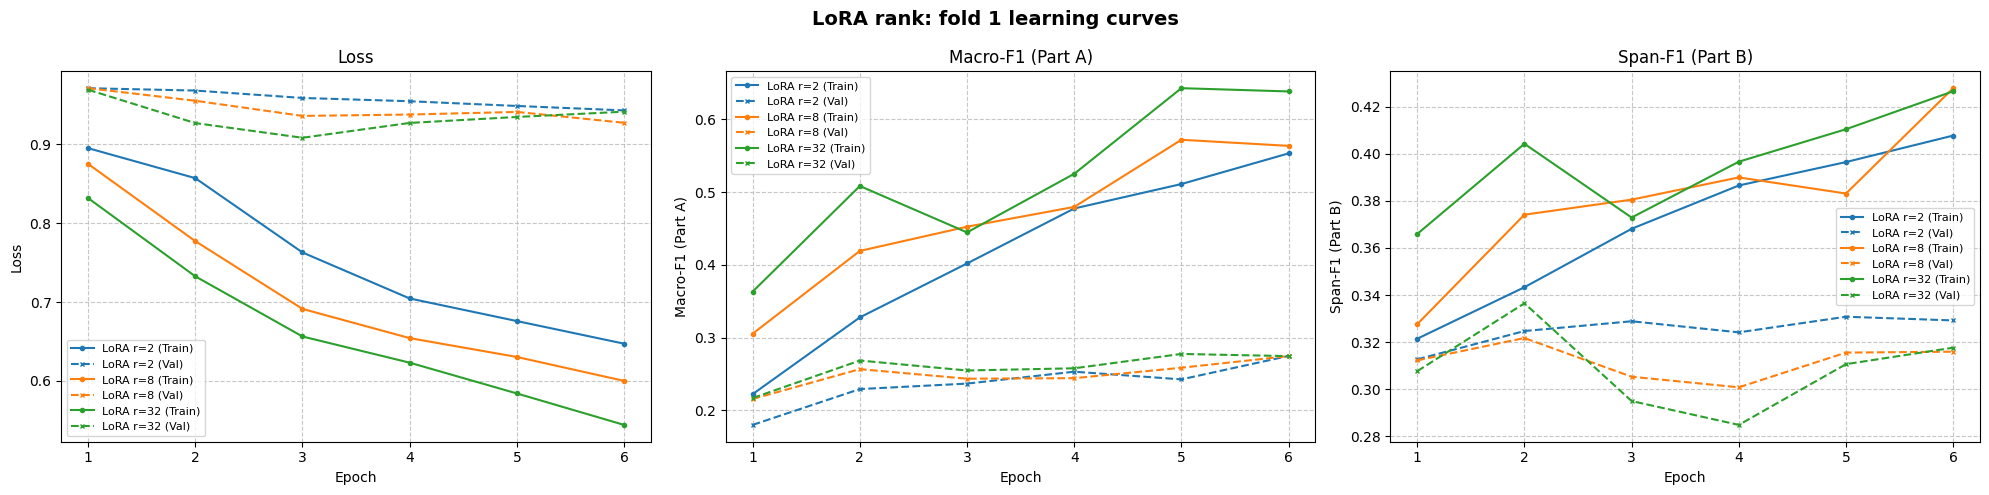

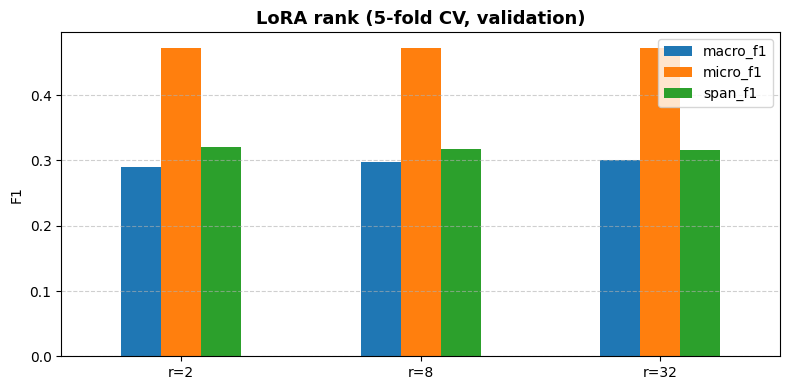

In [47]:
#[9e] Step 2b: LoRA rank search

# ===========================================================
# ITERATION LOG — Attempt 8: LoRA rank search
# ===========================================================
# Signal:       Full fine-tuning ([9c]) updates all ~125M RoBERTa weights from only a few hundred memes per fold,
#               which risks overfitting and is slow and memory-heavy
# Diagnosis:    LoRA (Hu et al., 2021) keeps RoBERTa frozen and trains small adapters instead. Its main setting is
#               the rank r (adapter size), so r is chosen first, before LoRA is compared with full fine-tuning in [9f]
# Model:        RobertaForTechniqueAndSpan, stock heads (RobertaClassificationHead + linear token layer)
# Method:       Two-phase training ([9d]):
#               Phase 1: encoder frozen, heads only (Adam lr = 1e-3, 2 epochs)
#               Phase 2: LoRA adapters on query + value in all 12 attention layers + heads (AdamW lr = 1e-4,
#                        weight decay = 0.01, LoRA dropout = 0.1, lora_alpha = 2r so the scaling is the same for every rank)
# Search:       r ∈ {2, 8, 32} (small / medium / large, ×4 steps; trainable LoRA parameters ~0.07M / ~0.29M / ~1.2M)
# Data:         Original training memes + augmented copies (USE_AUG from [9a-2]); PTC subset as decided in
#               [PTC-6]/[PTC-7] (USE_PTC)
# Train method: 5-fold multilabel stratified cross-validation, same folds as [9a]; validation on original memes only;
#               class weights per fold ([9])
# Action:       λ = best_lambda [10d], pooling = best_pooling [11], name masking from [11b]; same budget for every rank:
#               Phase 2 = 6 epochs with patience = 6 (no early stopping), best of the 6 epochs kept per fold;
#               the only change between runs is lora_r
# Selection:    Ranks compared by mean CV score = (Macro-F1 + Span-F1) / 2
# Decision:     Choose the smallest rank whose mean CV score is within one fold standard deviation of the best
#               rank (a more conservative version of the one-standard-error rule, Hastie et al., 2009): fold scores
#               vary a lot and the folds are not independent, so fewer trainable parameters is preferred when the
#               scores are within the noise
# ===========================================================

#search budget SEARCH_P1, SEARCH_P2, SEARCH_FOLDS is set in the run_search helper cell (before [11])

#small, medium and large ranks
lora_ranks = [2, 8, 32]
rank_results = {}
rank_curves = {}                 #5-fold average learning curves per rank, for plot_experiments

print(f"Step 2b: Tune LoRA rank (λ={best_lambda}, pooling={best_pooling}, name masking p={NAME_MASK_P})")
for r in lora_ranks:
    #trainable parameters for this rank (heads + LoRA adapters)
    tmp = inject_lora(build_two_head_model(pooling=best_pooling), r=r)
    #count_parameters reports how many parameters are trainable (heads plus adapters)
    total_p, trainable_p, _ = count_parameters(tmp)
    #deleted to free gpu
    del tmp
    torch.cuda.empty_cache()
    #runs the full two-phase training on all 5 folds, with the pooling from [11], masking from [11b] and λ from [10d]
    res = run_kfold_twohead_lora(lam=best_lambda, pooling=best_pooling, lora_r=r,
                            p1_epochs=SEARCH_P1, p2_epochs=SEARCH_P2, patience=SEARCH_P2,
                            max_folds=SEARCH_FOLDS, tag=f"LoRA r={r}", verbose=False)
    fold_scores = [v["score"] for v in res["fold_results"].values()]
    #rank_results stores the 5-fold means (score, Macro-F1, Micro-F1, span F1)
    #ddof=1 gives the sample Standard deviation
    rank_results[f"r={r}"] = {**res["summary"], "score_std": float(np.std(fold_scores, ddof=1)),
                              "trainable_params_M": trainable_p / 1e6, "r": r}
    rank_curves[f"LoRA r={r}"] = average_history(res["fold_histories"])      #average over all folds, as in [9f]
    print(f"r={r:2d}: trainable {trainable_p/1e6:.2f}M | CV Macro-F1 {res['summary']['macro_f1']:.4f} | "
          f"CV Span-F1 {res['summary']['span_f1']:.4f} | score {res['summary']['score']:.4f}")
    del res
    gc.collect()

#smallest rank within one fold-std of the best score (cheaper, less overfitting)
best_key = max(rank_results, key=lambda k: rank_results[k]["score"])
cutoff = rank_results[best_key]["score"] - rank_results[best_key]["score_std"]

#he smallest rank that scores at or above the cutoff.
best_r = min(v["r"] for v in rank_results.values() if v["score"] >= cutoff)
print(f"\n✅ Best score: {best_key}. Selected LoRA rank for final model: r={best_r} "
      f"(smallest rank within one std of the best)")

rank_df = pd.DataFrame(rank_results).T[["trainable_params_M", "macro_f1", "micro_f1", "span_f1", "score", "score_std"]].astype(float)
display(rank_df.round(4))

#learning curves (average over all folds) for each rank
plot_experiments(rank_curves, title="LoRA rank: 5-fold average curves")

#CV scores per rank with fold std
ax = rank_df[["macro_f1", "micro_f1", "span_f1"]].plot.bar(figsize=(8, 4), rot=0)
ax.set_title("LoRA rank (5-fold CV, validation)", fontsize=13, fontweight="bold")
ax.set_ylabel("F1")
ax.grid(axis="y", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

LoRA model: Phase 1 heads only, Phase 2 LoRA adapters + heads | r=2, dropout=0.1, wd=0.01, lr=0.0001, λ=1.0, pooling=cls, Phase 1 epochs=5, Phase 2 epochs≤5, patience=2

========== LoRA r2 | FOLD 1/5 ==========
[LoRA r2_F1_P1] Epoch   1/5 | Train Loss: 1.0584 (doc 0.5480, tok 0.5105) | Val Loss: 0.9882 | Val Macro-F1: 0.145 | Val Micro-F1: 0.169 | Val Span-F1: 0.274 | Thr: 0.05/0.35
[LoRA r2_F1_P1] Epoch   5/5 | Train Loss: 0.8289 (doc 0.4633, tok 0.3655) | Val Loss: 0.9508 | Val Macro-F1: 0.261 | Val Micro-F1: 0.438 | Val Span-F1: 0.332 | Thr: 0.25/0.40
[LoRA r2_F1_LoRA] Epoch   1/5 | Train Loss: 0.7819 (doc 0.4343, tok 0.3476) | Val Loss: 0.9345 | Val Macro-F1: 0.260 | Val Micro-F1: 0.457 | Val Span-F1: 0.350 | Thr: 0.25/0.40
[LoRA r2_F1_LoRA] Early stopping at epoch 3. Best epoch 1, Val score 0.305

========== LoRA r2 | FOLD 2/5 ==========
[LoRA r2_F2_P1] Epoch   1/5 | Train Loss: 1.0645 (doc 0.5531, tok 0.5114) | Val Loss: 0.9325 | Val Macro-F1: 0.194 | Val Micro-F1: 0.227 | Val Sp

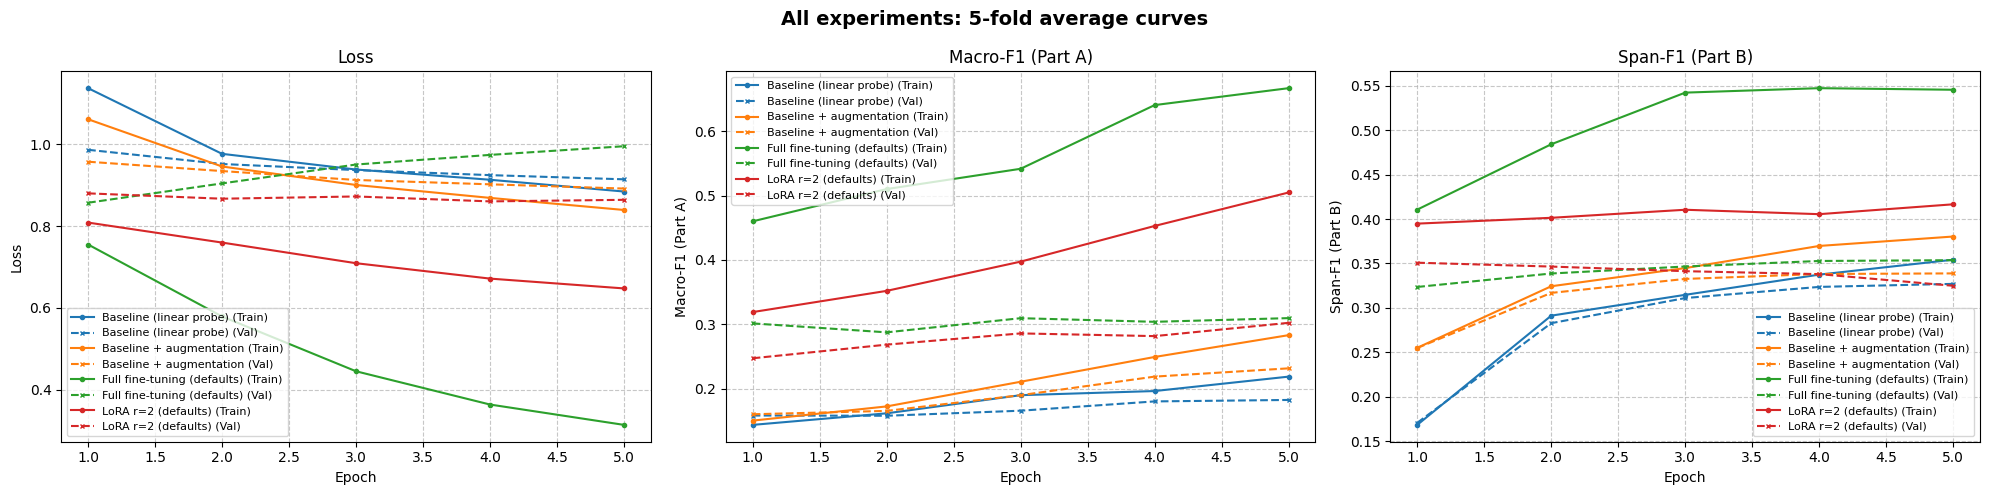


Baseline + augmentation vs Full fine-tuning vs LoRA (all trained on originals + augmented copies)


,CV Macro-F1,CV Micro-F1,CV Span-F1,Phase 2 trainable params (M)
Baseline + augmentation [9a-2],0.231,0.393,0.341,heads only
Full fine-tuning [9c],0.311,0.489,0.358,125.0
LoRA r=2,0.296,0.468,0.342,0.99


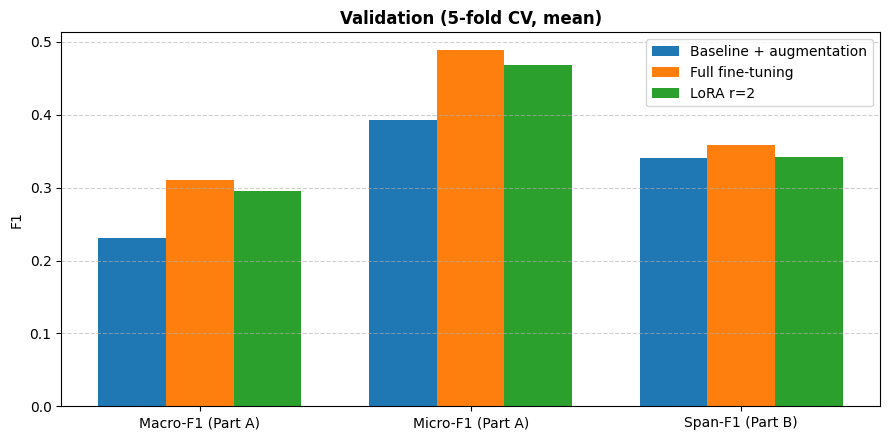

Macro-F1 (LoRA − full) -0.015 (LoRA better in 2/5 folds) | Span-F1 (LoRA − full) -0.016 (LoRA better in 0/5 folds)
USE_LORA = True


In [48]:
#[9f] LoRA (rank selected in [9e]) vs full fine-tuning ([9c])

# ===========================================================
# ITERATION LOG — Attempt 9: LoRA (rank from [9e]) vs full fine-tuning
# ===========================================================
# Signal:       Full fine-tuning ([9c]) trains all ~125M weights on a few hundred memes per fold; it is slow,
#               memory-heavy and can overfit
# Diagnosis:    Test whether LoRA with the rank chosen in [9e] matches full fine-tuning with far fewer trainable
#               parameters, using the same data, folds and epoch budget
# Model:        RobertaForTechniqueAndSpan, stock heads (RobertaClassificationHead + linear token layer)
# Method:       Two-phase training ([9d]):
#               Phase 1: encoder frozen, heads only (Adam lr = 1e-3, P1 epochs = 5)
#               Phase 2: LoRA adapters on query + value (r from [9e], lora_alpha = 2r, dropout = 0.1) + heads
#                        (AdamW lr = 1e-4, weight decay = 0.01, P2 epochs ≤ 5, early-stopping patience = 2)
# Data:         Original training memes + augmented copies (USE_AUG from [9a-2]); PTC subset as decided in
#               [PTC-6]/[PTC-7] (USE_PTC)
# Train method: 5-fold multilabel stratified cross-validation, same folds as [9a]; validation on original memes only;
#               class weights per fold ([9])
# Action:       Same epochs, patience, λ = 1.0, pooling = cls and no name masking as [9c]; the change is LoRA instead of
#               full fine-tuning in Phase 2. Training time and peak GPU memory are also recorded
# Reference:    Full fine-tuning ([9c]), compared fold by fold on the same validation folds;
#               the frozen probe ([9a-2]) is shown for context
# Decision:     LoRA is kept for the rest of the search unless full fine-tuning is clearly better on the paired
#               rule (mean fold gain in Macro-F1 larger than LoRA's fold std AND better in at least 4 of 5 folds),
#               because it trains far fewer parameters and is cheaper to run
# ===========================================================

# Like-for-like comparison: all three models train on the original memes + augmented copies

#settings should be set correctly if not then halt and print:
assert USE_AUG, "USE_AUG is False: run [9a-2] in this session before [9f]"
assert not USE_PTC, "USE_PTC is True, but should be false as performance was worse"


# LoRA configuration: rank selected in [9e], other settings at their defaults
BEST_R = best_r
DEFAULT_LORA_DROPOUT = 0.1
DEFAULT_WD = 0.01
DEFAULT_LR = 1e-4
#pooling stays cls (BASELINE_POOLING), λ stays 1.0 and name masking is switched off here (not the values chosen in
#[11], [10d], [11b]), so the comparison with full fine-tuning [9c] is like-for-like: the only difference is LoRA vs full

# Run the LoRA model with the same set up as [9c] with best rank
print(
    f"LoRA model: Phase 1 heads only, Phase 2 LoRA adapters + heads | r={BEST_R}, "
    f"dropout={DEFAULT_LORA_DROPOUT}, wd={DEFAULT_WD}, lr={DEFAULT_LR}, "
    f"λ={BASELINE_LAM}, pooling={BASELINE_POOLING}, "
    f"Phase 1 epochs={P1_EPOCHS}, Phase 2 epochs≤{P2_EPOCHS}, patience={PATIENCE}"
)

#training with the best rank (name masking off for this run only, restored afterwards)
_saved_mask_p, NAME_MASK_P = NAME_MASK_P, 0.0
try:
    lora_res = run_kfold_twohead_lora(
        lam=BASELINE_LAM,
        pooling=BASELINE_POOLING,
        lora_r=BEST_R,
        lora_dropout=DEFAULT_LORA_DROPOUT,
        weight_decay=DEFAULT_WD,
        ft_lr=DEFAULT_LR,
        p1_epochs=P1_EPOCHS,
        p2_epochs=P2_EPOCHS,
        patience=PATIENCE,
        tag=f"LoRA r{BEST_R}",
        use_aug=True
    )
finally:
    NAME_MASK_P = _saved_mask_p                   #every later search uses the masking decision from [11b]


#store fold histories and plot the results
all_results[f"LoRA r={BEST_R} (defaults)"] = average_history(lora_res["fold_histories"])

plot_experiments(all_results, title="All experiments: 5-fold average curves")

lora_fold_df = pd.DataFrame(lora_res["fold_results"]).T

# Save the cross-validation scores
results_scores[
    f"LoRA r={BEST_R}, default settings (λ=1, cls)"
] = cv_scores(lora_res)

# Trainable parameters in Phase 2 (full fine-tuning: everything; LoRA: adapters + heads)
tmp_full = build_two_head_model(pooling=BASELINE_POOLING)
full_total, _, _ = count_parameters(tmp_full)
tmp_lora = inject_lora(build_two_head_model(pooling=BASELINE_POOLING), r=BEST_R, lora_dropout=DEFAULT_LORA_DROPOUT)
_, lora_trainable, _ = count_parameters(tmp_lora)
del tmp_full, tmp_lora
if torch.cuda.is_available():
    torch.cuda.empty_cache()

#comparison: baseline + augmentation vs full fine-tuning vs LoRA
print("\nBaseline + augmentation vs Full fine-tuning vs LoRA (all trained on originals + augmented copies)")
#set up a comparison df (cv_row is defined in [9a-2])
comparison_df = pd.DataFrame({
    "Baseline + augmentation [9a-2]": cv_row(bla_fold_df),
    "Full fine-tuning [9c]": cv_row(def_fold_df),
    f"LoRA r={BEST_R}": cv_row(lora_fold_df)
}).T
comparison_df["Phase 2 trainable params (M)"] = ["heads only", f"{full_total / 1e6:.1f}", f"{lora_trainable / 1e6:.2f}"]

display(comparison_df)


###compare results fold by fold using the same validation folds
paired_lora = pd.DataFrame(
    {
        "full macro": def_fold_df["macro_f1"].values,
        "LoRA macro": lora_fold_df["macro_f1"].values,
        "full span": def_fold_df["span_f1"].values,
        "LoRA span": lora_fold_df["span_f1"].values,
    },
    index=[
        f"Fold {k + 1}"
        for k in range(len(lora_fold_df))
    ]
)
#cal the change in F1 scores (LoRA − full fine-tuning)
paired_lora["macro"] = (
    paired_lora["LoRA macro"] - paired_lora["full macro"]
)

paired_lora["span"] = (
    paired_lora["LoRA span"] - paired_lora["full span"]
)

###fig: validation mean results compared
metrics = [
    ("macro_f1", "Macro-F1 (Part A)"),
    ("micro_f1", "Micro-F1 (Part A)"),
    ("span_f1", "Span-F1 (Part B)")
]
x = np.arange(len(metrics))
w = 0.25
fig, ax = plt.subplots(figsize=(9, 4.5))
#models to compare
models = [
    ("Baseline + augmentation", bla_fold_df),
    ("Full fine-tuning", def_fold_df),
    (f"LoRA r={BEST_R}", lora_fold_df)
]
#get the statistics for the models - three bars per metric
for j, (name, fold_df) in enumerate(models):
    means = [
        fold_df[metric].mean()
        for metric, _ in metrics
    ]
    ax.bar(
        x + (j - 1) * w,
        means,
        w,
        label=name
    )
ax.set_xticks(x)
ax.set_xticklabels([
    label for _, label in metrics
])
ax.set_title(
    "Validation (5-fold CV, mean)",
    fontsize=12,
    fontweight="bold"
)
ax.set_ylabel("F1")
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

### Decision: keep LoRA unless full fine-tuning is clearly better (same paired rule, in the other direction)
full_gain = -paired_lora["macro"].mean()                       #how much full fine-tuning beats LoRA on average
n_full_better = int((paired_lora["macro"] < 0).sum())
FULL_CLEARLY_BETTER = bool(full_gain > lora_fold_df["macro_f1"].std() and n_full_better >= 4)
USE_LORA = not FULL_CLEARLY_BETTER

print(
    f"Macro-F1 (LoRA − full) {paired_lora['macro'].mean():+.3f} "
    f"(LoRA better in {int((paired_lora['macro'] > 0).sum())}/{len(paired_lora)} folds) | "
    f"Span-F1 (LoRA − full) {paired_lora['span'].mean():+.3f} "
    f"(LoRA better in {int((paired_lora['span'] > 0).sum())}/{len(paired_lora)} folds)"
)
print(f"USE_LORA = {USE_LORA}")

In [ ]:
# [10a]: Best LoRA Dropout Search

# ===========================================================
# ITERATION LOG — Attempt 10: LoRA dropout search
# ===========================================================
# Signal:       LoRA ([9f]) ran with default settings (dropout = 0.1, weight decay = 0.01, lr = 1e-4) that were never
#               tuned; with only a few hundred memes per fold, how strongly the adapters are regularised may matter
# Diagnosis:    Tune LoRA dropout first (dropout applied to the adapter input during training, so the adapters cannot
#               rely on any single feature), keeping every other setting fixed
# Model:        RobertaForTechniqueAndSpan, stock heads (RobertaClassificationHead + linear token layer)
# Method:       Two-phase training ([9d]): Phase 1 heads only (Adam lr = 1e-3), Phase 2 LoRA adapters on query + value
#               (r = BEST_R from [9e], lora_alpha = 2r) + heads (AdamW lr = 1e-4, weight decay = 0.01)
# Search:       lora_dropout ∈ {0.00, 0.05, 0.10, 0.15} (0.00 = no dropout; 0.10 = the default used in [9e]/[9f])
# Data:         Original training memes + augmented copies (USE_AUG from [9a-2]); PTC subset as decided in
#               [PTC-6]/[PTC-7] (USE_PTC)
# Train method: 5-fold multilabel stratified cross-validation, same folds as [9a]; validation on original memes only;
#               class weights per fold ([9])
# Action:       Same search budget as [9e] for every value: Phase 1 = 2 epochs, Phase 2 = 6 epochs with patience = 6
#               (no early stopping), best of the 6 epochs kept per fold; λ = best_lambda [10d],
#               pooling = best_pooling [11], name masking from [11b]; the only change between runs is lora_dropout
# Selection:    run_search; values compared by mean CV score = (Macro-F1 + Span-F1) / 2 (SELECT_METRIC)
# Decision:     The dropout with the highest mean CV score is carried into [10b] (best_dropout); weight decay and
#               learning rate are tuned next with this value fixed (sequential search, one setting at a time)
# ===========================================================

dropout_rates = [0.00, 0.05, 0.10, 0.15]

print(f"Stage 1: Tune LoRA Dropout (λ={best_lambda}, pooling={best_pooling}, r={BEST_R})")
best_dropout, best_score_drop, dropout_results = run_search(
    "Stage1",
    "lora_dropout",
    dropout_rates,
    lam=best_lambda,             #[10d]
    pooling=best_pooling,        #[11]
    lora_r=BEST_R,
    lora_dropout=0.1,
    weight_decay=0.01,
    ft_lr=1e-4,
    p1_epochs=SEARCH_P1,
    p2_epochs=SEARCH_P2,
    patience=SEARCH_P2,
    max_folds=SEARCH_FOLDS,

)
print(f"\n✅ Best dropout for Stage 2: {best_dropout} ({SELECT_METRIC}: {best_score_drop:.4f})")

In [ ]:
# [10b]: Best Weight Decay Search

# ===========================================================
# ITERATION LOG — Attempt 11: Weight decay search
# ===========================================================
# Signal:       Weight decay was left at its default (0.01) in [9f] and [10a]; it is the second regulariser on the
#               trainable weights, and with a few hundred memes per fold the right amount of shrinkage may differ
# Diagnosis:    Tune AdamW weight decay (each step shrinks the trainable weights, i.e. the LoRA adapters and heads,
#               slightly towards zero, which discourages large weights that fit the training memes too closely),
#               with the dropout from [10a] fixed
# Model:        RobertaForTechniqueAndSpan, stock heads (RobertaClassificationHead + linear token layer)
# Method:       Two-phase training ([9d]): Phase 1 heads only (Adam lr = 1e-3), Phase 2 LoRA adapters on query + value
#               (r = BEST_R from [9e], lora_alpha = 2r, dropout = best_dropout from [10a]) + heads (AdamW lr = 1e-4)
# Search:       weight_decay ∈ {0, 1e-4, 1e-3, 0.01} (0 = no decay; ×10 steps up to the default 0.01)
# Data:         Original training memes + augmented copies (USE_AUG from [9a-2]); PTC subset as decided in
#               [PTC-6]/[PTC-7] (USE_PTC)
# Train method: 5-fold multilabel stratified cross-validation, same folds as [9a]; validation on original memes only;
#               class weights per fold ([9])
# Action:       Same search budget as [9e]/[10a] for every value: Phase 1 = 2 epochs, Phase 2 = 6 epochs with
#               patience = 6 (no early stopping), best of the 6 epochs kept per fold; λ = best_lambda
#               [10d], pooling = best_pooling [11], name masking from [11b]; the only change between runs is weight_decay
# Selection:    run_search; values compared by mean CV score = (Macro-F1 + Span-F1) / 2 (SELECT_METRIC)
# Decision:     The weight decay with the highest mean CV score is carried into [10c] (best_wd); the learning rate
#               is tuned next with dropout and weight decay fixed (sequential search, one setting at a time)
# ===========================================================


weight_decays = [0.0, 1e-4, 1e-3, 0.01]

print(f"Stage 2: Tune Weight Decay (dropout={best_dropout}, λ={best_lambda}, pooling={best_pooling})")
best_wd, best_score_wd, wd_results = run_search(
    "Stage2",
    "weight_decay",
    weight_decays,
    lam=best_lambda,             #[10d]
    pooling=best_pooling,        #[11]
    lora_r=BEST_R,
    lora_dropout=best_dropout,   #from [10a]
    weight_decay=0.01,      #replaced by each value being tested
    ft_lr=1e-4,
    p1_epochs=SEARCH_P1, p2_epochs=SEARCH_P2, patience=SEARCH_P2, max_folds=SEARCH_FOLDS,
    label_fmt="{:g}",
)
print(f"\n✅ Best weight decay for Stage 3: {best_wd} ({SELECT_METRIC}: {best_score_wd:.4f})")

In [ ]:
# [10c]: Best Learning Rate Search

# ===========================================================
# ITERATION LOG — Attempt 12: Learning rate search
# ===========================================================
# Signal:       The Phase 2 learning rate was left at its default (1e-4) in [9f]–[10b]; it controls how far the
#               LoRA adapters and heads move each step, and is usually the setting that matters most for fine-tuning
# Diagnosis:    Tune the Phase 2 learning rate (AdamW, shared by the LoRA adapters and heads), with the dropout from
#               [10a] and the weight decay from [10b] fixed
# Model:        RobertaForTechniqueAndSpan, stock heads (RobertaClassificationHead + linear token layer)
# Method:       Two-phase training ([9d]): Phase 1 heads only (Adam lr = 1e-3), Phase 2 LoRA adapters on query + value
#               (r = BEST_R from [9e], lora_alpha = 2r, dropout = best_dropout from [10a]) + heads
#               (AdamW, weight decay = best_wd from [10b]); no learning-rate schedule
# Search:       ft_lr ∈ {1e-5, 3e-5, 5e-5, 1e-4} (from the typical full fine-tuning range up to the default 1e-4)
# Data:         Original training memes + augmented copies (USE_AUG from [9a-2]); PTC subset as decided in
#               [PTC-6]/[PTC-7] (USE_PTC)
# Train method: 5-fold multilabel stratified cross-validation, same folds as [9a]; validation on original memes only;
#               class weights per fold ([9])
# Action:       Same search budget as [9e]–[10b] for every value: Phase 1 = 2 epochs, Phase 2 = 6 epochs with
#               patience = 6 (no early stopping), best of the 6 epochs kept per fold; λ = best_lambda
#               [10d], pooling = best_pooling [11], name masking from [11b]; the only change between runs is ft_lr
# Selection:    run_search; values compared by mean CV score = (Macro-F1 + Span-F1) / 2 (SELECT_METRIC)
# Decision:     The learning rate with the highest mean CV score is used in [12] onwards (best_lr); the three
#               tuned LoRA settings (dropout, weight decay, learning rate) are saved to twohead_hparam_search.json
#               so they can be reloaded without repeating the search
# ===========================================================


learning_rates = [1e-5, 3e-5, 5e-5, 1e-4]

print(f"Stage 3: Tune Learning Rate (dropout={best_dropout}, WD={best_wd}, λ={best_lambda}, pooling={best_pooling})")
best_lr, best_score_lr, lr_results = run_search(
    "Stage3",
    "ft_lr",
    learning_rates,
    lam=best_lambda,             #[10d]
    pooling=best_pooling,        #[11]
    lora_r=BEST_R,
    lora_dropout=best_dropout,   #from [10a]
    weight_decay=best_wd,        #from [10b]
    ft_lr=1e-4,                  #replaced by each value being tested
    p1_epochs=SEARCH_P1, p2_epochs=SEARCH_P2, patience=SEARCH_P2, max_folds=SEARCH_FOLDS,
    label_fmt="{:.0e}",
)
print(f"\n✅ Best LR: {best_lr} ({SELECT_METRIC}: {best_score_lr:.4f})")
print(f"Best config: lora_dropout={best_dropout}, weight_decay={best_wd}, ft_lr={best_lr}")

with open("twohead_hparam_search.json", "w") as f:
    json.dump({"pooling": best_pooling, "name_mask_p": NAME_MASK_P, "lam": best_lambda, "lora_r": BEST_R,
               "lora_dropout": best_dropout, "weight_decay": best_wd, "ft_lr": best_lr,
               "select_metric": SELECT_METRIC}, f, indent=1)

### Step 3: Final two-head model (full training with the selected settings)

Final config: λ=1.0, pooling=attn, LoRA r=8, dropout=0.0, weight decay=0.0, lr=0.0001

========== TwoHead | FOLD 1/5 ==========
[TwoHead_F1_P1] Epoch   1/5 | Train Loss: 1.0804 (doc 0.5375, tok 0.5428) | Val Loss: 0.9360 | Val Macro-F1: 0.219 | Val Micro-F1: 0.301 | Val Span-F1: 0.201 | Thr: 0.25/0.35
[TwoHead_F1_P1] Epoch   5/5 | Train Loss: 0.6785 (doc 0.2876, tok 0.3909) | Val Loss: 0.8816 | Val Macro-F1: 0.273 | Val Micro-F1: 0.464 | Val Span-F1: 0.321 | Thr: 0.30/0.35
[TwoHead_F1_LoRA] Epoch   1/5 | Train Loss: 0.6488 (doc 0.2641, tok 0.3847) | Val Loss: 0.9216 | Val Macro-F1: 0.275 | Val Micro-F1: 0.485 | Val Span-F1: 0.334 | Thr: 0.35/0.40
[TwoHead_F1_LoRA] Epoch   5/5 | Train Loss: 0.4844 (doc 0.1873, tok 0.2971) | Val Loss: 1.0804 | Val Macro-F1: 0.280 | Val Micro-F1: 0.518 | Val Span-F1: 0.340 | Thr: 0.30/0.55

========== TwoHead | FOLD 2/5 ==========
[TwoHead_F2_P1] Epoch   1/5 | Train Loss: 1.0791 (doc 0.5292, tok 0.5499) | Val Loss: 0.9472 | Val Macro-F1: 0.200 | Val Micro

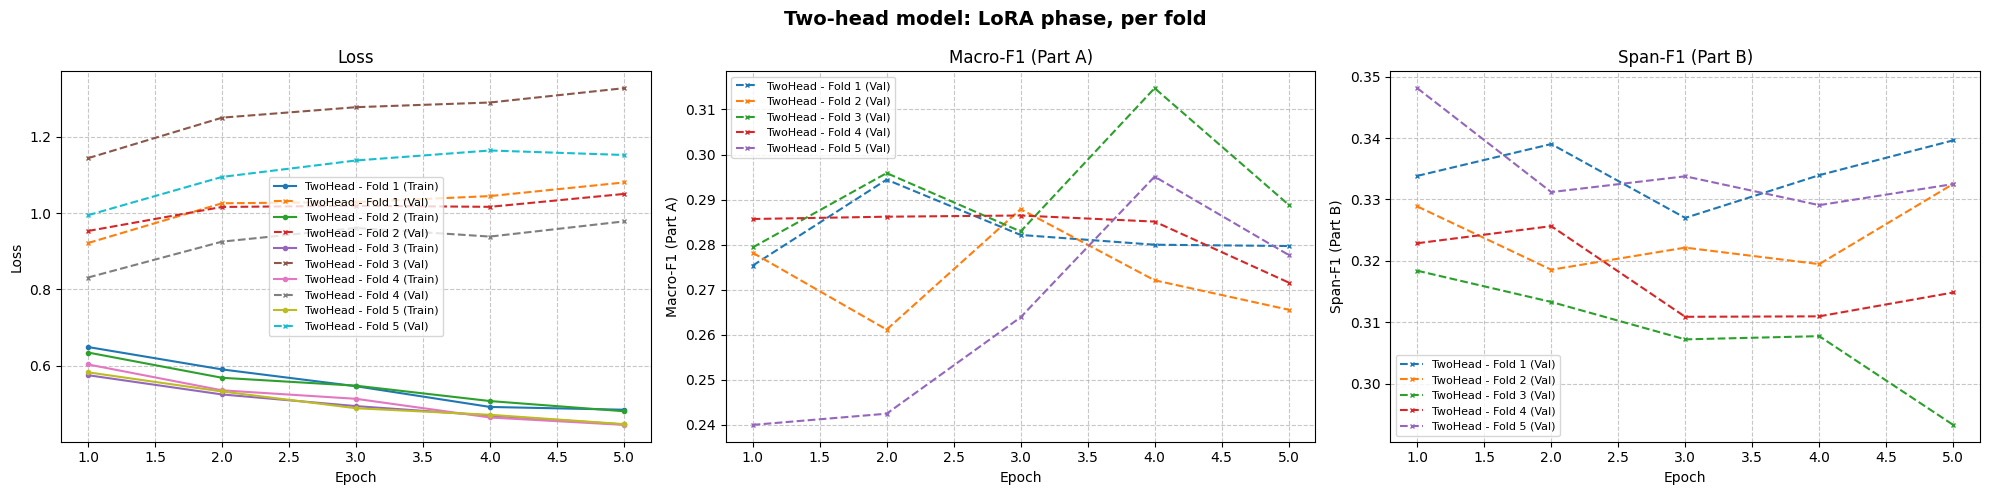

,epoch,score,macro_f1,micro_f1,span_f1,thr,tok_thr
TwoHead - Fold 1,2.0,0.317,0.294,0.520,0.339,0.35,0.45
TwoHead - Fold 2,3.0,0.305,0.288,0.462,0.322,0.25,0.50
TwoHead - Fold 3,4.0,0.311,0.315,0.472,0.308,0.30,0.55
TwoHead - Fold 4,2.0,0.306,0.286,0.500,0.326,0.35,0.50
TwoHead - Fold 5,4.0,0.312,0.295,0.462,0.329,0.10,0.50



--- Cross Validation Summary (5 Folds) ---
Average Val Macro-F1: 0.296 ± 0.011
Average Val Micro-F1: 0.483 ± 0.026
Average Val Span-F1:  0.325 ± 0.011


In [50]:
#[12] Step 3: final 5-fold training with every selected setting

print(f"Final config: λ={best_lambda}, pooling={best_pooling}, LoRA r={BEST_R}, "
      f"dropout={best_dropout}, weight decay={best_wd}, lr={best_lr}")

final_res = run_kfold_twohead_lora(
    lam=best_lambda,                  #[10d]
    pooling=best_pooling,             #[11]
    lora_r=BEST_R,                    #[9e]
    lora_dropout=best_dropout,        #[10a]
    weight_decay=best_wd,             #[10b]
    ft_lr=best_lr,                    #[10c]
    p1_epochs=P1_EPOCHS,
    p2_epochs=P2_EPOCHS,
    patience=PATIENCE,
    tag="TwoHead")

with open("twohead_final_config.json", "w") as f:
    json.dump(final_res["config"], f, indent=1)

all_results["Final model"] = average_history(final_res["fold_histories"])
plot_experiments(all_results, title="All experiments: 5-fold average curves")

fold_df = pd.DataFrame(final_res["fold_results"]).T
display(fold_df.round(3))

print(f"\n--- Cross Validation Summary ({K_FOLDS} Folds) ---")
print(f"Average Val Macro-F1: {final_res['summary']['macro_f1']:.3f}")
print(f"Average Val Micro-F1: {final_res['summary']['micro_f1']:.3f}")
print(f"Average Val Span-F1:  {final_res['summary']['span_f1']:.3f}")

In [ ]:
#[12b] Step 3b: head design with make_head (stock RoBERTa heads vs designed 2-layer MLP heads)
#same settings and search budget as [11]; if the designed heads pass the paired rule, the final 5-fold model is
#retrained with them so that [13] tests it. [7]-[12] are not edited: build_two_head_model is wrapped below.

HEAD_WIDTHS = [128, 256, 512]           #hidden width h of the designed heads (each width costs one [11]-sized run)
assert final_res["config"].get("head_type", "roberta") == "roberta", \
    "final_res already has the designed heads: re-run [12] before re-running this cell"


class MLPHead(nn.Module):
    '''Designed head: Dropout -> Linear(H -> h) -> GELU -> Dropout -> Linear(h -> C).
    first_token=True reads position 0 of a (B, T, H) input, the same interface as RobertaClassificationHead,
    because [7] passes the pooled meme vector to the doc head as a one-token sequence.'''
    def __init__(self, in_dim, hidden, out_dim, dropout, first_token=False):
        super().__init__()
        self.first_token = first_token
        self.net = nn.Sequential(nn.Dropout(dropout), nn.Linear(in_dim, hidden), nn.GELU(),
                                 nn.Dropout(dropout), nn.Linear(hidden, out_dim))

    def forward(self, x):
        return self.net(x[:, 0] if self.first_token else x)       #(B, C) for the doc head, (B, T, C) for tokens


def make_head(task, config, hidden):
    '''Builds the designed head for task "doc" (one prediction per meme) or "tok" (one prediction per token).
    Weights start the same way as RoBERTa's own heads: normal(0, initializer_range), zero bias.'''
    dropout = config.classifier_dropout if config.classifier_dropout is not None else config.hidden_dropout_prob
    head = MLPHead(config.hidden_size, hidden, config.num_labels, dropout, first_token=(task == "doc"))
    for m in head.modules():
        if isinstance(m, nn.Linear):
            nn.init.normal_(m.weight, mean=0.0, std=config.initializer_range)
            nn.init.zeros_(m.bias)
    return head


#wrap the [7] builder: same model, with the two heads replaced by make_head when the head type is "mlp".
#run_kfold_twohead_lora ([9d]) and load_fold_model ([13]) call build_two_head_model by name, so they pick this up.
if "_build_two_head_model_stock" not in globals():           #keep the original even if this cell is re-run
    _build_two_head_model_stock = build_two_head_model
ACTIVE_HEAD_TYPE, ACTIVE_HEAD_HIDDEN = "roberta", 256


def build_two_head_model(pooling="attn", head_hidden=None, head_type=None):
    head_type = head_type or ACTIVE_HEAD_TYPE
    head_hidden = head_hidden or ACTIVE_HEAD_HIDDEN
    model = _build_two_head_model_stock(pooling=pooling, head_hidden=head_hidden)
    if head_type == "mlp":
        model.doc_head = make_head("doc", model.config, head_hidden).to(device)
        model.tok_head = make_head("tok", model.config, head_hidden).to(device)
    model.config.head_type = head_type
    return model


#size of each design (the heads only; attention pooling is the same in all of them)
_cfg = AutoConfig.from_pretrained(MODEL_NAME, num_labels=NUM_CLASSES)
n_params = lambda *mods: sum(p.numel() for m in mods for p in m.parameters()) / 1e6
head_size = {"stock": n_params(RobertaClassificationHead(_cfg), nn.Linear(_cfg.hidden_size, NUM_CLASSES))}
head_size.update({f"MLP h={h}": n_params(make_head("doc", _cfg, h), make_head("tok", _cfg, h)) for h in HEAD_WIDTHS})

search_kw = dict(lam=best_lambda, pooling=best_pooling, lora_r=BEST_R, lora_dropout=best_dropout,
                 weight_decay=best_wd, ft_lr=best_lr, p1_epochs=SEARCH_P1, p2_epochs=SEARCH_P2,
                 patience=SEARCH_P2, max_folds=SEARCH_FOLDS)
print(f"Step 3b: head design (λ={best_lambda}, pooling={best_pooling}, r={BEST_R}, dropout={best_dropout}, "
      f"wd={best_wd}, lr={best_lr}); same search budget as [11]")

#stock heads: [11] already ran exactly this configuration (best pooling, stock heads, same settings and seeds),
#so its row is reused instead of training it again
if "design_df" in globals() and best_pooling in design_df.index:
    stock_df = design_df.loc[[best_pooling]].rename(index={best_pooling: "stock"})
    print(f"stock heads: reusing the pooling={best_pooling} row from [11]")
else:
    _, _, stock_df = run_search("Step3b", "head_hidden", [256], **search_kw)
    stock_df = stock_df.rename(index={256: "stock"})

try:
    ACTIVE_HEAD_TYPE = "mlp"
    _, _, mlp_df = run_search("Step3b", "head_hidden", HEAD_WIDTHS, **search_kw)
finally:
    ACTIVE_HEAD_TYPE = "roberta"                                #never leave the search setting active
mlp_df = mlp_df.rename(index={h: f"MLP h={h}" for h in HEAD_WIDTHS})

head_df = pd.concat([stock_df, mlp_df])
head_df.index.name = "head"
head_df["head params (M)"] = [head_size[k] for k in head_df.index]
display(head_df[["head params (M)", "score", "score_std", "macro_f1", "micro_f1", "span_f1"]].round(4))

#decision: attention pooling is already the self-built segment, so the stock heads are the default and the
#best designed head replaces them only if it passes the paired rule (as in [9a-2], [PTC-6], [11]).
#if pooling fell back to cls/mean, the model would have no designed segment left, so the roles are swapped.
best_mlp = max(mlp_df.index, key=lambda k: head_df.loc[k, "score"])
default, cand = ("stock", best_mlp) if best_pooling == DESIGNED_POOLING else (best_mlp, "stock")
replace, gain, n_better = beats_default(head_df, cand, default)
chosen_head = cand if replace else default
print(f"Best designed head: {best_mlp}")
print(f"{cand} vs {default}: mean paired Δ score {gain:+.4f}, better in {n_better}/{SEARCH_FOLDS} folds "
      f"(needs > {np.std(head_df.loc[default, 'fold_score'], ddof=1):.4f} and ≥ 4/5) "
      f"-> {'replaces ' + default if replace else 'does not pass the rule'}")
BEST_HEAD_TYPE = "roberta" if chosen_head == "stock" else "mlp"
BEST_HEAD_HIDDEN = 256 if chosen_head == "stock" else int(chosen_head.split("h=")[1])
print(f"\n✅ Heads for the final model: {chosen_head}")

#figure: combined score with fold std, and Part A / Part B
labels_short = list(head_df.index)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].bar(labels_short, head_df["score"], yerr=head_df["score_std"], capsize=4,
            color=["#999999" if k == "stock" else "#1f77b4" for k in labels_short])
for x, k in enumerate(labels_short):
    axes[0].text(x, 0.005, f"{head_size[k]:.2f}M", ha="center", va="bottom", fontsize=8, color="white")
axes[0].set_title("Head design: combined CV score (mean ± fold std)", fontsize=12, fontweight="bold")
axes[0].set_ylabel("mean(doc Macro-F1, span F1)")
axes[0].grid(axis="y", linestyle="--", alpha=0.6)
head_df[["macro_f1", "span_f1"]].plot.bar(ax=axes[1], rot=0,
                                          yerr=head_df[["macro_std", "span_std"]].values.T, capsize=3)
axes[1].set_title("Head design: Part A and Part B (5-fold CV)", fontsize=12, fontweight="bold")
axes[1].set_ylabel("F1")
axes[1].grid(axis="y", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

# ---------- final model with the chosen heads ----------
ACTIVE_HEAD_TYPE, ACTIVE_HEAD_HIDDEN = BEST_HEAD_TYPE, BEST_HEAD_HIDDEN     #used by load_fold_model in [13] onwards
if BEST_HEAD_TYPE == "roberta":
    final_res["config"]["head_type"] = "roberta"
    print("Stock heads kept: the final model trained in [12] is the one [13] tests (no retraining).")
else:
    stock_final = {k: final_res[k] for k in ["summary", "fold_results"]}  #[12] CV results, kept for the comparison
    del final_res
    torch.cuda.empty_cache()
    gc.collect()
    print(f"Retraining the final 5-fold model with {chosen_head} (same epochs and settings as [12])")
    final_res = run_kfold_twohead_lora(
        lam=best_lambda, pooling=best_pooling, head_hidden=BEST_HEAD_HIDDEN, lora_r=BEST_R,
        lora_dropout=best_dropout, weight_decay=best_wd, ft_lr=best_lr,
        p1_epochs=P1_EPOCHS, p2_epochs=P2_EPOCHS, patience=PATIENCE, tag="TwoHead-MLP")
    final_res["config"]["head_type"] = "mlp"

    with open("twohead_final_config.json", "w") as f:
        json.dump(final_res["config"], f, indent=1)
    all_results[f"Final model ({chosen_head})"] = average_history(final_res["fold_histories"])
    plot_experiments(final_res["fold_histories"], title=f"Two-head model with {chosen_head}: LoRA phase, per fold")

    fold_df = pd.DataFrame(final_res["fold_results"]).T
    display(fold_df.round(3))
    print(f"\n--- Cross Validation Summary ({K_FOLDS} Folds): stock heads [12] vs {chosen_head} ---")
    print(pd.DataFrame({"stock heads [12]": stock_final["summary"], chosen_head: final_res["summary"]}).T
          [["score", "macro_f1", "micro_f1", "span_f1"]].round(3).to_string())

## Final Evaluation — The Certificate
The **official SemEval test set** (`test_set_task2.txt`) has been untouched throughout: no cell before [13] loads it, and every comparison and choice above uses 5-fold cross-validation on the training memes. It is loaded in [13] and used **exactly once**. One test meme that also appears in the training file is dropped, so every test meme is unseen.
* Each of the 5 fold models predicts the test memes; the **ensemble** averages their probabilities and uses the mean of the five validation thresholds. Averaging the folds is preferred to picking the single best fold, whose validation score is optimistically biased by being the maximum of five.
* The per-fold test scores are also reported to show how much the result depends on which memes a model was trained on.

In [51]:
#[13] final test evaluation: per-fold models and the 5-fold ensemble
#the official SemEval test set is loaded HERE for the first time and used exactly once; nothing before this cell
#has seen it, and no setting is changed after this point
with open("test_set_task2.txt", "r", encoding="utf-8") as f:
    df_test = pd.DataFrame(json.load(f))
df_test["id"] = df_test["id"].astype(str)

#a test meme that also appears in the training file would not be unseen: drop it
dup = df_test["id"].isin(df2["id"]) | df_test["text"].str.strip().isin(df2["text"].str.strip())
if dup.any():
    print(f"Dropped {int(dup.sum())} test meme(s) also in the training file: {df_test.loc[dup, 'id'].tolist()}")
    df_test = df_test[~dup].reset_index(drop=True)

#gold spans (start, end, technique) and document labels, on the same 20 techniques as training
TEST_SPANS = df_test["labels"].apply(
    lambda ls: [(int(l["start"]), int(l["end"]), l["technique"]) for l in ls if l["technique"] in label2id]).tolist()
Y_TEST = np.array([[1.0 if t in {s[2] for s in sp} else 0.0 for t in TECHNIQUES] for sp in TEST_SPANS], dtype=np.float32)
test_dataset = TwoHeadDataset(df_test["text"].tolist(), TEST_SPANS, Y_TEST, tokenizer)
print(f"Official test set: {len(df_test)} memes ({int((Y_TEST.sum(1) == 0).sum())} with no technique), "
      f"{sum(map(len, TEST_SPANS))} spans")

test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_gold = TEST_SPANS
cfg = final_res["config"]

def load_fold_model(state):
    model = build_two_head_model(pooling=cfg["pooling"])
    if cfg.get("finetune", "lora") == "lora":
        model = inject_lora(model, r=cfg["lora_r"], lora_dropout=cfg["lora_dropout"])
    load_info = model.load_state_dict(state, strict=False)
    #every saved weight must find its place in the rebuilt model
    assert not load_info.unexpected_keys, load_info.unexpected_keys[:5]
    model.eval()
    return model

per_fold_test = {}
ens_doc, ens_tok = None, None
for k, (state, fr) in enumerate(zip(final_res["fold_states"], final_res["fold_results"].values())):
    model = load_fold_model(state)
    model.set_loss_weights(None, None, cfg["lam"])
    r = evaluate_model(model, test_loader, test_gold, threshold=fr["thr"], tok_threshold=fr["tok_thr"])
    per_fold_test[f"Fold {k+1}"] = {"macro_f1": r["macro_f1"], "micro_f1": r["micro_f1"], "span_f1": r["span_f1"]}
    ens_doc = r["doc_probs"] / K_FOLDS if ens_doc is None else ens_doc + r["doc_probs"] / K_FOLDS
    ens_tok = [t / K_FOLDS for t in r["tok_probs"]] if ens_tok is None else [a + t / K_FOLDS for a, t in zip(ens_tok, r["tok_probs"])]
    test_offsets, test_doc_true = r["offsets"]
    del model
    torch.cuda.empty_cache()
    gc.collect()

ens_thr = float(np.mean([fr["thr"] for fr in final_res["fold_results"].values()]))
ens_tok_thr = float(np.mean([fr["tok_thr"] for fr in final_res["fold_results"].values()]))
test_res = score_predictions(test_doc_true, ens_doc, ens_tok, test_offsets, test_gold,
                             threshold=ens_thr, tok_threshold=ens_tok_thr)

#stricter Macro-F1: all 20 techniques, absent ones count as 0
macro_all20 = float(test_res["per_class_f1"].mean())

per_fold_df = pd.DataFrame(per_fold_test).T
display(per_fold_df.round(3))
print("Per-fold test (mean): " + " | ".join(
    f"{c} {per_fold_df[c].mean():.3f}" for c in per_fold_df.columns))

print(f"\n--- Final Test Evaluation (5-fold ensemble) ---")
print(f"Doc threshold / token threshold: {ens_thr:.2f} / {ens_tok_thr:.2f}")
print(f"Part A  Test Macro-F1:            {test_res['macro_f1']:.3f}   (techniques present in test)")
print(f"Part A  Test Macro-F1 (all 20):   {macro_all20:.3f}")
print(f"Part A  Test Micro-F1:            {test_res['micro_f1']:.3f}   (official SemEval Subtask 1 measure)")
print(f"Part A  Test Accuracy:            {test_res['accuracy']:.3f}")
print(f"Part A  Exact Match:              {test_res['exact_match']:.3f}")
print(f"Part B  Test Span-F1:             {test_res['span_f1']:.3f}")
print(f"Part B  Test Span-Precision:      {test_res['span_precision']:.3f}")
print(f"Part B  Test Span-Recall:         {test_res['span_recall']:.3f}")

#model comparison: validation (5-fold CV) for every configuration - the basis of every choice above
results_scores["Final two-head model (5-fold CV)"] = cv_scores(final_res)
print("\nModel comparison on validation (5-fold CV, mean and fold std):")
display(pd.DataFrame(results_scores).T.round(3))
print("The test results above are for the final model only; the test set was used once, here.")


,macro_f1,micro_f1,span_f1
Fold 1,0.331,0.549,0.337
Fold 2,0.320,0.509,0.335
Fold 3,0.272,0.517,0.356
Fold 4,0.283,0.542,0.378
Fold 5,0.372,0.481,0.343


Per-fold test (mean ± std): macro_f1 0.316 ± 0.040 | micro_f1 0.520 ± 0.027 | span_f1 0.350 ± 0.018

--- Final Test Evaluation (5-fold ensemble) ---
Doc threshold / token threshold: 0.27 / 0.50
Part A  Test Macro-F1:            0.297   (techniques present in test)
Part A  Test Macro-F1 (all 20):   0.267
Part A  Test Micro-F1:            0.541   (official SemEval Subtask 1 measure)
Part A  Test Accuracy:            0.894
Part A  Exact Match:              0.184
Part B  Test Span-F1:             0.367
Part B  Test Span-Precision:      0.372
Part B  Test Span-Recall:         0.361


,macro_f1,micro_f1,accuracy,exact_match,span_f1
Baseline: frozen RoBERTa + RoBERTa heads (linear probe),0.159,0.273,0.578,0.000,0.356
Baseline + augmentation (linear probe),0.221,0.379,0.758,0.000,0.373
"Default two-phase: full fine-tuning (λ=1, cls)",0.293,0.534,0.895,0.204,0.395
"LoRA r=8, default settings (λ=1, cls)",0.309,0.486,0.862,0.126,0.370
RoBERTa Two-Head LoRA (ensemble),0.297,0.541,0.894,0.184,0.367


Long spans drift to the centre. Smears and Doubt often cover whole sentences, and averaging many token vectors pulls them towards the middle of the map. Even the random test model put Smears in the centre, so some of that pattern is span length, not technique.

,test memes,train+val memes,Part A F1,Part B span F1,predicted (Part A)
Loaded Language,54,304,0.763,0.488,77
Name calling/Labeling,33,185,0.630,0.415,59
Smears,30,170,0.568,0.285,58
Exaggeration/Minimisation,8,44,0.261,0.000,15
Doubt,7,41,0.286,0.000,14
Slogans,7,37,0.444,0.276,11
Appeal to fear/prejudice,6,37,0.353,0.126,11
Whataboutism,6,34,0.526,0.020,13
Glittering generalities (Virtue),5,27,0.154,0.000,8
Causal Oversimplification,4,23,0.143,0.000,10


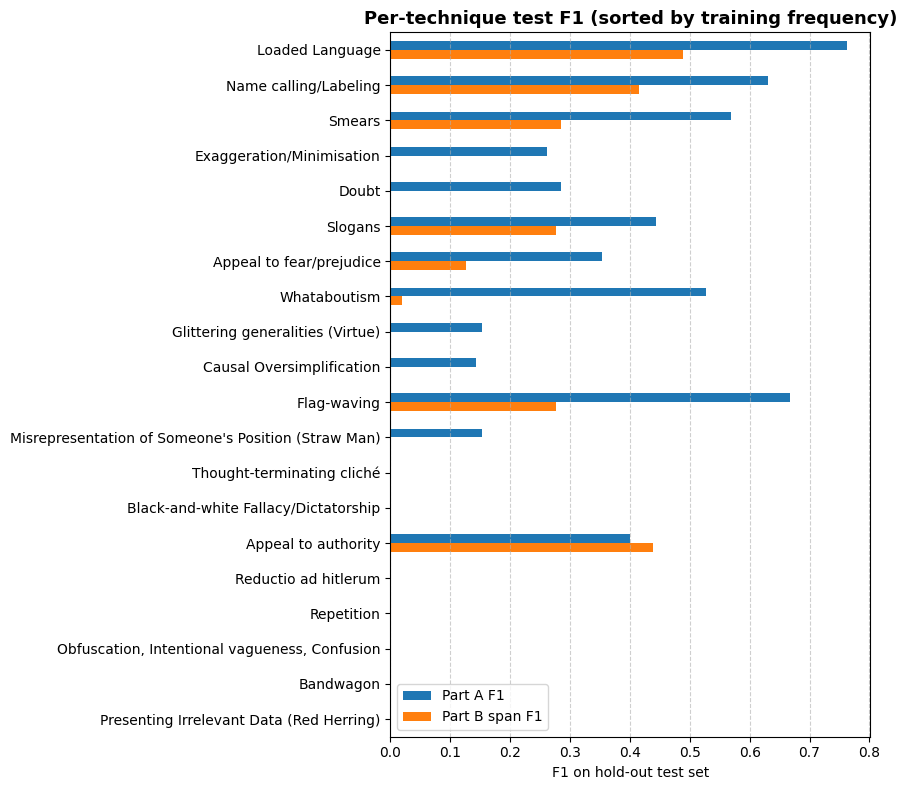

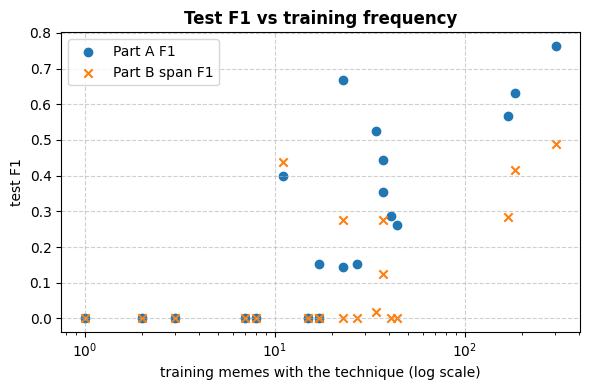

In [53]:
#[14] per-technique results on the test set (Part A vs Part B)

def span_f1_for(technique):
    return span_prf([[s for s in S if s[2] == technique] for S in test_res["span_preds"]],
                    [[g for g in G if g[2] == technique] for G in test_gold])["f1"]

per_tech = pd.DataFrame({
    "test memes": Y_TEST.sum(0).astype(int),
    "train+val memes": Y[idx_cv].sum(0).astype(int),
    "Part A F1": test_res["per_class_f1"],
    "Part B span F1": [span_f1_for(t) for t in TECHNIQUES],
    "predicted (Part A)": test_res["doc_preds"].sum(0).astype(int),
}, index=TECHNIQUES).sort_values("train+val memes", ascending=False)
display(per_tech.round(3))

ax = per_tech[["Part A F1", "Part B span F1"]].plot.barh(figsize=(9, 8))
ax.invert_yaxis()
ax.set_xlabel("F1 on the official test set")
ax.set_title("Per-technique test F1 (sorted by training frequency)", fontsize=13, fontweight="bold")
ax.grid(axis="x", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

#does performance follow training frequency?
plt.figure(figsize=(6, 4))
plt.scatter(per_tech["train+val memes"], per_tech["Part A F1"], label="Part A F1")
plt.scatter(per_tech["train+val memes"], per_tech["Part B span F1"], label="Part B span F1", marker="x")
plt.xscale("log")
plt.xlabel("training memes with the technique (log scale)")
plt.ylabel("test F1")
plt.title("Test F1 vs training frequency", fontsize=12, fontweight="bold")
plt.legend()
plt.grid(linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

### C3 preview: do the label head and the span head agree?

,either head,both,label only,span only,disagree rate
Loaded Language,78,55,22,1,0.295
Smears,71,45,13,13,0.366
Name calling/Labeling,61,33,26,2,0.459
Whataboutism,24,8,5,11,0.667
Exaggeration/Minimisation,15,1,14,0,0.933
Doubt,14,5,9,0,0.643
Appeal to fear/prejudice,12,2,9,1,0.833
Slogans,11,2,9,0,0.818
Causal Oversimplification,10,0,10,0,1.000
Misrepresentation of Someone's Position (Straw Man),10,0,10,0,1.000


Overall disagreement rate: 0.518


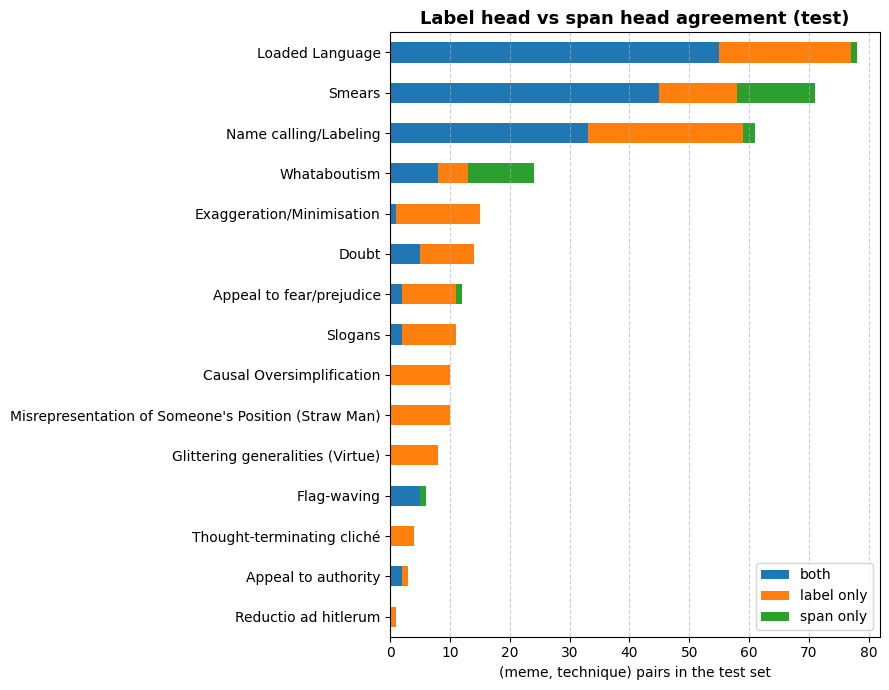

In [54]:
#[15] C3: label head vs span head agreement on the test set

label_on = test_res["doc_preds"].astype(bool)
span_on = np.zeros_like(label_on)
for d, S in enumerate(test_res["span_preds"]):
    for _, _, t in S:
        span_on[d, label2id[t]] = True
either = label_on | span_on

c3 = pd.DataFrame({
    "either head": either.sum(0),
    "both": (label_on & span_on).sum(0),
    "label only": (label_on & ~span_on).sum(0),
    "span only": (~label_on & span_on).sum(0),
}, index=TECHNIQUES)
c3["disagree rate"] = ((c3["label only"] + c3["span only"]) / c3["either head"].replace(0, np.nan)).round(3)
c3 = c3.sort_values("either head", ascending=False)
display(c3)

overall_disagree = (c3["label only"].sum() + c3["span only"].sum()) / max(c3["either head"].sum(), 1)
print(f"Overall disagreement rate: {overall_disagree:.3f}")

ax = c3[c3["either head"] > 0][["both", "label only", "span only"]].plot.barh(stacked=True, figsize=(9, 7))
ax.invert_yaxis()
ax.set_xlabel("(meme, technique) pairs in the test set")
ax.set_title("Label head vs span head agreement (test)", fontsize=13, fontweight="bold")
ax.grid(axis="x", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

## C1. Does it treat all sides the same?


1. **Australian swap test ([C1-a]–[C1-c]).** `dev_set_task2-swapped.txt` is the dev set with a fixed list of US and Canadian terms replaced by Australian ones. The list is in `dev_set_swaps.csv`. Each swap was applied case-sensitively (e.g. `TRUMP`, `Trump`), and the gold span offsets were recalculated so every technique span still covers the same words. In total there are 55 replacements in 36 of the 63 memes; the other 27 contain none of the terms and are unchanged. The political swaps cross sides: Trump → Albanese and Republicans → Labor (right → left), and Biden → Morrison and Joe → Scott (left → right). Of the 22 side-swapped memes, 13 go right → left, 7 left → right, and 2 contain both.

   To separate *"reacts to the side named"* from *"reacts to any name change"*, [C1-a] builds a **same-side control** for every side-swapped meme: Trump → Dutton, Republicans → Liberals, Biden → Albanese, Joe → Anthony. Every other edit is the same, so **the swap and the control differ only in the side named**. Comparing the control with the original shows what happens when the names become Australian but the side stays the same (evidence for C4).

   The other swaps are not about political side and are analysed separately:
   - titles and places: President → Prime Minister, STATES → TOWNS (2 memes);
   - a topic change: anti-vaxxer → climate denier (4 memes);
   - a same-side name: Trudeau → Wong, Canada → Australia (3 memes);
   - an ambiguous one: US *Democrat* → *Liberal* (2 memes). The Australian Liberal Party is on the right, but in US usage *liberal* means left.

   Three swaps change the technique itself: CONVICTED → GUILTY, AMERICAN → CHINESE, and Bill Gates → John Termus. These are excluded, which leaves 60 memes in the performance table.

   [C1-b] scores the original, swapped and control texts with the final 5-fold ensemble, using the thresholds from [13]. [C1-c] then measures how often the predicted label set changes, how often the highlighted techniques change, and the mean probability shift (|Δp|), each with bootstrap CIs. It also checks whether any technique moves consistently with the side named; shifts below 1 point are treated as negligible. With only 2–4 memes in each non-side group, those results are anecdotes rather than estimates. Because Albanese is the left-side name in both directions, a side effect cannot be fully separated from an effect of that one name.

In [56]:
#[C1-a] dev-set swap test: load the original and hand-swapped dev memes, group every meme by the kind of swap
#the dev set (63 memes) was never used for training, tuning or thresholds, so the final model can score it directly
#with no leakage. The swaps were made by hand (full list in dev_set_swaps.csv); gold labels are unchanged.
#the regular expressions below are used for analysis only and play no part in the model's decisions
import unicodedata

DEV_ORIG, DEV_SWAP = "dev_set_task2.txt", "dev_set_task2-swapped.txt"
dev_o = json.load(open(DEV_ORIG, encoding="utf-8"))
dev_s = json.load(open(DEV_SWAP, encoding="utf-8"))
assert [m["id"] for m in dev_o] == [m["id"] for m in dev_s], "the two dev files must list the same memes in the same order"

#each rule: original (case-sensitive, as applied), your swap, type, direction, CONTROL replacement
#  side    = US figure/party -> Australian figure/party on the OPPOSITE side; the control uses the SAME side instead
#  same    = same side already (Trudeau, Canadian centre-left -> Wong, Labor)
#  ambig   = US "Democrat" (left) -> "Liberal": the Australian Liberal Party is right, but in US usage liberal = left
#  setting = titles and places;  topic = anti-vaxxer -> climate denier (the rest of the meme is still about vaccines)
#  changes_technique = alters the words or meaning the gold labels rely on -> excluded from the comparison
#for every non-side rule the control uses your swap unchanged, so swap and control differ ONLY in the side named
SWAP_RULES = [
    # original        your swap            type                 dir     control (same side)
    ("Donald Trump",  "Althony Albanese",  "side",              "R->L", "Peter Dutton"),
    ("TRUMP",         "ALBANESE",          "side",              "R->L", "DUTTON"),
    ("Trump",         "Albanese",          "side",              "R->L", "Dutton"),
    ("Republicans",   "Labor",             "side",              "R->L", "Liberals"),
    ("JOE",           "SCOTT",             "side",              "L->R", "ANTHONY"),
    ("Joe",           "Scott",             "side",              "L->R", "Anthony"),
    ("BIDEN",         "MORRISON",          "side",              "L->R", "ALBANESE"),
    ("Biden",         "Morrison",          "side",              "L->R", "Albanese"),
    ("trudeau",       "Wong",              "same",              "",     "Wong"),
    ("TRUDEAU",       "WONG",              "same",              "",     "WONG"),
    ("TRUD",          "WONG",              "same",              "",     "WONG"),
    ("Democrat",      "Liberal",           "ambig",             "",     "Liberal"),
    ("democrat",      "liberal",           "ambig",             "",     "liberal"),
    ("President",     "Prime Minister",    "setting",           "",     "Prime Minister"),
    ("president",     "prime minister",    "setting",           "",     "prime minister"),
    ("CANADA",        "AUSTRALIA",         "setting",           "",     "AUSTRALIA"),
    ("Canadian",      "Australian",        "setting",           "",     "Australian"),
    ("STATES",        "TOWNS",             "setting",           "",     "TOWNS"),
    ("ANTI-VAXXERS",  "CLIMATE DENIER",    "topic",             "",     "CLIMATE DENIER"),
    ("ANTIVAXXER",    "CLIMATE DENIER",    "topic",             "",     "CLIMATE DENIER"),
    ("Anti-Vaxers",   "Climate Denier",    "topic",             "",     "Climate Denier"),
    ("BILL GATES",    "JOHN TERMUS",       "changes_technique", "",     "JOHN TERMUS"),
    ("CONVICTED",     "GUILTY",            "changes_technique", "",     "GUILTY"),
    ("AMERICAN",      "CHINESE",           "changes_technique", "",     "CHINESE"),
]
RULE = {r[0]: r for r in SWAP_RULES}
RULE_RE = re.compile("|".join(re.escape(r[0]) for r in sorted(SWAP_RULES, key=lambda r: -len(r[0]))))

#sanity check: re-applying your swaps to the original text must reproduce your swapped file exactly
rebuilt = [RULE_RE.sub(lambda m: RULE[m.group(0)][1], m["text"]) for m in dev_o]
diffs = [(o["id"], r, s["text"]) for o, s, r in zip(dev_o, dev_s, rebuilt) if r != s["text"]]
if diffs:
    for i, r, s in diffs[:10]:
        print(i, "\n  rule table:", r[:120].replace("\n", " / "), "\n  your file: ", s[:120].replace("\n", " / "))
    raise AssertionError(f"{len(diffs)} memes in {DEV_SWAP} do not match the rule table: use the generated "
                         f"dev_set_task2-swapped.txt (55 replacements in 36 memes) or edit SWAP_RULES to match your file")

dev_ids = [m["id"] for m in dev_o]
dev_texts = {"orig": [m["text"] for m in dev_o],
             "swap": [m["text"] for m in dev_s],
             "ctrl": [RULE_RE.sub(lambda m: RULE[m.group(0)][4], m["text"]) for m in dev_o]}
dev_hits = [RULE_RE.findall(t) for t in dev_texts["orig"]]


def swap_group(hits):
    types = {RULE[h][2] for h in hits}
    if not hits:                        return "unchanged"
    if "changes_technique" in types:    return "excluded (changes technique)"
    if "side" in types:                 return "side swap"
    if "ambig" in types:                return "ambiguous (Democrat → Liberal)"
    if "same" in types:                 return "same-side name"
    if "setting" in types:              return "Australian setting"
    return "topic change"


dev_group = np.array([swap_group(h) for h in dev_hits])
dev_dir = np.array(["/".join(sorted({RULE[h][3] for h in hits if RULE[h][2] == "side"})) for hits in dev_hits])
dev_mixed = np.array([len({RULE[h][2] for h in hits}) > 1 for hits in dev_hits])   #e.g. President + Trump in one meme

print(pd.Series(dev_group).value_counts().to_string())
print(f"\nside swaps by direction: {pd.Series(dev_dir[dev_group == 'side swap']).value_counts().to_dict()}  "
      f"(R->L = a meme about the right now names the left)")
changed = [i for i in range(len(dev_ids)) if dev_hits[i]]
display(pd.DataFrame({
    "id": [dev_ids[i] for i in changed], "group": dev_group[changed], "direction": dev_dir[changed],
    "swaps": [", ".join(f"{h} → {RULE[h][1]}" for h in dict.fromkeys(dev_hits[i])) for i in changed],
    "your swap": [dev_texts["swap"][i][:70].replace("\n", " / ") for i in changed],
    "control (same side)": [dev_texts["ctrl"][i][:70].replace("\n", " / ") if dev_group[i] == "side swap" else ""
                            for i in changed]}).set_index("id"))


def boot_ci(x, n_boot=5000, seed=SEED):
    '''95% percentile bootstrap CI of the mean (memes resampled with replacement).'''
    x = np.asarray(x, dtype=float)
    x = x[~np.isnan(x)]
    if len(x) == 0:
        return np.nan, np.nan
    rng = np.random.default_rng(seed)
    means = x[rng.integers(0, len(x), size=(n_boot, len(x)))].mean(axis=1)
    return float(np.percentile(means, 2.5)), float(np.percentile(means, 97.5))

unchanged                         27
side swap                         22
topic change                       4
same-side name                     3
excluded (changes technique)       3
Australian setting                 2
ambiguous (Democrat → Liberal)     2

side swaps by direction: {'R->L': 13, 'L->R': 7, 'L->R/R->L': 2}  (R->L = a meme about the right now names the left)


,group,direction,swaps,your swap,control (same side)
id,,,,,
62_batch_2,side swap,L->R,"President → Prime Minister, Biden → Morrison","*Prime Minister* Morrison? / / Please, no. /","*Prime Minister* Albanese? / / Please, no. /"
111_batch_2,side swap,L->R,JOE → SCOTT,"SCOTT VERSUS THE VOLCANIC KREMLIN DON / / ""W...",ANTHONY VERSUS THE VOLCANIC KREMLIN DON / / ...
167_batch_2,topic change,,ANTI-VAXXERS → CLIMATE DENIER,CLIMATE DENIER BE LIKE... / / HANG ON A SEC ...,
153_batch_2,topic change,,ANTIVAXXER → CLIMATE DENIER,Never thought l'd die fighting IRRESPONSIBLY R...,
173_batch_2,topic change,,Anti-Vaxers → Climate Denier,"Climate Denier keep saying dumb things, like ""...",
9_batch_2,same-side name,,TRUDEAU → WONG,"Definition Of Stupid: / / Knowing The Truth, ...",
76_batch_2,side swap,R->L,TRUMP → ALBANESE,AFTER FIRST DEBATE WITH ALBANESE /,AFTER FIRST DEBATE WITH DUTTON /
172_batch_2,excluded (changes technique),,BILL GATES → JOHN TERMUS,JOHN TERMUS HAS A SECRET EUGENICS PLAN TO DEPO...,
133_batch_2,excluded (changes technique),,CONVICTED → GUILTY,"""LAW AND ORDER"" / / PLEADED GUILTY / / GUILT...",


In [57]:
#[C1-b] score the original, swapped and control dev memes with the final 5-fold ensemble (same as [13])
#bonus: the original dev set is a second, fully unseen evaluation of the final model

def predict_texts(model, texts, batch_size=32):
    '''Doc probabilities (N, C), plus token probabilities and character offsets per text. No labels needed.'''
    ds = TwoHeadDataset(texts, [[] for _ in texts], np.zeros((len(texts), NUM_CLASSES), dtype=np.float32), tokenizer)
    loader = DataLoader(ds, batch_size=batch_size, shuffle=False)
    model.eval()
    doc, tok, offs = [], [], []
    with torch.inference_mode():
        for batch in loader:
            out = model(input_ids=batch["input_ids"].to(device), attention_mask=batch["attention_mask"].to(device))
            doc.append(torch.sigmoid(out["doc_logits"]).float().cpu().numpy())
            tp = torch.sigmoid(out["tok_logits"]).float().cpu().numpy()
            for i in range(len(batch["input_ids"])):
                real = (batch["tok_labels"][i, :, 0] != -100).numpy()
                tok.append(tp[i][real])
                offs.append(batch["offsets"][i].numpy()[real])
    return np.concatenate(doc), tok, offs


DP = {v: np.zeros((len(dev_ids), NUM_CLASSES), dtype=np.float32) for v in dev_texts}   #ensemble probabilities
dev_tok, dev_off = {v: None for v in dev_texts}, {}
for state in final_res["fold_states"]:
    model = load_fold_model(state)                         #from [13]
    for v, texts in dev_texts.items():
        d, t, o = predict_texts(model, texts)
        DP[v] += d / K_FOLDS
        dev_tok[v] = [x / K_FOLDS for x in t] if dev_tok[v] is None else [a + x / K_FOLDS for a, x in zip(dev_tok[v], t)]
        dev_off[v] = o
    del model
    torch.cuda.empty_cache()
    gc.collect()

DLAB = {v: DP[v] >= ens_thr for v in dev_texts}                                     #ensemble thresholds from [13]
DSPANS = {v: [decode_spans(t, o, ens_tok_thr) for t, o in zip(dev_tok[v], dev_off[v])] for v in dev_texts}
DSPN = {v: np.array([[any(s[2] == t for s in S) for t in TECHNIQUES] for S in DSPANS[v]]) for v in dev_texts}

#gold labels (unchanged by the swaps) and gold spans (offsets recomputed for the swapped file)
dev_Y = np.array([[1.0 if t in {l["technique"] for l in m["labels"]} else 0.0 for t in TECHNIQUES] for m in dev_o],
                 dtype=np.float32)
dev_gold = {"orig": [[(l["start"], l["end"], l["technique"]) for l in m["labels"]] for m in dev_o],
            "swap": [[(l["start"], l["end"], l["technique"]) for l in m["labels"]] for m in dev_s]}

#unseen-data performance: original dev vs swapped dev (memes whose swap changes the technique are left out)
keep = dev_group != "excluded (changes technique)"
rows = {}
for v in ["orig", "swap"]:
    macro, micro, exact, acc, _ = f1_stats(dev_Y[keep], DLAB[v][keep].astype(np.float32))
    sp = span_prf([DSPANS[v][i] for i in np.where(keep)[0]], [dev_gold[v][i] for i in np.where(keep)[0]])
    rows["original dev" if v == "orig" else "swapped dev"] = {"memes": int(keep.sum()), "Micro-F1": micro,
                                                             "Macro-F1": macro, "Span-F1": sp["f1"]}
dev_perf = pd.DataFrame(rows).T
print("Unseen dev set, 5-fold ensemble (compare with the hold-out test results in [13]):")
display(dev_perf.round(3))

Unseen dev set, 5-fold ensemble (compare with the hold-out test results in [13]):


,memes,Micro-F1,Macro-F1,Span-F1
original dev,60.0,0.524,0.246,0.427
swapped dev,60.0,0.548,0.259,0.435


,memes,label set changes,95% CI,highlighted techniques change,mean |Δp|
comparison,,,,,
side only (your swap vs same-side control),22,0.273,0.09–0.45,0.318,0.018
"Australianised, same side (control vs original)",22,0.545,0.32–0.73,0.182,0.029
same-side name change,3,0.333,0.00–1.00,0.333,0.036
Democrat → Liberal,2,0.000,0.00–0.00,0.000,0.005
titles and places,2,1.000,1.00–1.00,0.000,0.023
anti-vaxxer → climate denier,4,0.250,0.00–0.75,0.500,0.013


,group,direction,compared,techniques added,techniques removed,largest shift
id,,,,,,
62_batch_2,side swap,L->R,swap vs ctrl,—,—,Smears +0.03
111_batch_2,side swap,L->R,swap vs ctrl,—,—,Exaggeration/Minimisation +0.03
167_batch_2,topic change,,swap vs orig,—,—,Loaded Language -0.23
153_batch_2,topic change,,swap vs orig,—,Whataboutism,Exaggeration/Minimisation +0.04
173_batch_2,topic change,,swap vs orig,—,—,Smears +0.05
9_batch_2,same-side name,,swap vs orig,—,—,Slogans +0.08
76_batch_2,side swap,R->L,swap vs ctrl,—,"Exaggeration/Minimisation, Smears",Exaggeration/Minimisation -0.30
172_batch_2,excluded (changes technique),,swap vs orig,—,Whataboutism,Smears -0.10
133_batch_2,excluded (changes technique),,swap vs orig,—,—,Smears -0.12


direction,L->R,R->L
technique,,
Appeal to fear/prejudice,0.002,-0.001
Doubt,0.002,-0.013
Exaggeration/Minimisation,-0.010,-0.023
Flag-waving,0.007,0.010
Loaded Language,0.011,-0.031
Name calling/Labeling,-0.034,-0.007
Slogans,-0.001,-0.005
Smears,0.018,-0.052


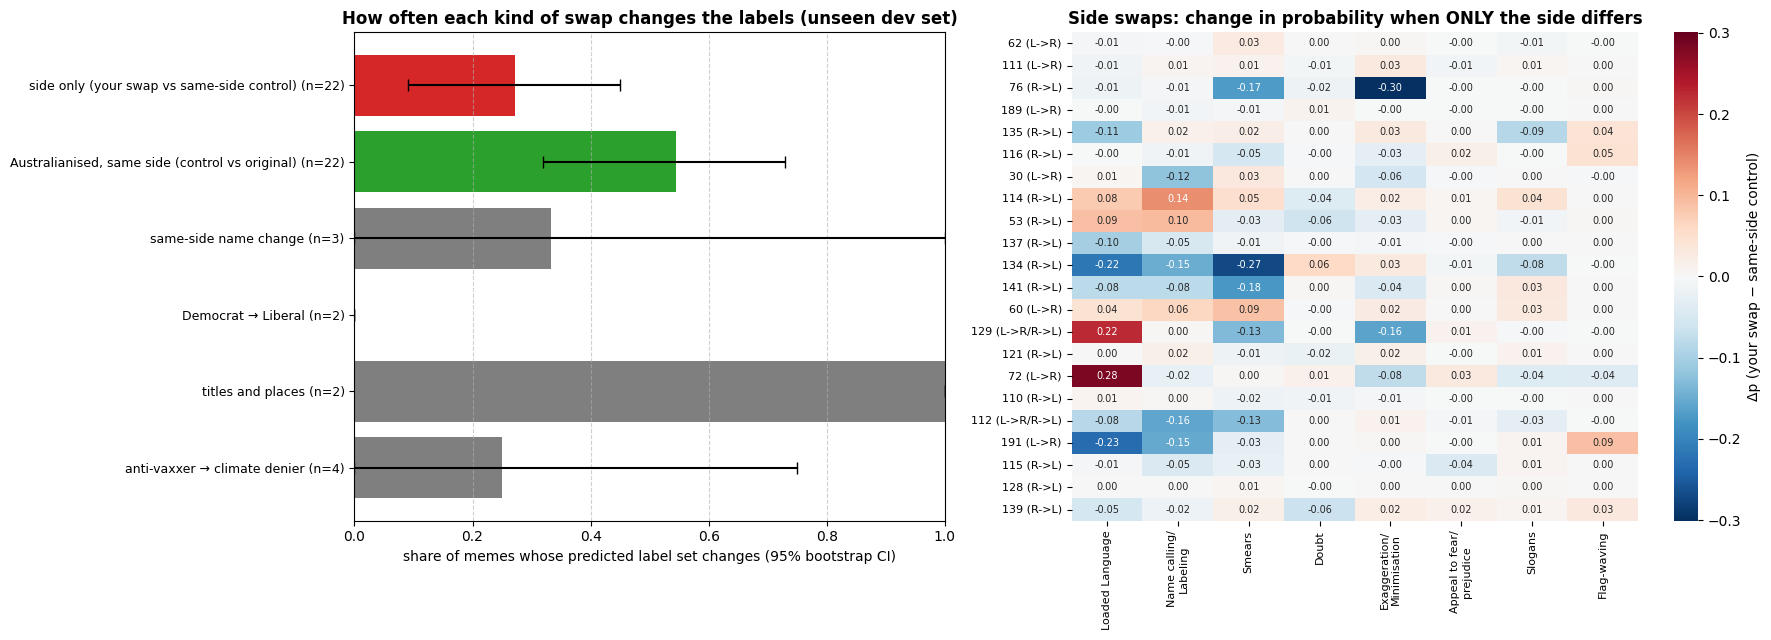

Summary for the C1 conclusion
- side only (your swap vs same-side control): label set changed for 27% of 22 memes (95% CI 0.09–0.45)
- Australianised, same side (control vs original): label set changed for 55% of 22 memes (95% CI 0.32–0.73)
- same-side name change: label set changed for 33% of 3 memes (95% CI 0.00–1.00)
- Democrat → Liberal: label set changed for 0% of 2 memes (95% CI 0.00–0.00)
- titles and places: label set changed for 100% of 2 memes (95% CI 1.00–1.00)
- anti-vaxxer → climate denier: label set changed for 25% of 4 memes (95% CI 0.00–0.75)
- techniques whose probability moves consistently with the side named: ['Smears (R->L, -0.05)', 'Flag-waving (R->L, +0.01)']
- unseen dev Micro-F1: original 0.524 vs swapped 0.548


In [58]:
#[C1-c] what do the swaps do to the output?
#side swaps:  swap vs control  = ONLY the side changed (pure side effect)
#             control vs orig  = Australianised, side unchanged
#other groups: swap vs orig    = the effect of that kind of edit

MIN_EFFECT = 0.01      #probability shifts below 1 point are treated as negligible
label_change = lambda a, b: (DLAB[a] != DLAB[b]).any(axis=1).astype(float)
span_change = lambda a, b: (DSPN[a] != DSPN[b]).any(axis=1).astype(float)
mean_abs_dp = lambda a, b: np.abs(DP[a] - DP[b]).mean(axis=1)

comparisons = [("side swap", "swap", "ctrl", "side only (your swap vs same-side control)"),
               ("side swap", "ctrl", "orig", "Australianised, same side (control vs original)"),
               ("same-side name", "swap", "orig", "same-side name change"),
               ("ambiguous (Democrat → Liberal)", "swap", "orig", "Democrat → Liberal"),
               ("Australian setting", "swap", "orig", "titles and places"),
               ("topic change", "swap", "orig", "anti-vaxxer → climate denier")]
rows = []
for g, a, b, name in comparisons:
    m = dev_group == g
    if m.sum() == 0:
        continue
    lc, sc, dp = label_change(a, b)[m], span_change(a, b)[m], mean_abs_dp(a, b)[m]
    rows.append({"comparison": name, "memes": int(m.sum()), "label set changes": lc.mean(),
                 "95% CI": "%.2f–%.2f" % boot_ci(lc), "highlighted techniques change": sc.mean(),
                 "mean |Δp|": dp.mean()})
dev_cmp = pd.DataFrame(rows).set_index("comparison")
display(dev_cmp.round(3))

# ---------- per-meme detail: what was added / removed ----------
def diff_labels(i, a, b):
    add = [TECHNIQUES[k] for k in np.where(DLAB[a][i] & ~DLAB[b][i])[0]]
    rem = [TECHNIQUES[k] for k in np.where(~DLAB[a][i] & DLAB[b][i])[0]]
    return ", ".join(add) or "—", ", ".join(rem) or "—"

detail = []
for i in np.where(dev_group != "unchanged")[0]:
    a, b = ("swap", "ctrl") if dev_group[i] == "side swap" else ("swap", "orig")
    add, rem = diff_labels(i, a, b)
    k = int(np.argmax(np.abs(DP[a][i] - DP[b][i])))
    detail.append({"id": dev_ids[i], "group": dev_group[i], "direction": dev_dir[i], "compared": f"{a} vs {b}",
                   "techniques added": add, "techniques removed": rem,
                   "largest shift": f"{TECHNIQUES[k]} {DP[a][i, k] - DP[b][i, k]:+.2f}"})
display(pd.DataFrame(detail).set_index("id"))

# ---------- direction within the side swaps ----------
dP_side = DP["swap"] - DP["ctrl"]
TOP_T = ["Loaded Language", "Name calling/Labeling", "Smears", "Doubt", "Exaggeration/Minimisation",
         "Appeal to fear/prejudice", "Slogans", "Flag-waving"]
dir_rows = []
for d in ["R->L", "L->R"]:
    m = (dev_group == "side swap") & (dev_dir == d)
    for t in TOP_T:
        k = label2id[t]
        lo, hi = boot_ci(dP_side[m, k])
        dir_rows.append({"direction": d, "technique": t, "memes": int(m.sum()),
                         "mean Δp (swap − control)": dP_side[m, k].mean() if m.any() else np.nan, "lo": lo, "hi": hi})
dir_df = pd.DataFrame(dir_rows)
display(dir_df.pivot(index="technique", columns="direction", values="mean Δp (swap − control)").round(3))

# ---------- figures ----------
fig, axes = plt.subplots(1, 2, figsize=(18, 6.5), gridspec_kw={"width_ratios": [1, 1.2]})
order = dev_cmp.index.tolist()
vals = dev_cmp["label set changes"].values
errs = np.array([[v - float(c.split("–")[0]), float(c.split("–")[1]) - v] for v, c in zip(vals, dev_cmp["95% CI"])]).T
cols = ["#d62728", "#2ca02c"] + ["#7f7f7f"] * (len(order) - 2)
axes[0].barh(np.arange(len(order)), vals, xerr=errs, capsize=4, color=cols[:len(order)])
axes[0].set_yticks(np.arange(len(order)))
axes[0].set_yticklabels([f"{o} (n={n})" for o, n in zip(order, dev_cmp["memes"])], fontsize=9)
axes[0].invert_yaxis()
axes[0].set_xlim(0, 1)
axes[0].set_xlabel("share of memes whose predicted label set changes (95% bootstrap CI)")
axes[0].set_title("How often each kind of swap changes the labels (unseen dev set)", fontsize=12, fontweight="bold")
axes[0].grid(axis="x", linestyle="--", alpha=0.6)

#heatmap: probability shift per side-swapped meme (swap − control), most common techniques
side_idx = np.where(dev_group == "side swap")[0]
if len(side_idx):
    hm = pd.DataFrame(dP_side[side_idx][:, [label2id[t] for t in TOP_T]],
                      index=[f"{dev_ids[i].replace('_batch_2', '')} ({dev_dir[i]})" for i in side_idx],
                      columns=[t.replace("/", "/\n") for t in TOP_T])
    lim = max(0.05, float(np.abs(hm.values).max()))
    sns.heatmap(hm, ax=axes[1], cmap="RdBu_r", center=0, vmin=-lim, vmax=lim, annot=True, fmt=".2f",
                annot_kws={"fontsize": 7}, cbar_kws={"label": "Δp (swap − same-side control)"})
    axes[1].set_title("Side swaps: change in probability when ONLY the side differs", fontsize=12, fontweight="bold")
    axes[1].tick_params(axis="x", labelsize=8)
    axes[1].tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.show()

print("Summary for the C1 conclusion")
for name, r in dev_cmp.iterrows():
    print(f"- {name}: label set changed for {r['label set changes']:.0%} of {r['memes']} memes (95% CI {r['95% CI']})")
big = dir_df[(dir_df["mean Δp (swap − control)"].abs() >= MIN_EFFECT) & ((dir_df["lo"] > 0) | (dir_df["hi"] < 0))]
print("- techniques whose probability moves consistently with the side named:",
      [f"{r.technique} ({r.direction}, {r['mean Δp (swap − control)']:+.2f})" for _, r in big.iterrows()] or "none")
print(f"- unseen dev Micro-F1: original {dev_perf.loc['original dev', 'Micro-F1']:.3f} vs swapped "
      f"{dev_perf.loc['swapped dev', 'Micro-F1']:.3f}")

* The change of name matters more than the change of side. Swapping a US figure for a same-side Australian one changed the labels twice as often as switching the side. The model is reacting to unfamiliar names more than to politics. The two CIs overlap, so this is suggestive rather than proven.
* “Label set changed” overstates the effect. Average probability shifts are only about 2–3 points. Labels flip because many memes sit near the 0.27 threshold. Mean |Δp| is the better measure of size.
Heatmap (swap minus control):

Most cells are close to 0.
A few memes move a lot:
meme 76: Exaggeration −0.30, Smears −0.17;
meme 134: Smears −0.27, Loaded Language −0.22;
meme 72: Loaded Language +0.28;
meme 191: Loaded Language −0.23.
Loaded Language goes up in some left → right memes and down in others (72 vs 191). That is why its average is near zero: the shifts are erratic rather than biased.

Direction table: the one consistent shift is Smears in the right → left swaps, at −0.05.

When a Trump meme names Albanese instead of Dutton, Smears drops 5 points on average.
In the left → right swaps (Morrison instead of Albanese) Smears rises 0.018. That is the same direction but not significant.
Caveat: Albanese is the left-side name in both directions, so this could be about Albanese the person rather than the left. With one name per side the two can’t be separated.
Flag-waving at +0.01 is exactly at the 1-point floor (MIN_EFFECT), so ignore it.

Small groups: treat these as anecdotes.

The CIs of “1.00–1.00” and “0.00–0.00” don’t mean certainty. With 2 memes the bootstrap has almost nothing to resample.
Titles and places (2 memes):
meme 106 lost Slogans after President → Prime Minister;
meme 34 lost Doubt and Exaggeration after STATES → TOWNS.
Democrat → Liberal: essentially no effect (|Δp| 0.005), so the left/right ambiguity of “Liberal” didn’t matter here.
Same-side, meme 43 (Trudeau → Wong): Smears −0.47, the largest single shift in the whole test, from a swap that didn’t change side. That points to names, not side, again.
Topic, meme 153: lost Whataboutism.

(a) Share of memes the annotators labelled with each technique, by the side the meme names (training + dev)


,names left only,names right only,names both,names neither
Loaded Language,0.49,0.60,0.39,0.52
Name calling/Labeling,0.37,0.38,0.36,0.31
Smears,0.57,0.39,0.50,0.19
Doubt,0.04,0.08,0.06,0.08
Exaggeration/Minimisation,0.07,0.12,0.11,0.07
Appeal to fear/prejudice,0.06,0.06,0.03,0.07
Whataboutism,0.04,0.06,0.08,0.06
Slogans,0.06,0.12,0.11,0.05
memes in group,122.00,77.00,36.00,516.00



(b) Model errors on the unseen dev memes, by side named (few memes per cell: read as descriptive only)


,technique,group,memes,with technique,recall,false-positive rate,gold rate,predicted rate
0,Loaded Language,names left only,10,3,1.00,0.29,0.30,0.50
1,Loaded Language,names right only,13,9,1.00,0.50,0.69,0.85
2,Name calling/Labeling,names left only,10,5,0.80,0.40,0.50,0.60
3,Name calling/Labeling,names right only,13,7,0.86,0.33,0.54,0.62
4,Smears,names left only,10,5,0.60,0.40,0.50,0.50
5,Smears,names right only,13,8,0.88,0.60,0.62,0.77


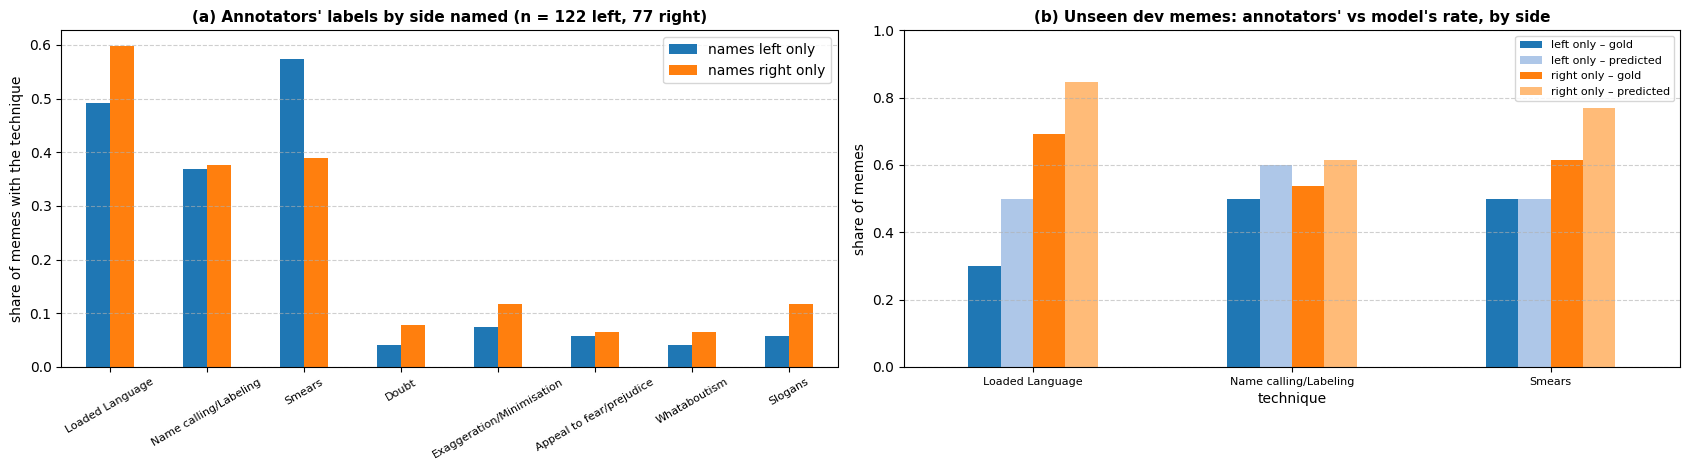

In [60]:
#[C1-d] corpus audit + model errors by the side a meme names (original text, gold labels)
#(a) audit: do the annotators' labels pair techniques with one side? Uses gold labels only (training + dev, 751 memes);
#    a skew here is something any model trained on this data will learn.
#(b) errors: on the unseen dev memes, does the model miss more / raise more false alarms on one side? (small n)
#caveat: "names the left" is a proxy for "is about the left"; a meme can name a side to praise or attack it

def _term_regex(terms):
    keys = sorted({t.lower() for t in terms}, key=len, reverse=True)
    return re.compile(r"(?<![A-Za-z])(" + "|".join(re.escape(k).replace(r"\ ", r"\s+") for k in keys) + r")(?![A-Za-z])",
                      re.IGNORECASE)

LEFT_TERMS = ["Biden", "Joe Biden", "Democrat", "Democrats", "Democratic", "Dems", "Obama", "Hillary", "Clinton", "Kamala",
              "Harris", "Pelosi", "Bernie", "Sanders", "liberal", "liberals", "leftist", "leftists", "progressive",
              "progressives", "CNN", "Trudeau", "Trud", "Antifa"]
RIGHT_TERMS = ["Trump", "Donald Trump", "Republican", "Republicans", "GOP", "Pence", "McConnell", "Cruz", "conservative",
               "conservatives", "Fox", "MAGA"]
left_re, right_re = _term_regex(LEFT_TERMS), _term_regex(RIGHT_TERMS)

def side_of(texts):
    nl = np.array([len(left_re.findall(t)) for t in texts])
    nr = np.array([len(right_re.findall(t)) for t in texts])
    return np.select([(nl > 0) & (nr == 0), (nr > 0) & (nl == 0), (nl > 0) & (nr > 0)],
                     ["names left only", "names right only", "names both"], default="names neither")

AUDIT_T = ["Loaded Language", "Name calling/Labeling", "Smears", "Doubt", "Exaggeration/Minimisation",
           "Appeal to fear/prejudice", "Whataboutism", "Slogans"]
GROUPS = ["names left only", "names right only", "names both", "names neither"]

# ---------- (a) corpus audit on gold labels: training + dev ----------
audit_texts = df2["text"].tolist()
audit_Y = Y
audit_side = side_of(audit_texts)
audit = pd.DataFrame({g: [audit_Y[audit_side == g, label2id[t]].mean() for t in AUDIT_T] for g in GROUPS}, index=AUDIT_T)
audit.loc["memes in group"] = [int((audit_side == g).sum()) for g in GROUPS]
print("(a) Share of memes the annotators labelled with each technique, by the side the meme names (training + dev)")
display(audit.round(2))

# ---------- (b) model errors on the unseen dev memes, by side ----------
dev_side = side_of(dev_texts["orig"])
err_rows = []
for t in ["Loaded Language", "Name calling/Labeling", "Smears"]:
    k = label2id[t]
    for g in ["names left only", "names right only"]:
        m = dev_side == g
        y, p = dev_Y[m, k].astype(bool), DLAB["orig"][m, k]
        err_rows.append({"technique": t, "group": g, "memes": int(m.sum()), "with technique": int(y.sum()),
                         "recall": p[y].mean() if y.any() else np.nan,
                         "false-positive rate": p[~y].mean() if (~y).any() else np.nan,
                         "gold rate": y.mean() if m.any() else np.nan, "predicted rate": p.mean() if m.any() else np.nan})
dev_err = pd.DataFrame(err_rows)
print("\n(b) Model errors on the unseen dev memes, by side named (few memes per cell: read as descriptive only)")
display(dev_err.round(2))

# ---------- figure ----------
fig, axes = plt.subplots(1, 2, figsize=(17, 4.8))
audit.drop("memes in group")[["names left only", "names right only"]].plot.bar(ax=axes[0], rot=30, color=["#1f77b4", "#ff7f0e"])
axes[0].set_title(f"(a) Annotators' labels by side named (n = {int((audit_side == 'names left only').sum())} left, "
                  f"{int((audit_side == 'names right only').sum())} right)", fontsize=11, fontweight="bold")
axes[0].set_ylabel("share of memes with the technique")
axes[0].tick_params(axis="x", labelsize=8)
axes[0].grid(axis="y", linestyle="--", alpha=0.6)
plot_df = dev_err.melt(id_vars=["technique", "group"], value_vars=["gold rate", "predicted rate"])
plot_df["bar"] = plot_df["group"].str.replace("names ", "") + " – " + plot_df["variable"].str.replace(" rate", "")
plot_df.pivot(index="technique", columns="bar", values="value").plot.bar(
    ax=axes[1], rot=0, color=["#1f77b4", "#aec7e8", "#ff7f0e", "#ffbb78"])
axes[1].set_title("(b) Unseen dev memes: annotators' vs model's rate, by side", fontsize=11, fontweight="bold")
axes[1].set_ylabel("share of memes")
axes[1].set_ylim(0, 1)
axes[1].tick_params(axis="x", labelsize=8)
axes[1].legend(fontsize=8)
axes[1].grid(axis="y", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

n  attribution_share  token_share  \
Smears                US original      17.0              0.119        0.084   
                      Australian swap  17.0              0.132        0.121   
Name calling/Labeling US original      15.0              0.103        0.085   
                      Australian swap  15.0              0.132        0.108   
Loaded Language       US original      18.0              0.093        0.076   
                      Australian swap  18.0              0.163        0.122   
Doubt                 US original       NaN                NaN          NaN   
                      Australian swap   NaN                NaN          NaN   

                                       ratio ratio 95% CI  
Smears                US original      1.507    1.24–1.80  
                      Australian swap  1.088    0.92–1.26  
Name calling/Labeling US original      1.369    1.11–1.69  
                      Australian swap  1.124    0.87–1.41  
Loaded Language       US original      1.371    1.02–1.80  
                      Australian swap  1.291    1.01–1.62  
Doubt                 US original        NaN      nan–nan  
                      Australian swap    NaN      nan–nan

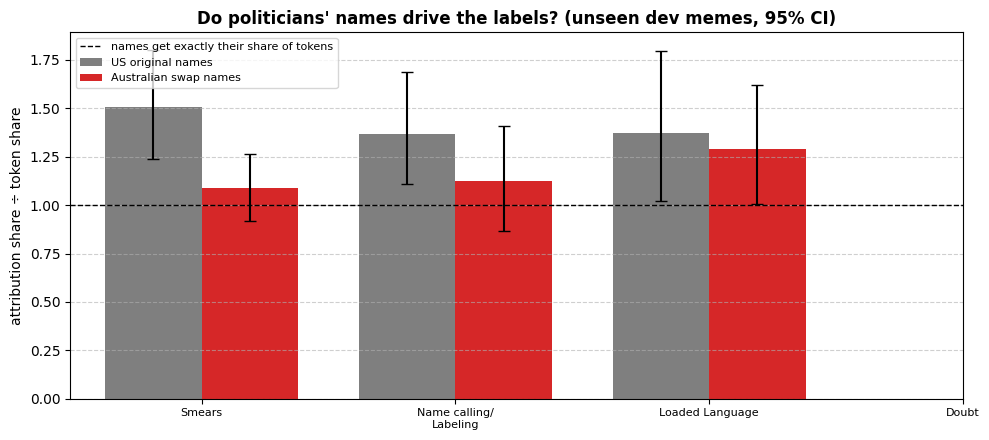

In [61]:
#[C1-e] attribution: do the political NAMES drive the labels? gradient × input, averaged over the 5 fold models
#for each dev meme that names a politician or party and each technique the ensemble predicts, measure the share of
#attribution on the name tokens versus the share of tokens they take up: ratio ≈ 1 means names get their fair share,
#ratio >> 1 means the label is driven by WHO is named. Compared on the original (US) and your swapped (Australian) text.
import html as _html
from IPython.display import HTML

ATTR_T = ["Smears", "Name calling/Labeling", "Loaded Language", "Doubt"]
#names in either version: the US/Canadian terms from [C1-d] plus every Australian replacement from [C1-a]
NAME_RE = _term_regex(LEFT_TERMS + RIGHT_TERMS + [r[1] for r in SWAP_RULES if r[2] in ("side", "same", "ambig")])


def token_attributions(model, text, tech_ids):
    '''|gradient × input| per token for each technique logit of the label head. Returns ({k: attr}, offsets).'''
    enc = tokenizer(text, truncation=True, max_length=MAX_LENGTH, return_offsets_mapping=True, return_tensors="pt")
    store = {}

    def hook(module, inp, out):                    #make the embedding output a leaf we can take gradients of
        out = out.detach().requires_grad_(True)
        store["emb"] = out
        return out

    handle = model.roberta.get_input_embeddings().register_forward_hook(hook)
    try:
        with torch.enable_grad():
            out = model(input_ids=enc["input_ids"].to(device), attention_mask=enc["attention_mask"].to(device))
            attrs = {}
            for k in tech_ids:
                g, = torch.autograd.grad(out["doc_logits"][0, k], store["emb"], retain_graph=True)
                attrs[k] = (g * store["emb"]).sum(-1)[0].abs().detach().float().cpu().numpy()
    finally:
        handle.remove()
    return attrs, enc["offset_mapping"][0].numpy()


def name_mask(text, offs):
    spans = [(m.start(), m.end()) for m in NAME_RE.finditer(text)]
    return np.array([e > s and any(s < b and e > a for a, b in spans) for s, e in offs])


#memes to explain: name a politician/party in BOTH versions, and the technique is predicted on the original
targets = [i for i in range(len(dev_ids))
           if NAME_RE.search(dev_texts["orig"][i]) and NAME_RE.search(dev_texts["swap"][i])
           and dev_group[i] != "excluded (changes technique)"]
tech_ids = [label2id[t] for t in ATTR_T]
attr_sum = {v: {} for v in ["orig", "swap"]}             #(meme, technique) -> summed attribution over folds
offs_of = {}
for state in final_res["fold_states"]:
    model = load_fold_model(state)
    model.eval()
    for i in targets:
        on = [k for k in tech_ids if DLAB["orig"][i, k]]
        if not on:
            continue
        for v in ["orig", "swap"]:
            attrs, offs = token_attributions(model, dev_texts[v][i], on)
            offs_of[(v, i)] = offs
            for k, a in attrs.items():
                attr_sum[v][(i, k)] = attr_sum[v].get((i, k), 0) + a / K_FOLDS
    del model
    torch.cuda.empty_cache()
    gc.collect()

rows = []
for v in ["orig", "swap"]:
    for (i, k), a in attr_sum[v].items():
        offs = offs_of[(v, i)]
        real, ent = offs[:, 1] > offs[:, 0], name_mask(dev_texts[v][i], offs)
        if not ent.any() or a[real].sum() <= 0:
            continue
        share, tok_share = a[ent].sum() / a[real].sum(), ent.sum() / real.sum()
        rows.append({"version": "US original" if v == "orig" else "Australian swap", "meme": dev_ids[i],
                     "technique": TECHNIQUES[k], "attribution share on names": share,
                     "token share of names": tok_share, "ratio": share / tok_share})
attr_df = pd.DataFrame(rows)
attr_summary = (attr_df.groupby(["technique", "version"])
                .agg(n=("ratio", "size"), attribution_share=("attribution share on names", "mean"),
                     token_share=("token share of names", "mean"), ratio=("ratio", "mean"))
                .reindex(pd.MultiIndex.from_product([ATTR_T, ["US original", "Australian swap"]])))
attr_summary["ratio 95% CI"] = [("%.2f–%.2f" % boot_ci(attr_df[(attr_df.technique == t) & (attr_df.version == v)]["ratio"]))
                                for t, v in attr_summary.index]
display(attr_summary.round(3))

#figure: ratio per technique, US names vs Australian names
fig, ax = plt.subplots(figsize=(10, 4.5))
x, w = np.arange(len(ATTR_T)), 0.38
for j, (v, colr) in enumerate([("US original", "#7f7f7f"), ("Australian swap", "#d62728")]):
    sub = attr_df[attr_df.version == v]
    means = [sub[sub.technique == t]["ratio"].mean() for t in ATTR_T]
    cis = [boot_ci(sub[sub.technique == t]["ratio"]) for t in ATTR_T]
    err = np.array([[m - lo if not np.isnan(m) else 0 for m, (lo, hi) in zip(means, cis)],
                    [hi - m if not np.isnan(m) else 0 for m, (lo, hi) in zip(means, cis)]])
    ax.bar(x + (j - 0.5) * w, means, w, yerr=err, capsize=4, color=colr, label=f"{v} names")
ax.axhline(1, color="black", linestyle="--", linewidth=1, label="names get exactly their share of tokens")
ax.set_xticks(x)
ax.set_xticklabels([t.replace("/", "/\n") for t in ATTR_T], fontsize=8)
ax.set_ylabel("attribution share ÷ token share")
ax.set_title("Do politicians' names drive the labels? (unseen dev memes, 95% CI)", fontsize=12, fontweight="bold")
ax.legend(fontsize=8)
ax.grid(axis="y", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()


def attr_html(text, offs, attr, ent, title):
    a = attr / (attr.max() + 1e-12)
    parts, prev = [], 0
    for (s0, e0), wgt, en in zip(offs, a, ent):
        if e0 <= s0:
            continue
        parts.append(_html.escape(text[prev:s0]).replace("\n", "<br>"))
        style = f"background: rgba(214,39,40,{wgt:.2f});" + ("border-bottom: 3px solid #1f77b4;" if en else "")
        parts.append(f'<span style="{style}">{_html.escape(text[s0:e0])}</span>')
        prev = e0
    parts.append(_html.escape(text[prev:]).replace("\n", "<br>"))
    return f"<p><b>{_html.escape(title)}</b><br>{''.join(parts)}</p>"


#side by side for the three (meme, technique) pairs with the largest share on names in the US version
if len(attr_df):
    top = attr_df[attr_df.version == "US original"].nlargest(3, "attribution share on names")
    blocks = []
    for _, r in top.iterrows():
        i, k = dev_ids.index(r["meme"]), label2id[r["technique"]]
        for v in ["orig", "swap"]:
            if (i, k) in attr_sum[v]:
                o = offs_of[(v, i)]
                blocks.append(attr_html(dev_texts[v][i], o, attr_sum[v][(i, k)], name_mask(dev_texts[v][i], o),
                                        f"{r['meme']} | {r['technique']} | {'US original' if v == 'orig' else 'Australian swap'}"))
    display(HTML("".join(blocks)))

In [ ]:
#process used in Ng et al. (2019) subsequently used in (Ghadery et al., 2021) -
#"LIIR at SemEval-2021 task 6: Detection of Persuasion Techniques In Texts and Images using CLIP features"


# 1. Translation helper using Facebook WMT19 models
def translate(text, model_name, sample=False):
    # Use Auto classes as WMT19 uses FSMT architecture, not Marian
    tokenizer = AutoTokenizer.from_pretrained(model_name)
    model = AutoModelForSeq2SeqLM.from_pretrained(model_name)

    inputs = tokenizer(text, return_tensors="pt", padding=True)

    # Introduce sampling to create variation rather than exact literal matches
    if sample:
        outputs = model.generate(
            **inputs,
            do_sample=True,
            temperature=0.8,
            top_p=0.9,
            max_new_tokens=50
        )
    else:
        outputs = model.generate(**inputs, max_new_tokens=50)

    return tokenizer.decode(outputs[0], skip_special_tokens=True)

# Run back-translation using the models referenced in the paper
original = "If Trump isn't Hitler, Then I'm a Moron"

# English to German (Standard generation)
german = translate(original, "facebook/wmt19-en-de")

# German back to English (Enable sampling here to force varied phrasing)
back_translated = translate(german, "facebook/wmt19-de-en", sample=True)

print(f"German: {german}")
print(f"Back-translated: {back_translated}\n")

# 2. Validation Metrics
edit_distance = Levenshtein.distance(original, back_translated)

bleu_score = nltk.translate.bleu_score.sentence_bleu(
    [original.lower().split()],
    back_translated.lower().split(),
    weights=(0.5, 0.5, 0, 0)
)

vectorizer = TfidfVectorizer()
tfidf_matrix = vectorizer.fit_transform([original, back_translated])
semantic_similarity = cosine_similarity(tfidf_matrix[0:1], tfidf_matrix[1:2])[0][0]

print(f"Original: {original}")
print(f"Paraphrase: {back_translated}")
print(f"Edit Distance: {edit_distance}")
print(f"BLEU Overlap: {bleu_score:.4f}")
print(f"Semantic Similarity: {semantic_similarity:.4f}")

###Bibiography

@misc{dimitrov2021semeval2021task6detection,
      title={SemEval-2021 Task 6: Detection of Persuasion Techniques in Texts and Images},
      author={Dimitar Dimitrov and Bishr Bin Ali and Shaden Shaar and Firoj Alam and Fabrizio Silvestri and Hamed Firooz and Preslav Nakov and Giovanni Da San Martino},
      year={2021},
      eprint={2105.09284},
      archivePrefix={arXiv},
      primaryClass={cs.MM},
      url={https://arxiv.org/abs/2105.09284},
}


@misc{gupta2021voltasemeval2021task6,
      title={Volta at SemEval-2021 Task 6: Towards Detecting Persuasive Texts and Images using Textual and Multimodal Ensemble},
      author={Kshitij Gupta and Devansh Gautam and Radhika Mamidi},
      year={2021},
      eprint={2106.00240},
      archivePrefix={arXiv},
      primaryClass={cs.CL},
      url={https://arxiv.org/abs/2106.00240},
}


@inproceedings{tian-etal-2021-mind,
    title = "{M}in{D} at {S}em{E}val-2021 Task 6: Propaganda Detection using Transfer Learning and Multimodal Fusion",
    author = "Tian, Junfeng  and
      Gui, Min  and
      Li, Chenliang  and
      Yan, Ming  and
      Xiao, Wenming",
    editor = "Palmer, Alexis  and
      Schneider, Nathan  and
      Schluter, Natalie  and
      Emerson, Guy  and
      Herbelot, Aurelie  and
      Zhu, Xiaodan",
    booktitle = "Proceedings of the 15th International Workshop on Semantic Evaluation (SemEval-2021)",
    month = aug,
    year = "2021",
    address = "Online",
    publisher = "Association for Computational Linguistics",
    url = "https://aclanthology.org/2021.semeval-1.150/",
    doi = "10.18653/v1/2021.semeval-1.150",
    pages = "1082--1087",
    abstract = "We describe our systems of subtask1 and subtask3 for SemEval-2021 Task 6 on Detection of Persuasion Techniques in Texts and Images. The purpose of subtask1 is to identify propaganda techniques given textual content, and the goal of subtask3 is to detect them given both textual and visual content. For subtask1, we investigate transfer learning based on pre-trained language models (PLMs) such as BERT, RoBERTa to solve data sparsity problems. For subtask3, we extract heterogeneous visual representations (i.e., face features, OCR features, and multimodal representations) and explore various multimodal fusion strategies to combine the textual and visual representations. The official evaluation shows our ensemble model ranks 1st for subtask1 and 2nd for subtask3."
}



@InProceedings{EMNLP19DaSanMartino,
author = {Da San Martino, Giovanni and
Yu, Seunghak and
Barr\'{o}n-Cede\~no, Alberto and
Petrov, Rostislav and
Nakov, Preslav},
title = {Fine-Grained Analysis of Propaganda in News Articles},
booktitle = {Proceedings of the 2019 Conference on Empirical Methods in Natural Language Processing and 9th International Joint Conference on Natural Language Processing, EMNLP-IJCNLP 2019, Hong Kong, China, November 3-7, 2019},
series = {EMNLP-IJCNLP 2019},
year = {2019},
address = {Hong Kong, China},
month = {November},
}


@inproceedings{da-san-martino-etal-2020-semeval,
    title = "{S}em{E}val-2020 Task 11: Detection of Propaganda Techniques in News Articles",
    author = "Da San Martino, Giovanni  and
      Barr{\'o}n-Cede{\~n}o, Alberto  and
      Wachsmuth, Henning  and
      Petrov, Rostislav  and
      Nakov, Preslav",
    editor = "Herbelot, Aurelie  and
      Zhu, Xiaodan  and
      Palmer, Alexis  and
      Schneider, Nathan  and
      May, Jonathan  and
      Shutova, Ekaterina",
    booktitle = "Proceedings of the Fourteenth Workshop on Semantic Evaluation",
    month = dec,
    year = "2020",
    address = "Barcelona (online)",
    publisher = "International Committee for Computational Linguistics",
    url = "https://aclanthology.org/2020.semeval-1.186/",
    doi = "10.18653/v1/2020.semeval-1.186",
    pages = "1377--1414",
    abstract = "We present the results and the main findings of SemEval-2020 Task 11 on Detection of Propaganda Techniques in News Articles. The task featured two subtasks. Subtask SI is about Span Identification: given a plain-text document, spot the specific text fragments containing propaganda. Subtask TC is about Technique Classification: given a specific text fragment, in the context of a full document, determine the propaganda technique it uses, choosing from an inventory of 14 possible propaganda techniques. The task attracted a large number of participants: 250 teams signed up to participate and 44 made a submission on the test set. In this paper, we present the task, analyze the results, and discuss the system submissions and the methods they used. For both subtasks, the best systems used pre-trained Transformers and ensembles."
}

@inproceedings{daval-frerot-weis-2020-wmd,
    title = "{WMD} at {S}em{E}val-2020 Tasks 7 and 11: Assessing Humor and Propaganda Using Unsupervised Data Augmentation",
    author = "Daval-Frerot, Guillaume  and
      Weis, Yannick",
    editor = "Herbelot, Aurelie  and
      Zhu, Xiaodan  and
      Palmer, Alexis  and
      Schneider, Nathan  and
      May, Jonathan  and
      Shutova, Ekaterina",
    booktitle = "Proceedings of the Fourteenth Workshop on Semantic Evaluation",
    month = dec,
    year = "2020",
    address = "Barcelona (online)",
    publisher = "International Committee for Computational Linguistics",
    url = "https://aclanthology.org/2020.semeval-1.246/",
    doi = "10.18653/v1/2020.semeval-1.246",
    pages = "1865--1874",
    abstract = "In this work, we combine the state-of-the-art BERT architecture with the semi-supervised learning technique UDA in order to exploit unlabeled raw data to assess humor and detect propaganda in the tasks 7 and 11 of the SemEval-2020 competition. The use of UDA shows promising results with a systematic improvement of the performances over the four different subtasks, and even outperforms supervised learning with the additional labels of the Funlines dataset."
}

@misc{ghadery2021liirsemeval2021task6,
      title={LIIR at SemEval-2021 task 6: Detection of Persuasion Techniques In Texts and Images using CLIP features},
      author={Erfan Ghadery and Damien Sileo and Marie-Francine Moens},
      year={2021},
      eprint={2105.14774},
      archivePrefix={arXiv},
      primaryClass={cs.CL},
      url={https://arxiv.org/abs/2105.14774},
}